# 반도체 웨이퍼 결함 데이터로 배우는 데이터 분석 A to Z
**바이브코딩(Vibe Coding) 실습판 — 프롬프트로 코드를 만들며 배우는 기초통계 & EDA**

| 항목 | 내용 |
|---|---|
| **과정** | 스마트제조 데이터의 이해 |
| **데이터** | `반도체_웨이퍼_basic_raw_data.csv` (웨이퍼 결함 검사 장비 측정 데이터, 63,908행 × 25열) |
| **도구** | Python · pandas · numpy · matplotlib · seaborn + **생성형 AI (ChatGPT, Claude, Gemini, Copilot 등)** |
| **통계 범위** | **기초통계** — 도수분포, 중심경향, 산포, 위치, 분포 형태, 관계, 표본·표준오차, 관리도 |

---

## 이 노트북을 읽는 방법

**개념 이해 → 프롬프트 확인 → 코드 실행 → 출력 읽기 → 해석** 순서로 학습하세요.

| 구분 | 읽는 방법 |
|---|---|
| **개념·정리표** | 먼저 분석 대상, 변수의 의미, 통계량의 정의를 확인합니다. |
| **실습 프롬프트 P01–P87** | AI에 요청할 내용을 읽고 바로 아래 코드와 비교합니다. |
| **심화 해설** | 분석 목적과 개념을 읽고, 이어지는 코드·출력·해석을 함께 확인합니다. |
| **해석과 한계** | 수치의 분모와 단위, 자료로 판단할 수 있는 범위를 확인합니다. |

> **실행 순서**  
> 코드 셀은 앞에서 만든 변수와 전처리 결과를 사용합니다. 처음 실행할 때는 **0장부터 위에서 아래로** 실행하세요. 목차 링크는 읽을 위치를 이동하는 용도입니다.

**학습 흐름** · 준비와 기초(0–3장) → 통계 이해(4장) → 탐색과 시각화(5–6장) → 종합 실습과 정리(7–8장)

## 목차

| 장 | 주제 | 핵심 키워드 |
|:---:|---|---|
| **가이드** | 바이브코딩 가이드 | 프롬프트 구조, 세션 시작 프롬프트 |
| **0** | 실습 환경 준비 | 라이브러리, 한글 폰트 |
| **1** | 데이터 구조 이해 | 행/열, 변수 유형, 데이터 사전 |
| **2** | 판다스 기초 | Series, DataFrame, 선택·필터링·정렬·그룹 |
| **3** | 데이터 전처리 | 결측치, 중복, 자료형, 이상치, 파생변수, 변환 |
| **4** | 기술통계 (강화) | 도수분포표, 중심경향, 산포, 위치, 형태, 관계, 표본과 표준오차 |
| **5** | EDA의 정의 | EDA vs CDA, 분석 절차 |
| **6** | 시각화 | 차트 선택 가이드, 기본 차트 7가지 |
| **7** | EDA 종합 실습 | 질문 7개 → 통계 → 시각화 → 해석 (관리도 포함) |
| **8** | 정리 & 연습문제 | 체크리스트, 프롬프트 작성 실습 |
| **추가** | 추가 실습과 최종 검산 | 서술형 답안, 보고서 틀, 검산 |

### 바이브코딩이란?
> **"코드를 직접 타이핑하는 대신, 하고 싶은 일을 자연어(프롬프트)로 AI에게 설명하고, AI가 만든 코드를 실행·검토·수정하며 완성하는 방식"**

이 노트북의 **모든 코드 셀 위에는 `프롬프트 Pxx`** 가 있습니다. 아래 순서로 실습하세요.

```
 ① 프롬프트 읽기  →  ② AI에게 복사·붙여넣기  →  ③ 생성된 코드 실행
        ▲                                              │
        │                                              ▼
 ⑥ 프롬프트 수정  ◀──  ⑤ 차이점 분석  ◀──  ④ 노트북의 '예시 코드'와 비교
```

### 좋은 프롬프트의 4요소 — **맥락 · 작업 · 조건 · 출력**

| 요소 | 설명 | 예시 |
|---|---|---|
| **맥락 (Context)** | 데이터·변수 이름·현재 상태 | "`df`에 웨이퍼 결함 데이터가 있어. `SIZE_D`는 결함 크기(µm)야." |
| **작업 (Task)** | 무엇을 할지 **동사로** | "공정(`Step_desc`)별 `SIZE_D`의 중앙값을 구해줘." |
| **조건 (Constraint)** | 방법·라이브러리·제약 | "pandas `groupby`만 사용하고, 결측치는 제외해." |
| **출력 (Output)** | 결과 형태 | "소수점 3자리 표로 보여주고, 각 줄에 한글 주석을 달아줘." |

> **나쁜 예** : "평균 구해줘"
> **좋은 예** : "`df`의 `SIZE_D` 열의 평균·중앙값·최빈값을 pandas로 구하고, 세 값을 한 표로 비교해줘. 각 줄에 한글 주석을 달아줘."

### AI 코드 검증 체크리스트
- [ ] **실행되는가?** 에러가 나면 에러 메시지 전체를 AI에게 붙여넣고 "이 에러를 고쳐줘"
- [ ] **변수 이름이 내 데이터와 같은가?** (AI는 `data`, `df1` 같은 이름을 지어내기도 함)
- [ ] **숫자가 상식적인가?** (비율이 100%를 넘거나, 개수가 전체 행 수보다 크면 의심)
- [ ] **통계 방법이 맞는가?** (범주형 변수의 평균, 치우친 분포에 평균만 사용 등)
- [ ] **설명할 수 있는가?** — 코드 한 줄 한 줄을 이해 못 하면 "이 코드를 한 줄씩 설명해줘"

### 세션 시작 프롬프트 (가장 먼저 AI에게 입력하세요)
AI는 내 데이터를 모릅니다. 대화를 시작할 때 **데이터의 맥락을 한 번 알려주면** 이후 프롬프트가 짧아도 정확해집니다.

```text
너는 제조 데이터 분석을 가르치는 Python 데이터 분석 튜터야.
앞으로 Jupyter Notebook에서 pandas, numpy, matplotlib, seaborn으로 실습할 거야.

[데이터]
- 파일: 반도체_웨이퍼_basic_raw_data.csv (UTF-8 BOM, 63,908행 × 25열, 결함 1개 = 1행)
- 식별: Step, Step_desc(공정: PC, RMG, CBCMP), Lot Name(로트), Slot No(1~25), Defect No
- 분류: Class(결함 분류 코드, 숫자지만 범주형), IS_DEFECT('REAL'=진성결함, 'FALSE'=가성결함)
- 크기: SIZE_X, SIZE_Y, SIZE_D(µm), DEFECT_AREA(µm²)
- 신호: INTENSITY, POLARITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE,
        RELATIVEMAGNITUDE, PATCHDEFECTSIGNAL
- 형상: ALIGNRATIO, SPOTLIKENESS, PATCHNOISE, ACTIVERATIO
- 위치: RADIUS(웨이퍼 중심으로부터 거리, µm, 300mm 웨이퍼), ANGLE(0~359도)

[규칙]
- 데이터프레임 이름은 df로 통일해.
- 코드 각 줄에 한글 주석을 달고, 통계는 기초(기술)통계 수준으로만 사용해.
- 그래프의 제목·축 이름은 한글로, 한글 폰트는 Malgun Gothic을 사용해.
- 코드 아래에 결과를 해석하는 방법을 2~3줄로 설명해줘.
```

---

## 0장. 실습 환경 준비

> **이 장의 목표**
> - 분석에 필요한 라이브러리를 불러오고 한글 그래프 환경을 설정한다.

**실습 프롬프트 P01**

> 데이터 분석 실습을 위한 Jupyter 노트북 첫 셀 코드를 작성해줘.
> 1. numpy, pandas, matplotlib.pyplot, seaborn을 관례적인 별칭으로 import하고 경고 메시지는 숨겨줘.
> 2. 운영체제(Windows/macOS/Linux)를 판별해서 한글 폰트를 설정하고, 마이너스 기호 깨짐을 막아줘.
> 3. pandas 출력 옵션: 열 최대 30개 표시, 실수는 천 단위 콤마 + 소수점 4자리.
> 4. seaborn whitegrid 테마를 적용해줘.
> 5. 그래프 색을 통일하기 위해 진성결함 REAL=#eb6834(주황), 가성결함 FALSE=#2a78d6(파랑),
>
>    공정 PC/RMG/CBCMP = 파랑/주황/초록 팔레트 딕셔너리와 공정 순서 리스트 STEP_ORDER를 만들어줘.
> 6. 로그 축 눈금을 0.1, 1, 10처럼 일반 숫자로 표시하는 plain_log(ax, axis) 함수도 만들어줘.
> 7. 마지막에 pandas, numpy, seaborn 버전을 출력해줘.

pandas  : 3.1.0
numpy   : 2.5.3
seaborn : 0.13.2


---

## 1장. 데이터 구조 이해

> **이 장의 목표**
> - 정형 데이터의 행·열 구조를 설명할 수 있다.
> - 변수 유형(범주형·수치형)을 구분하고, 유형별로 쓸 수 있는 통계량을 안다.

### 1-1. 정형 데이터의 구조

```
              열(Column) = 변수(Variable) = 특성(Feature)
              ┌──────────┬──────────┬──────────┬──────────┐
              │  Step    │ Lot Name │ SIZE_X   │IS_DEFECT │
  ┌───────────┼──────────┼──────────┼──────────┼──────────┤
  │ 행(Row) 0 │ KB073100 │ F00BK.JO │  0.248   │  FALSE   │  ← 관측치 1개
  │ 행(Row) 1 │ KB073100 │ F00BK.JO │  0.298   │  REAL    │    = 결함 1개
  │   ...     │   ...    │   ...    │   ...    │   ...    │
  └───────────┴──────────┴──────────┴──────────┴──────────┘
       행 = 관측치(Observation) = 레코드(Record) = 샘플(Sample)
```

| 구분 | 설명 | 제조 현장 예시 |
|---|---|---|
| **정형 데이터** | 고정된 열(스키마)을 갖는 표 | CSV, Excel, DB 테이블, **설비 센서 로그** |
| **반정형 데이터** | 구조는 있으나 고정 스키마 X | JSON, XML, 설비 이벤트 로그 |
| **비정형 데이터** | 정해진 구조 없음 | 웨이퍼 SEM 이미지, 작업 일지, 음성 |

### 1-2. 변수의 유형 — 통계 기법 선택의 출발점

```
변수(Variable)
├── 범주형 (Categorical, 질적)  → 빈도·비율·최빈값 / 막대그래프
│   ├── 명목형 (Nominal) : 순서 없음      예) Step_desc, Class, IS_DEFECT
│   └── 순서형 (Ordinal) : 순서 있음      예) 결함 크기 등급(소·중·대)
└── 수치형 (Numerical, 양적)    → 평균·표준편차·사분위수 / 히스토그램·박스플롯
    ├── 이산형 (Discrete)  : 셀 수 있음    예) 웨이퍼당 결함 수, INTENSITY(정수)
    └── 연속형 (Continuous): 실수 값       예) SIZE_X, DEFECT_AREA, RADIUS
```

#### 측정 척도와 사용 가능한 통계량

| 척도 | 예시 | 최빈값 | 중앙값·사분위수 | 평균·표준편차 | 비율(×, ÷) |
|---|---|:---:|:---:|:---:|:---:|
| **명목** | Class, Step_desc | O | X | X | X |
| **순서** | 크기 등급 | O | O | △ | X |
| **등간** | 온도(°C) | O | O | O | X |
| **비율** | SIZE_D, INTENSITY | O | O | O | O |

> `Class`(결함 분류 코드)는 숫자처럼 보이지만 **명목 척도**입니다. `Class`의 평균 22.9는 아무 의미가 없습니다!

### 1-3. 데이터 사전 (Data Dictionary)

이 데이터는 **반도체 웨이퍼 결함 검사 장비**가 공정 단계별로 웨이퍼를 스캔해 찾아낸 **결함 1개당 1행**의 기록입니다.

| 그룹 | 컬럼 | 의미 | 변수 유형 |
|---|---|---|---|
| **식별 정보** | `Step` / `Step_desc` | 공정 코드 / 공정 이름 (PC, RMG, CBCMP) | 범주형(명목) |
| | `Lot Name` | 로트(웨이퍼 묶음, 최대 25장) ID | 범주형(명목) |
| | `Slot No` | 로트 내 웨이퍼 위치 번호(1~25) | 슬롯 위치 식별자 |
| | `Defect No` | 웨이퍼 내 결함 일련번호 | 식별자 |
| **분류 결과** | `Class` | 결함 분류 코드 | 범주형(명목) |
| | `IS_DEFECT` | **REAL**=진성결함, **FALSE**=가성결함(노이즈) | 범주형(명목) 타깃 |
| **크기 정보** | `SIZE_X`, `SIZE_Y` | 결함의 가로·세로 크기 (µm) | 수치형(연속) |
| | `DEFECT_AREA` / `SIZE_D` | 결함 면적 (µm²) / 대표 크기 (µm) | 수치형(연속) |
| **신호 정보** | `INTENSITY` | 검출 신호 세기 | 수치형(이산) |
| | `POLARITY` | 신호 극성 (1 밝음 / -1 어두움 / 0 혼합) | 범주형(명목) |
| | `ENERGY_PARAM` | 신호 에너지 | 수치형 |
| | `MDAT_OFFSET`, `MDAT_GL`, `MDAT_NOISE` | 검출 오프셋 · 배경 밝기(Gray Level) · 잡음 | 수치형 |
| | `RELATIVEMAGNITUDE`, `PATCHDEFECTSIGNAL` | 상대 신호 크기, 패치 내 결함 신호 | 수치형 |
| **형상 정보** | `ALIGNRATIO`, `SPOTLIKENESS`, `ACTIVERATIO` | 정렬도, 점(spot) 유사도, 활성영역 비율 | 수치형(연속) |
| | `PATCHNOISE` | 주변 패치 잡음 | 수치형(연속) |
| **위치 정보** | `RADIUS` | 웨이퍼 중심에서 거리 (µm, 최대 약 150,000) | 수치형(연속) |
| | `ANGLE` | 중심 기준 각도 (0~359°) | 수치형(연속) |

> **현장 배경지식** — 검사 장비는 민감도를 높게 설정하기 때문에 실제 결함(REAL)뿐 아니라 **노이즈를 결함으로 잘못 잡는 가성결함(FALSE, Nuisance)** 도 대량으로 검출합니다.
> **"REAL과 FALSE는 어떤 특성이 다른가?"** 가 이 분석의 핵심 질문입니다.

---

## 2장. 판다스(pandas) 기초

> **이 장의 목표**
> - Series와 DataFrame의 차이를 안다.
> - 데이터를 불러오고, 선택·필터링·정렬·그룹 집계를 할 수 있다.

### 2-1. 판다스의 두 가지 자료구조

| 자료구조 | 차원 | 비유 | 생성 예 |
|---|:---:|---|---|
| **Series** | 1차원 | 엑셀의 **열 하나** (인덱스 + 값) | `pd.Series([1, 2, 3])` |
| **DataFrame** | 2차원 | 엑셀의 **시트 전체** (여러 Series의 묶음) | `pd.DataFrame({...})` |

**실습 프롬프트 P02**

> pandas Series를 처음 배우는 사람용 예제를 만들어줘.
>
> 결함 크기 값 [0.248, 0.298, 0.099]에 인덱스 '결함A', '결함B', '결함C'를 붙이고, 이름은 'SIZE_X'로 해줘.
>
> Series 전체, 값(values), 인덱스(index)를 각각 출력해줘.

결함A   0.2480
결함B   0.2980
결함C   0.0990
Name: SIZE_X, dtype: float64

값    : [0.248 0.298 0.099]
인덱스: ['결함A', '결함B', '결함C']


**실습 프롬프트 P03**

> 딕셔너리로 작은 DataFrame을 만들어줘.
>
> 열은 Step_desc(['PC','PC','RMG']), SIZE_X([0.248, 0.298, 0.099]), IS_DEFECT(['FALSE','REAL','FALSE'])야.
>
> 변수 이름은 mini로 하고 표로 보여줘.

,Step_desc,SIZE_X,IS_DEFECT
0,PC,0.2480,FALSE
1,PC,0.2980,REAL
2,RMG,0.0990,FALSE


**실습 프롬프트 P04**

> DataFrame mini에서 SIZE_X 열 하나만 꺼내면 어떤 자료형이 되는지 type()으로 확인해줘.

<class 'pandas.Series'>


### 2-2. 데이터 불러오기 — `pd.read_csv()`

> **인코딩 주의** : 이 파일은 맨 앞에 BOM 문자가 있는 UTF-8 파일입니다. `encoding="utf-8-sig"`로 읽어야 첫 컬럼명이 `﻿Step`처럼 깨지지 않습니다. 한글 Excel에서 저장한 CSV는 `encoding="cp949"`가 필요한 경우가 많습니다.
>
> BOM(Byte Order Mark)은 텍스트 파일 맨 앞에 붙는 보이지 않는 특수 바이트(문자)

**실습 프롬프트 P05**

> '반도체_웨이퍼_basic_raw_data.csv' 파일을 pandas로 읽어줘. 인코딩은 BOM이 있는 UTF-8이야.
>
> 원본은 raw라는 변수에 보존하고, 실제 작업은 복사본 df로 하도록 만들어줘.

읽은 파일: C:\Users\ryp16\CodexProjects\반도체_웨이퍼_basic_raw_data.csv
행·열: (63908, 25)


### 2-3. 데이터 첫인상 확인하기 — 가장 먼저 실행하는 6가지

| 코드 | 알 수 있는 것 |
|---|---|
| `df.shape` | (행 수, 열 수) |
| `df.head()` / `df.tail()` | 앞 / 뒤 5행 미리보기 |
| `df.columns` / `df.dtypes` | 컬럼 이름 / 컬럼별 자료형 |
| `df.info()` | 행 수, 결측치 아닌 값 수, 자료형, 메모리 |
| `df.describe()` | 수치형 변수 요약 통계 |

**실습 프롬프트 P06**

> df의 크기(행, 열)를 출력하고 "결함 ○○개, 변수 ○○개"처럼 천 단위 콤마를 넣은 문장으로도 보여줘.

데이터 크기 (행, 열): (63908, 25)
→ 결함 63,908개, 변수 25개


#### 심화 해설 · 데이터를 읽었다는 것과 데이터를 이해했다는 것

**① 분석 목적**

분석의 분모를 결함 후보, 관측 웨이퍼 그룹, 로트 중 무엇으로 잡을지 결정합니다.

**② 개념을 먼저 이해하기**

같은 웨이퍼에서 결함이 100개 검출되면 100행입니다. 행 수가 많다고 웨이퍼를 많이 검사한 것은 아닙니다.
또한 기록이 없는 웨이퍼가 무결함인지, 미검사인지 이 파일만으로는 알 수 없습니다.
`nunique()`는 서로 다른 값의 수, `drop_duplicates(열목록)`은 해당 조합을 한 번씩만 남기는 연산입니다.
여기서는 개수를 셀 임시 표만 만들며 원본 행을 삭제하지 않습니다.

,개수
결함 후보 기록 수,63908
REAL 기록 수,35848
FALSE 기록 수,28060
로트 이름 수,457
공정·로트·슬롯 조합 수,1092
로트·슬롯 조합 수,1089


,nunique,first
Step,,
KB073100,1,PC
KB268900,1,RMG
KB425000,1,CBCMP


검출 기록 중 REAL 비율 = 56.09%


**③ 표·그래프 읽는 순서**

첫 세 행을 확인하여 REAL+FALSE가 전체와 같은지 봅니다. 공정을 포함한 조합 수와 제외한 조합 수가 같거나 다른 이유를 생각합니다.

**④ 결과 해석과 한계**

이 비율은 검출된 후보 중 진성 비율입니다. 생산 웨이퍼 불량률·수율·검사기의 미검출률은 계산할 수 없습니다. 전체 검사 대장과 미검출 확인 자료가 필요합니다.

**실습 프롬프트 P07**

> df의 앞부분 5행을 보여줘.

,Step,Step_desc,Lot Name,Slot No,Defect No,Class,IS_DEFECT,SIZE_X,SIZE_Y,DEFECT_AREA,SIZE_D,INTENSITY,POLARITY,ENERGY_PARAM,MDAT_OFFSET,MDAT_GL,MDAT_NOISE,RADIUS,ANGLE,ALIGNRATIO,SPOTLIKENESS,PATCHNOISE,RELATIVEMAGNITUDE,ACTIVERATIO,PATCHDEFECTSIGNAL
0,KB073100,PC,F00BK.JO,19,2,9,FALSE,0.2480,0.2480,0.0031,0.2480,254,1,1501,134,1206,199,"143,253.0000",356,1.0000,8.2095,28.0041,230,1.0000,185
1,KB073100,PC,F00BK.JO,19,3,28,REAL,0.2980,0.3470,0.0070,0.3470,657,1,3872,586,1314,127,"9,852.0000",304,1.0000,10.4140,59.6303,621,1.0000,580
2,KB073100,PC,F00BK.JO,19,5,9,FALSE,0.0990,0.0990,0.0002,0.0990,183,-1,182,136,1475,93,"114,053.0000",353,0.9989,16.2857,11.2054,183,1.0000,155
3,KB073100,PC,F00BK.JO,19,6,28,REAL,0.2980,0.2980,0.0095,0.2980,692,1,4228,634,1367,129,"107,598.0000",352,0.9998,10.7170,63.7291,683,1.0000,642
4,KB073100,PC,F00BK.JO,19,9,9,FALSE,0.0990,0.1980,0.0031,0.1980,389,-1,2308,341,1933,355,"144,956.0000",353,0.8003,5.3071,83.3853,442,0.4434,119


**실습 프롬프트 P08**

> df의 마지막 3행을 보여줘.

,Step,Step_desc,Lot Name,Slot No,Defect No,Class,IS_DEFECT,SIZE_X,SIZE_Y,DEFECT_AREA,SIZE_D,INTENSITY,POLARITY,ENERGY_PARAM,MDAT_OFFSET,MDAT_GL,MDAT_NOISE,RADIUS,ANGLE,ALIGNRATIO,SPOTLIKENESS,PATCHNOISE,RELATIVEMAGNITUDE,ACTIVERATIO,PATCHDEFECTSIGNAL
63905,KB425000,CBCMP,FZ0XN.1,9,1050,21,REAL,0.1040,0.1040,0.0014,0.1040,193,-1,1117,104,801,122,"139,889.0000",291,1.0000,8.5342,20.9998,180,1.0000,124
63906,KB425000,CBCMP,FZ0XN.1,9,1068,21,REAL,0.2090,0.1570,0.0050,0.2090,268,-1,1591,130,741,203,"82,525.0000",176,1.0000,5.1248,50.3787,259,1.0000,-142
63907,KB425000,CBCMP,FZ0XN.1,9,1081,21,REAL,0.2090,0.3670,0.0050,0.3670,231,-1,1349,151,847,131,"142,311.0000",96,1.0000,5.3911,36.3728,197,1.0000,74


**실습 프롬프트 P09**

> df의 컬럼별 자료형, 결측치가 아닌 값의 개수, 메모리 사용량을 한 번에 확인하는 코드를 작성해줘.

<class 'pandas.DataFrame'>
RangeIndex: 63908 entries, 0 to 63907
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Step               63908 non-null  str    
 1   Step_desc          63908 non-null  str    
 2   Lot Name           63908 non-null  str    
 3   Slot No            63908 non-null  int64  
 4   Defect No          63908 non-null  int64  
 5   Class              63908 non-null  int64  
 6   IS_DEFECT          63908 non-null  str    
 7   SIZE_X             63908 non-null  float64
 8   SIZE_Y             63908 non-null  float64
 9   DEFECT_AREA        63908 non-null  float64
 10  SIZE_D             63908 non-null  float64
 11  INTENSITY          63908 non-null  int64  
 12  POLARITY           63908 non-null  int64  
 13  ENERGY_PARAM       63908 non-null  int64  
 14  MDAT_OFFSET        63908 non-null  int64  
 15  MDAT_GL            63908 non-null  int64  
 16  MDAT_NOISE         63908 non-null

> **`info()` 결과 읽는 법**
> - `Non-Null Count`가 전체 행 수(63,908)와 같으면 → **결측치 없음**
> - `int64` / `float64` = 수치형, `object`·`str` = 문자형
> - `Class`, `Slot No`, `POLARITY`는 숫자로 읽혔지만 **의미상 범주형** → 3장에서 변환합니다.

### 2-4. 데이터 선택하기 (Indexing & Selection)

| 방법 | 기준 | 예시 |
|---|---|---|
| `df["열"]` | 열 이름 → Series | `df["SIZE_X"]` |
| `df[["열1","열2"]]` | 열 이름 리스트 → DataFrame | `df[["SIZE_X","SIZE_Y"]]` |
| `df.loc[행, 열]` | **이름(label)** 기준 | `df.loc[0:4, "SIZE_X"]` (끝 포함) |
| `df.iloc[행, 열]` | **위치(번호)** 기준 | `df.iloc[0:5, 7]` (끝 미포함) |

**실습 프롬프트 P10**

> df에서 Step_desc, Class, IS_DEFECT, SIZE_D 네 개 열만 골라 앞 5행을 보여줘.

,Step_desc,Class,IS_DEFECT,SIZE_D
0,PC,9,FALSE,0.2480
1,PC,28,REAL,0.3470
2,PC,9,FALSE,0.0990
3,PC,28,REAL,0.2980
4,PC,9,FALSE,0.1980


**실습 프롬프트 P11**

> loc를 사용해서 인덱스 이름 0~3번 행의 'Lot Name', 'SIZE_X', 'SIZE_Y' 열을 선택해줘.
>
> loc는 끝 번호를 포함한다는 점을 주석으로 설명해줘.

,Lot Name,SIZE_X,SIZE_Y
0,F00BK.JO,0.2480,0.2480
1,F00BK.JO,0.2980,0.3470
2,F00BK.JO,0.0990,0.0990
3,F00BK.JO,0.2980,0.2980


**실습 프롬프트 P12**

> iloc를 사용해서 0~2번째 행, 7~9번째 열을 위치 기준으로 선택해줘.
>
> iloc는 끝 번호를 포함하지 않는다는 점을 주석으로 설명해줘.

,SIZE_X,SIZE_Y,DEFECT_AREA
0,0.2480,0.2480,0.0031
1,0.2980,0.3470,0.0070
2,0.0990,0.0990,0.0002


- loc → 이름(Label) 기준, 슬라이싱 끝 포함
- iloc → 위치(Integer) 기준, 슬라이싱 끝 제외

### 2-5. 조건 필터링 (Boolean Indexing)

| 연산자 | 의미 | 주의 |
|---|---|---|
| `&` / `\|` / `~` | 그리고 / 또는 / 부정 | 각 조건을 **괄호 ( )** 로 감싸기 |
| `.isin([...])` | 목록 중 하나 | |
| `.between(a, b)` | a 이상 b 이하 | |

**실습 프롬프트 P13**

> df에서 다음 세 가지 조건 필터링을 해줘.
> 1. IS_DEFECT가 'REAL'인 행만 골라 real 변수에 저장하고 개수 출력
> 2. Step_desc가 'CBCMP'이고 IS_DEFECT가 'REAL'이고 SIZE_D가 1 이상인 행의 개수 출력 (& 사용)
> 3. Class가 21 또는 99인 행의 개수를 isin으로 구해 출력

진성결함 수: 35848
CBCMP 공정 1µm 이상 진성결함 수: 630
Class 21 또는 99 : 19510 개


반도체 CBCMP(Copper/Barrier Chemical Mechanical Polishing, 구리·배리어 화학기계적 연마) 공정 이후 웨이퍼 표면에서 발견된 크기 1µm(마이크로미터) 이상의 실제 결함 개수를 의미합니다.
- CBCMP: 구리 및 배리어층을 연마해 표면을 평탄하게 만드는 공정
- 1µm 이상: 결함 크기가 0.001mm 이상
- 진성결함: 검사 오류나 가짜 신호를 제외한 실제 결함
- 결함 수: 스크래치, 잔류 입자, 표면 손상 등의 개수

- 예시: 웨이퍼 검사에서 결함 100개가 발견되었지만, 그중 1µm 이상인 실제 결함이 15개라면 진성결함 수는 15개입니다.

- 핵심: 진성결함 수가 적을수록 일반적으로 공정 품질이 좋으며, 결함이 많아지면 반도체 수율에 악영향을 줄 수 있습니다.

#### 심화 해설 · 조건 필터를 한국어 문장으로 번역하기

**① 분석 목적**

조건을 잘못 조합하거나 분모를 바꾸어 엉뚱한 비율을 계산하는 실수를 예방합니다.

**② 개념을 먼저 이해하기**

비교 연산은 각 행마다 True 또는 False를 만듭니다. True의 합은 조건에 맞는 행 수입니다.
`&`는 교집합, `|`는 합집합입니다. A이면서 B의 비율은 분모가 전체인지 A인지에 따라 다른 질문입니다.
`df.loc[조건, 열]`은 행을 먼저 고른 뒤 필요한 열을 선택합니다.

,A,B,A 그리고 B
0,False,False,False
1,False,True,False
2,False,False,False
3,False,True,False
4,False,False,False


전체 중 CBCMP이면서 REAL: 18,624/63,908 = 29.14%
CBCMP 안에서 REAL: 18,624/28,072 = 66.34%


**③ 표·그래프 읽는 순서**

두 계산은 분자가 같지만 분모가 다릅니다. 먼저 분모를 소리 내어 읽고 백분율을 읽으세요.

**④ 결과 해석과 한계**

두 결과가 달라도 계산 오류가 아닙니다. 보고서에는 반드시 “전체 중”, “해당 공정 내”를 붙입니다.

**실습 프롬프트 P14**

> df.query()를 사용해서 PC 공정이면서 SIZE_D가 5보다 크고 'Slot No'가 10 이하인 행을 보여줘.
>
> 컬럼명에 공백이 있을 때 쓰는 방법도 주석으로 알려줘.

C:\Users\ryp16\AppData\Local\Temp\ipykernel_2904\4261071557.py:2: UserWarning: numexpr version '2.14.1' can silently return incorrect results and will not be used by pandas. Install numexpr 2.14.2 or newer to re-enable numexpr acceleration.
  df.query("Step_desc == 'PC' and SIZE_D > 5 and `Slot No` <= 10").head()


,Step,Step_desc,Lot Name,Slot No,Defect No,Class,IS_DEFECT,SIZE_X,SIZE_Y,DEFECT_AREA,SIZE_D,INTENSITY,POLARITY,ENERGY_PARAM,MDAT_OFFSET,MDAT_GL,MDAT_NOISE,RADIUS,ANGLE,ALIGNRATIO,SPOTLIKENESS,PATCHNOISE,RELATIVEMAGNITUDE,ACTIVERATIO,PATCHDEFECTSIGNAL
202,KB073100,PC,F044C.F1,2,1893,9,FALSE,0.2480,8.6480,2.1051,8.6480,1084,1,4113,251,3154,1112,"144,757.0000",182,0.9942,2.5413,335.2895,853,1.0000,551
272,KB073100,PC,F044C.F1,3,97,9,FALSE,0.2480,8.5490,1.6925,8.5490,1071,1,3601,119,3194,1176,"145,779.0000",8,0.9912,2.6537,324.6630,862,1.0000,560
781,KB073100,PC,F04BT.J2,3,74,9,FALSE,51.0980,9.2450,9.2283,51.0980,1153,1,2744,363,3906,790,"107,368.0000",19,1.0000,6.7088,109.8902,738,1.0000,625
1084,KB073100,PC,F04BT.J2,9,4607,17,REAL,5.0200,1.1920,2.9476,5.0200,1930,-1,8309,2175,1876,67,"80,052.0000",277,1.0000,1.9788,897.0665,1775,0.2500,681
1328,KB073100,PC,F04GY.JC,7,261,17,REAL,3.9260,9.2950,0.0084,9.2950,249,-1,19910,3054,962,150,"123,924.0000",160,1.0000,1.6274,"1,166.9424",1102,1.0000,3077


### 2-6. 정렬 · 빈도 · 그룹 집계

| 함수 | 역할 |
|---|---|
| `sort_values()` | 값 기준 정렬 |
| `value_counts()` | 범주별 빈도 (범주형 분석의 기본!) |
| `groupby().agg()` | **그룹별** 통계 — "나누고(split) → 계산하고(apply) → 합친다(combine)" |

**실습 프롬프트 P15**

> DEFECT_AREA가 가장 큰 결함 5개를 내림차순으로 정렬해서
>
> Step_desc, Lot Name, Class, SIZE_X, SIZE_Y, DEFECT_AREA 열만 보여줘.

,Step_desc,Lot Name,Class,SIZE_X,SIZE_Y,DEFECT_AREA
9768,RMG,F02PF.J6,20,17.5870,17.3220,93.0068
32355,RMG,F05NA.1,21,5.2430,22.1670,89.0469
8495,PC,F0ATP.1,22,11.4330,13.4260,82.9405
32500,RMG,F05T6.1,10,5.7740,14.2020,82.5939
20330,RMG,F04B5.J9,21,8.4280,21.2370,69.8421


**실습 프롬프트 P16**

> Step_desc(공정)별로 결함이 몇 개인지 빈도를 세어줘.

Step_desc
CBCMP    28072
RMG      26984
PC        8852
Name: count, dtype: int64

**실습 프롬프트 P17**

> groupby를 사용해서 공정(Step_desc)별 SIZE_D의 개수, 평균, 중앙값을 한 표로 구해줘.

,count,mean,median
Step_desc,,,
CBCMP,28072,0.2376,0.1490
PC,8852,0.9429,0.2620
RMG,26984,0.3839,0.2650


> **Split-Apply-Combine**
> ```
>  원본 데이터          Split(나누기)        Apply(계산)     Combine(합치기)
>  PC    0.25   ──▶  PC    : 0.25, 0.30  ──▶ 평균 0.275 ─┐
>  RMG   0.10        RMG   : 0.10        ──▶ 평균 0.100 ─┼─▶  결과 표
>  PC    0.30        CBCMP : 0.50        ──▶ 평균 0.500 ─┘
>  CBCMP 0.50
> ```
> PC 공정은 평균(0.94)과 중앙값(0.26)의 차이가 매우 큽니다 → **아주 큰 결함 몇 개가 평균을 끌어올렸다**는 신호입니다. (4장에서 자세히!)

---

## 3장. 데이터 전처리 (Preprocessing)

> **이 장의 목표**
> - 결측치·중복·자료형·이상치를 점검하고 처리 방법을 판단할 수 있다.
> - 분석에 필요한 파생변수를 만들고 변환·스케일링을 적용할 수 있다.

> **"Garbage In, Garbage Out"** — 분석 결과의 품질은 데이터 품질을 넘을 수 없습니다. 실무에서 분석 시간의 **60~80%** 는 전처리에 쓰입니다.

| 단계 | 점검 내용 | 이 데이터에서 |
|:---:|---|---|
| ① | 컬럼명 정리 | 공백 포함 컬럼명 변경 |
| ② | 결측치 | 확인 |
| ③ | 중복 | 완전 중복 vs 키 중복 구분 |
| ④ | 자료형 변환 | 숫자 코드 → 범주형, 문자 → 0/1 |
| ⑤ | 값의 타당성 | 범위 밖 값, 0 값 점검 |
| ⑥ | 이상치 | IQR 규칙, Z-점수 |
| ⑦ | 파생변수 | 웨이퍼 ID, 좌표, 구간화 |
| ⑧ | 변환 · 스케일링 | 로그 변환, 표준화, 정규화 |

### 3-1. 컬럼명 정리

**실습 프롬프트 P18**

> df의 컬럼명 중 공백이 있는 'Lot Name', 'Slot No', 'Defect No'를
>
> 'Lot_Name', 'Slot_No', 'Defect_No'로 바꾸고 전체 컬럼 목록을 출력해줘.

['Step', 'Step_desc', 'Lot_Name', 'Slot_No', 'Defect_No', 'Class', 'IS_DEFECT', 'SIZE_X', 'SIZE_Y', 'DEFECT_AREA', 'SIZE_D', 'INTENSITY', 'POLARITY', 'ENERGY_PARAM', 'MDAT_OFFSET', 'MDAT_GL', 'MDAT_NOISE', 'RADIUS', 'ANGLE', 'ALIGNRATIO', 'SPOTLIKENESS', 'PATCHNOISE', 'RELATIVEMAGNITUDE', 'ACTIVERATIO', 'PATCHDEFECTSIGNAL']


### 3-2. 결측치 확인

| 처리 방법 | 언제? |
|---|---|
| 삭제 (`dropna`) | 결측 비율이 매우 낮고 무작위일 때 |
| 대체 (`fillna`) | 수치형은 **중앙값**(이상치에 강함), 범주형은 **최빈값** |
| 그대로 두고 표시 | 결측 자체가 의미 있을 때 (예: 센서 고장) |

**실습 프롬프트 P19**

> df의 컬럼별 결측치 개수와 결측 비율(%)을 한 표로 만들어 가로로(전치해서) 보여주고,
>
> 전체 결측치 개수도 출력해줘.

전체 결측치 개수: 0


,Step,Step_desc,Lot_Name,Slot_No,Defect_No,Class,IS_DEFECT,SIZE_X,SIZE_Y,DEFECT_AREA,SIZE_D,INTENSITY,POLARITY,ENERGY_PARAM,MDAT_OFFSET,MDAT_GL,MDAT_NOISE,RADIUS,ANGLE,ALIGNRATIO,SPOTLIKENESS,PATCHNOISE,RELATIVEMAGNITUDE,ACTIVERATIO,PATCHDEFECTSIGNAL
결측치 수,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
결측 비율(%),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


#### 심화 해설 · 결측치가 0이어도 품질 점검은 끝나지 않는다

**① 분석 목적**

결측·빈 문자열·무한대·상수 열을 구분하고, 사용 가능한 관측치 수를 확인합니다.

**② 개념을 먼저 이해하기**

결측값 NaN은 관측하지 못했다는 표시이고 숫자 0은 실제 측정값일 수 있습니다. 0을 일괄 결측 처리하면 분포가 바뀝니다.
평균 대체는 값의 퍼짐을 줄이고 변수 간 관계를 바꿀 수 있습니다. 이 파일에 결측이 없다면 대체 코드를 적용할 이유가 없습니다.
결측의 발생 원인이 무작위인지 장비·공정과 연관되는지는 데이터와 수집 이력을 함께 조사해야 합니다.

,자료형,유효값 수,결측 수,고유값 수,공백 문자열 수,숫자 무한대 수
Step,str,63908,0,3,0,0
Step_desc,str,63908,0,3,0,0
Lot Name,str,63908,0,457,0,0
Slot No,int64,63908,0,25,0,0
Defect No,int64,63908,0,4809,0,0
Class,int64,63908,0,11,0,0
IS_DEFECT,str,63908,0,2,0,0
SIZE_X,float64,63908,0,369,0,0
SIZE_Y,float64,63908,0,441,0,0
DEFECT_AREA,float64,63908,0,2579,0,0


전체 결측 셀 수: 0


**③ 표·그래프 읽는 순서**

유효값 수가 전체 63,908보다 작은 열을 먼저 찾습니다. 고유값 수가 1인 열은 이 파일 안에서 변하지 않습니다.

**④ 결과 해석과 한계**

결측이 없다는 것은 비어 있는 셀이 없다는 뜻입니다. 단위 오류, 잘못된 라벨, 검사 누락까지 없다는 뜻은 아닙니다.

> 결측치가 **0개**입니다. 하지만 결측이 `0`, `-1`, `9999` 같은 **특수값으로 위장**되어 있을 수 있으니 3-5에서 값의 타당성도 점검합니다.
>
> **(참고) 결측치가 있었다면?**
> ```python
> df["SIZE_D"] = df["SIZE_D"].fillna(df["SIZE_D"].median())   # 수치형 → 중앙값
> df["Class"]  = df["Class"].fillna(df["Class"].mode()[0])     # 범주형 → 최빈값
> ```

### 3-3. 중복 확인 — "완전 중복"과 "키 중복"은 다르다!

**실습 프롬프트 P20**

> df에서 두 종류의 중복을 확인해줘.
> 1. 모든 열 값이 같은 완전 중복 행의 개수
> 2. 결함을 식별하는 키(Step, Lot_Name, Slot_No, Defect_No) 조합이 같은 키 중복 행의 개수
>
> 키 리스트는 key라는 변수로 저장해줘.

완전 중복 행: 0
키 중복 행  : 21


**실습 프롬프트 P21**

> key 기준으로 중복된 행을 모두(keep=False) 찾아서 key 순서로 정렬하고,
>
> key와 Class, SIZE_D, RADIUS, ANGLE 열만 앞 6행 보여줘.

,Step,Lot_Name,Slot_No,Defect_No,Class,SIZE_D,RADIUS,ANGLE
61058,KB425000,F057U.1,10,1,21,0.1980,"131,486.0000",354
61111,KB425000,F057U.1,10,1,21,1.1430,"129,564.0000",357
61059,KB425000,F057U.1,10,2,39,0.0990,"132,937.0000",353
61112,KB425000,F057U.1,10,2,21,0.0490,"129,567.0000",357
61060,KB425000,F057U.1,10,4,21,0.4470,"142,796.0000",354
61114,KB425000,F057U.1,10,4,9,1.0430,"142,134.0000",356


#### 심화 해설 · 완전 중복과 식별키 충돌을 구별하기

**① 분석 목적**

중복을 지울지 판단하기 전에 실제로 무엇이 반복되었는지 확인합니다.

**② 개념을 먼저 이해하기**

`duplicated()`의 기본값은 첫 행을 제외한 추가 반복 수입니다. `keep=False`는 같은 그룹에 속한 모든 행을 표시합니다.
키가 같은데 측정값이 다르면 재검사, 결함 번호 재사용, 병합 오류 등이 모두 가능합니다.
시간·검사 ID가 없으므로 어느 원인인지 확정하지 않고 유지합니다. 아래 삭제 비교는 민감도 실험이며 권장 정제가 아닙니다.

모든 열이 같은 추가 반복 수: 0


식별키 추가 반복 수: 21
키 충돌에 관련된 전체 행 수: 42


,Step,Lot Name,Slot No,Defect No,SIZE_D,IS_DEFECT
61058,KB425000,F057U.1,10,1,0.1980,REAL
61111,KB425000,F057U.1,10,1,1.1430,REAL
61059,KB425000,F057U.1,10,2,0.0990,REAL
61112,KB425000,F057U.1,10,2,0.0490,REAL
61060,KB425000,F057U.1,10,4,0.4470,REAL
61114,KB425000,F057U.1,10,4,1.0430,FALSE
61061,KB425000,F057U.1,10,6,0.0990,REAL
61116,KB425000,F057U.1,10,6,0.0990,REAL
61063,KB425000,F057U.1,10,8,0.2480,REAL
61117,KB425000,F057U.1,10,8,0.0490,REAL


,조건,기록 수,SIZE_D 평균,SIZE_D 중앙값,REAL 비율
0,전체 유지,63908,0.3971,0.1990,0.5609
1,가정: 키별 첫 행만,63887,0.3971,0.1990,0.5609


**③ 표·그래프 읽는 순서**

관련 전체 행 수와 추가 반복 수를 구분합니다. 아래 표의 차이는 임의 삭제가 분석값에 미치는 영향입니다.

**④ 결과 해석과 한계**

차이가 작아도 삭제가 정당해지는 것은 아닙니다. 원인 확인에는 검사 회차, 타임스탬프, 장비·레시피 이력이 필요합니다.

> **해석** — 식별키가 같지만 측정값이 다른 기록이 있습니다. 재검사, 번호 재사용, 병합 문제 등을 구분할 검사 ID와 시간이 없으므로 원인을 확정하지 않고 유지합니다. 서로 다른 실제 결함인지도 이 정보만으로 확정할 수 없습니다.
>
> 키 중복은 조사할 단서입니다. `drop_duplicates()`를 기계적으로 적용하지 않습니다.

### 3-4. 자료형 변환

**실습 프롬프트 P22**

> df의 자료형을 다음처럼 바꿔줘.
> 1. Step, Step_desc, Lot_Name, Class, POLARITY → category 형
> 2. Step_desc는 PC → RMG → CBCMP 순서가 있는 순서형 범주로 (STEP_ORDER 사용)
> 3. IS_DEFECT가 'REAL'이면 1, 아니면 0인 정수 열 is_real 추가
>
> 변환된 열들의 자료형과, 변환 전후 메모리 사용량(MB)을 비교해서 출력해줘.

Step_desc    category
Class        category
POLARITY     category
IS_DEFECT         str
is_real         int64
dtype: object

메모리 사용량: 원본 14.3MB → 변환 후 11.4MB


> **0/1 변수의 평균 = 비율** : `df["is_real"].mean()` = 진성결함 비율. 이후 그룹별 비율 계산에 아주 유용합니다.

### 3-5. 값의 타당성 점검 (Validity Check)
도메인 지식으로 **"있을 수 없는 값"** 을 찾습니다.

**실습 프롬프트 P23**

> 도메인 지식으로 df의 값이 타당한지 점검하는 표를 만들어줘. 각 조건에 해당하는 행 수를 세어줘.
> - RADIUS > 150,000 (300mm 웨이퍼 밖)
> - ANGLE이 0~359 범위 밖
> - SIZE_X 또는 SIZE_Y가 0 이하
> - ALIGNRATIO 또는 ACTIVERATIO가 0~1 범위 밖
> - DEFECT_AREA == 0, INTENSITY == 0, PATCHDEFECTSIGNAL < 0
>
> 결과는 '해당 행 수' 열 하나짜리 표로 보여줘.

,해당 행 수
"RADIUS > 150,000µm (웨이퍼 밖)",0
ANGLE 0~359 범위 밖,0
SIZE_X 또는 SIZE_Y ≤ 0,0
ALIGNRATIO·ACTIVERATIO 0~1 밖,0
DEFECT_AREA == 0,50
INTENSITY == 0,15
PATCHDEFECTSIGNAL < 0,3445


> **결과 해석** — 설정한 위치·비율 범위 검사를 통과하더라도 측정 정확성까지 보장하지 않습니다. DEFECT_AREA가 0인 값은 반올림·검출 한계 등의 가능성을 확인해야 합니다. 음의 PATCHDEFECTSIGNAL도 배경 대비 신호 정의와 연관될 수 있으나 장비 문서 확인 전에는 원인을 확정하지 않습니다. 여기서는 삭제하지 않고 유지합니다.

### 3-6. 이상치(Outlier) 탐지 — 세 가지 기본 규칙

| 방법 | 공식 | 특징 |
|---|---|---|
| **IQR 규칙** (Tukey) | 하한 = Q1 − 1.5×IQR, 상한 = Q3 + 1.5×IQR | 정규성 없이 계산 가능하나 치우친 분포의 정상 꼬리도 많이 표시 |
| **Z-점수** | $z = \dfrac{x - \bar{x}}{s}$, $\lvert z \rvert > 3$ | 정규분포 가정, 평균·표준편차가 이상치에 끌려감 |
| **수정 Z-점수** (로버스트) | $M = \dfrac{0.6745\,(x - \tilde{x})}{MAD}$, $\lvert M \rvert > 3.5$ | 중앙값·MAD 사용 → **이상치에 강함** (4-5에서 자세히) |

**실습 프롬프트 P24**

> 이상치 탐지 함수 두 개를 만들어줘.
> 1. iqr_outlier(series): Q1, Q3, IQR, 하한(Q1-1.5IQR), 상한(Q3+1.5IQR), 이상치 수, 이상치 비율(%)을 Series로 반환
> 2. z_outlier(series, k=3): Z-점수 절댓값이 k보다 큰 값의 개수 반환
>
> 그리고 SIZE_D, DEFECT_AREA, INTENSITY, MDAT_NOISE, SPOTLIKENESS, PATCHNOISE 각각에 적용해서
>
> 변수별로 한 행씩 나오는 표를 만들고, 'Z>3 이상치 수' 열도 추가해줘. 소수점 3자리로 반올림.

,Q1,Q3,IQR,하한,상한,이상치 수,이상치 비율(%),Z>3 이상치 수
SIZE_D,0.1040,0.3310,0.2270,-0.2370,0.6720,"5,690.0000",8.9030,341
DEFECT_AREA,0.0010,0.0080,0.0070,-0.0090,0.0180,"7,547.0000",11.8090,276
INTENSITY,194.0000,509.0000,315.0000,-278.5000,981.5000,"3,711.0000",5.8070,1593
MDAT_NOISE,133.0000,291.0000,158.0000,-104.0000,528.0000,"2,622.0000",4.1030,1054
SPOTLIKENESS,4.7940,8.8200,4.0260,-1.2440,14.8590,"1,547.0000",2.4210,1029
PATCHNOISE,26.9510,70.3450,43.3930,-38.1380,135.4340,"6,649.0000",10.4040,1144


**실습 프롬프트 P25**

> SIZE_D의 박스플롯을 1행 2열로 나란히 그려줘.
>
> 왼쪽은 원본 스케일, 오른쪽은 x축 로그 스케일(plain_log 함수로 눈금을 일반 숫자로 표시)이야.
>
> 이상치 점 크기는 2, 색은 C_FALSE, 각 그래프 제목에 차이를 설명하는 문장을 넣어줘.

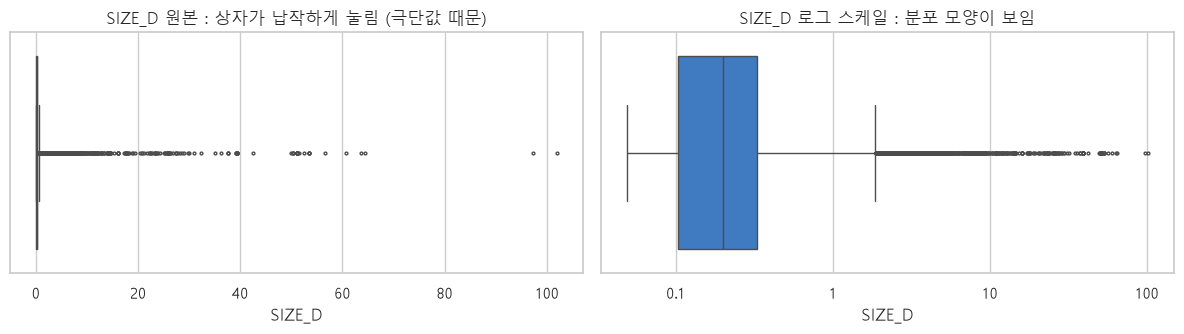

> **결과 해석**
> - `SIZE_D`, `DEFECT_AREA`는 IQR 기준 이상치가 **약 9~12%** 입니다. 이 정도면 '오류'라기보다 **오른쪽 꼬리가 긴(우편향) 분포**의 특성입니다.
> - 같은 변수라도 **IQR 규칙과 Z-점수의 이상치 개수가 크게 다릅니다.** 치우친 분포에서는 표준편차가 극단값 때문에 커져서 Z-점수가 이상치를 덜 잡습니다.
> 
> **제조 데이터의 이상치는 '지울 대상'이 아니라 '살펴볼 대상'** 입니다. 큰 결함(스크래치, 파티클 덩어리)이야말로 수율에 치명적일 수 있습니다. → **삭제하지 않고 플래그만 남깁니다.**

**실습 프롬프트 P26**

> 앞에서 만든 iqr_outlier 함수로 SIZE_D의 IQR 상한을 구하고,
>
> 상한보다 큰 결함은 1, 아니면 0인 big_defect 열을 df에 추가해줘. 해당 건수를 출력해줘.

SIZE_D 상한 0.671µm 초과 → 대형 결함 플래그 5,690건


#### 심화 해설 · 이상치 기준을 바꾸면 결론은 얼마나 달라질까?

**① 분석 목적**

큰 결함을 삭제하지 않고, 평균이 꼬리에 얼마나 의존하는지 확인합니다.

**② 개념을 먼저 이해하기**

이상치는 다른 값과 멀리 떨어진 관측입니다. 측정 오류와 동의어가 아닙니다.
IQR 경계는 가운데 50% 폭을 기준으로 표시하는 탐색 규칙이며 공정 규격이나 불량 판정 기준이 아닙니다.
상위 1%는 값의 순위 기준이고 1µm 초과는 물리 단위 기준입니다. 동점이 있으면 분위수 초과 행 비율이 정확히 1%가 아닐 수 있습니다.

,조건,n,평균,중앙값,표준편차
0,전체,63908,0.3971,0.1990,1.6473
1,IQR 상한 이하만 (비교용),58218,0.2189,0.1990,0.1448
2,99백분위수 이하만 (비교용),63270,0.2939,0.1990,0.3215


IQR 상한=0.6715 µm, 초과 기록=5,690개
상위 1% 경계 초과 값의 크기 합 / 전체 크기 합 = 26.71%


**③ 표·그래프 읽는 순서**

전체와 제한 표본의 n을 먼저 비교하고 평균·중앙값·표준편차가 얼마나 움직였는지 봅니다.

**④ 결과 해석과 한계**

원자료 평균은 약 0.3971µm, 중앙값은 0.1990µm입니다. 꼬리 제한 후 평균이 작아지는 것은 제거된 값이 컸기 때문이며, 품질이 개선되었다는 뜻이 아닙니다.

### 3-7. 파생변수 만들기 (Feature Engineering)

| 파생변수 | 만드는 법 | 목적 |
|---|---|---|
| `Wafer_ID` | 공정 + 로트 + 슬롯 | 웨이퍼 단위 집계 |
| `ASPECT` | SIZE_X / SIZE_Y | 결함 모양 (1=정사각형) |
| `X_mm`, `Y_mm` | 극좌표(RADIUS, ANGLE) → 직교좌표 | **웨이퍼 맵** 그리기 |
| `ZONE` | RADIUS 구간화 | 중심 / 중간 / 외곽 / 가장자리 비교 |
| `SIZE_GRADE` | SIZE_D 구간화 | 순서형 범주 만들기 |

**실습 프롬프트 P27**

> df에 파생변수 5개를 만들어줘.
> 1. Wafer_ID : Step_desc, Lot_Name, Slot_No를 '_'로 이은 문자열 (범주형이면 문자열로 바꿔서 연결)
> 2. ASPECT : SIZE_X / SIZE_Y
> 3. X_mm, Y_mm : RADIUS(µm)와 ANGLE(도)을 직교좌표로 변환하고 mm 단위로
> 4. ZONE : RADIUS(mm)를 [0,50,100,130,150] 구간으로 나누고 라벨은 '중심(0-50)', '중간(50-100)', '외곽(100-130)', '가장자리(130-150)'
> 5. SIZE_GRADE : SIZE_D를 [0, 0.1, 0.3, 1, 무한대]로 나누고 라벨은 '극소(≤0.1)', '소(0.1-0.3)', '중(0.3-1)', '대(>1)'
>
> 웨이퍼 수를 출력하고, 새로 만든 열들의 앞 5행을 보여줘.

웨이퍼 수: 1092 장


,Wafer_ID,ASPECT,X_mm,Y_mm,ZONE,SIZE_GRADE
0,PC_F00BK.JO_19,1.0000,142.9040,-9.9928,가장자리(130-150),소(0.1-0.3)
1,PC_F00BK.JO_19,0.8588,5.5092,-8.1677,중심(0-50),중(0.3-1)
2,PC_F00BK.JO_19,1.0000,113.2029,-13.8996,외곽(100-130),극소(≤0.1)
3,PC_F00BK.JO_19,1.0000,106.5509,-14.9747,외곽(100-130),소(0.1-0.3)
4,PC_F00BK.JO_19,0.5000,143.8755,-17.6657,가장자리(130-150),소(0.1-0.3)


#### 심화 해설 · 구간 경계에 정확히 걸리는 값 확인하기

**① 분석 목적**

0, 50, 100 같은 경계값이 누락되거나 의도와 다른 구간에 들어가지 않도록 합니다.

**② 개념을 먼저 이해하기**

`pd.cut`의 기본 구간은 (a, b]로 왼쪽을 제외하고 오른쪽을 포함합니다.
`include_lowest=True`는 첫 구간의 가장 작은 값도 포함합니다. 구간 밖 값은 NaN이 되므로 구간화 뒤 누락 수를 검산합니다.
공정별 ID는 집계 편의를 위한 정의입니다. 같은 물리 웨이퍼의 서로 다른 공정 기록은 별도 관측 그룹이 될 수 있습니다.

,반경_mm,구간
0,0.0000,"(-0.001, 50.0]"
1,50.0000,"(-0.001, 50.0]"
2,50.0010,"(50.0, 100.0]"
3,100.0000,"(50.0, 100.0]"
4,130.0000,"(100.0, 130.0]"
5,150.0000,"(130.0, 150.0]"
6,151.0000,NaN


실제 ZONE 누락: 0
실제 SIZE_GRADE 누락: 0
구간별 기록 합: 63908 / 전체: 63908


**③ 표·그래프 읽는 순서**

50은 첫 구간, 50.001은 다음 구간에 들어갑니다. 151은 웨이퍼 반경 가정 밖이므로 NaN입니다.

**④ 결과 해석과 한계**

ZONE 누락이 있다면 전체를 분모로 한 비율과 구간에 포함된 행만 분모로 한 비율이 달라집니다. 제외된 행 수를 반드시 밝힙니다.

### 3-8. 변환과 스케일링

| 기법 | 공식 | 언제? |
|---|---|---|
| **로그 변환** | $x' = \log_{10}(x)$ | 오른쪽 꼬리가 긴(우편향) 분포를 대칭에 가깝게 |
| **표준화** (Z-score) | $x' = \dfrac{x - \bar{x}}{s}$ → 평균 0, 표준편차 1 | 단위가 다른 변수를 비교할 때 |
| **정규화** (Min-Max) | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ → 0~1 | 범위를 맞추고 싶을 때 (이상치에 민감) |

**실습 프롬프트 P28**

> SIZE_D와 DEFECT_AREA에 log10 변환을 적용한 log_SIZE_D, log_AREA 열을 만들어줘.
>
> DEFECT_AREA는 0이 있으니 0.0001을 더한 뒤 변환해줘.
>
> 그리고 SIZE_D 변환 전/후 히스토그램을 1행 2열로 나란히 그리고, 각 제목에 왜도(skew) 값을 넣어줘.

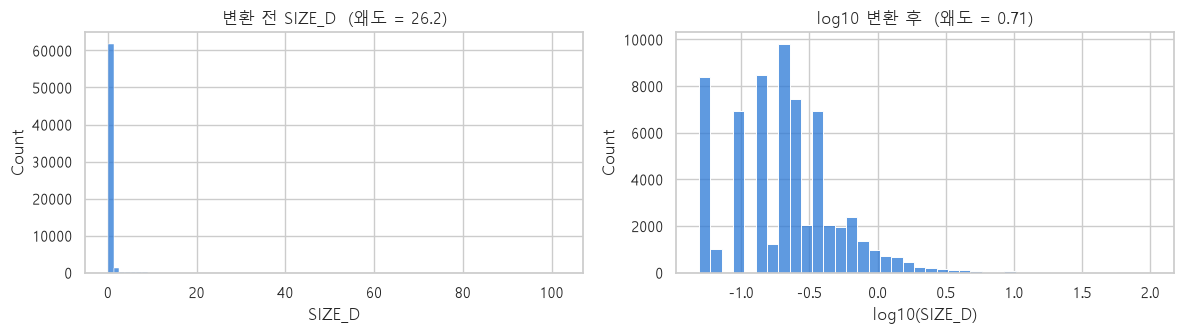

**실습 프롬프트 P29**

> INTENSITY 열에 표준화(Z-score)와 Min-Max 정규화를 각각 적용하고,
>
> 원본/표준화/정규화 세 열의 평균, 표준편차, 최솟값, 최댓값을 한 표로 비교해줘.

,원본,표준화,정규화(Min-Max)
mean,412.4460,0.0000,0.1147
std,364.7668,1.0000,0.1015
min,0.0000,-1.1307,0.0000
max,"3,595.0000",8.7249,1.0000


#### 심화 해설 · 로그 축·로그 변환·표준화는 서로 다르다

**① 분석 목적**

그림의 눈금과 통계 계산에 사용하는 값을 구분합니다.

**② 개념을 먼저 이해하기**

로그 축은 원래 값 0.1, 1, 10을 같은 간격에 배치합니다. 로그 변환은 값 자체를 −1, 0, 1로 바꿉니다.
평균(log10 x)을 원단위로 되돌린 10**평균(log10 x)은 기하평균이며 산술평균과 다릅니다.
표준화는 위치와 단위를 바꾸지만 원래 분포를 정규분포로 만들지 않습니다. 로그 변환도 정규성을 보장하지 않습니다.

,SIZE_D,log10(SIZE_D)
0,0.1000,-1.0000
1,1.0000,0.0000
2,10.0000,1.0000


산술평균=0.3971, 기하평균=0.2078, 중앙값=0.1990 µm
원본 왜도=26.151, 로그 변환 왜도=0.714
표준화 후 왜도=26.151


**③ 표·그래프 읽는 순서**

원본과 표준화 후 왜도는 같고 로그 변환 후 왜도는 달라지는지 확인합니다.

**④ 결과 해석과 한계**

보고할 때 평균이 원단위 평균인지 로그 평균인지 명시합니다. 0을 포함하는 변수에 임의 상수를 더하면 특히 작은 값의 관계가 바뀔 수 있습니다.

> **결과 해석**
> - 로그 변환 후 왜도가 **약 26 → 0.7**로 크게 줄어 분포가 대칭에 가까워졌습니다.
> - 표준화 → 평균 0, 표준편차 1 / 정규화 → 최솟값 0, 최댓값 1. **분포의 모양은 그대로, 눈금(scale)만 바뀝니다.**

**실습 프롬프트 P30**

> 전처리가 끝난 df의 최종 크기, 원본 대비 추가된 파생변수 개수, 삭제된 행 수를 출력해줘.

최종 데이터 크기 : (63908, 35)  (원본 (63908, 25) → 파생변수 10개 추가)
삭제된 행        : 0개


---

## 4장. 기술통계 (Descriptive Statistics) — 강화판

> **이 장의 목표**
> - 도수분포표를 만들고 해석할 수 있다.
> - 중심경향·산포·위치·형태 통계량을 공식으로 이해하고 코드로 직접 계산할 수 있다.
> - 평균·표준편차가 이상치에 약하다는 것을 알고, 로버스트 통계량(중앙값·IQR·MAD)을 선택할 수 있다.
> - 두 변수의 관계를 교차표·공분산·상관계수·결정계수로 요약할 수 있다.
> - 표본과 모집단, 표준오차의 의미를 실험으로 이해한다.

### 4-0. 통계의 두 갈래

| 구분 | **기술통계** (Descriptive) | 추론통계 (Inferential) |
|---|---|---|
| 목적 | 가진 데이터를 **요약·정리·묘사** | 표본으로 **모집단을 추정·검정** |
| 질문 | "우리 데이터는 어떻게 생겼나?" | "이 차이가 우연이 아닌가?" |
| 도구 | 도수분포표, 평균, 표준편차, 사분위수, 그래프 | 신뢰구간, t-검정, 회귀분석 |
| 이 과정 | **집중 학습** | 4-11에서 '다리'만 놓기 |

### 4-1. 기술통계량 지도

| 범주 | 통계량 | 질문 | 이상치에 강한가? |
|---|---|---|:---:|
| **⓪ 자료 정리** | 도수분포표, 상대도수, 누적도수 | 값들이 **어떻게 분포**? | — |
| **① 중심경향** | 평균, 가중평균, 절사평균, **중앙값**, 최빈값 | 데이터의 **중심**은? | 중앙값 O / 평균 X |
| **② 산포도** | 범위, 분산, 표준편차, 변동계수, **IQR, MAD** | 얼마나 **퍼져** 있나? | IQR·MAD O / 표준편차 X |
| **③ 위치** | 백분위수, 사분위수, Z-점수, 5가지 요약 | 특정 값은 **어디쯤**? | 백분위수 O |
| **④ 분포 형태** | 왜도, 첨도, Q-Q plot | 분포가 **어떤 모양**? | — |
| **⑤ 관계** | 교차표, 공분산, 상관계수, 결정계수 | 두 변수가 **함께 움직이나**? | 스피어만 O / 피어슨 X |
| **⑥ 표본** | 표본평균, 표준오차 | 표본 통계량은 **얼마나 믿을 만**? | — |

### 4-2. 한 번에 보기 — `describe()`

**실습 프롬프트 P31**

> df의 주요 수치형 변수 12개(SIZE_X, SIZE_Y, SIZE_D, DEFECT_AREA, INTENSITY, ENERGY_PARAM,
>
> MDAT_GL, MDAT_NOISE, SPOTLIKENESS, PATCHNOISE, ACTIVERATIO, RADIUS)의 요약 통계를
>
> 변수가 행으로 오도록 전치해서 보여줘. 변수 리스트는 stat_cols로 저장해줘.

,count,mean,std,min,25%,50%,75%,max
SIZE_X,"63,908.0000",0.3032,1.4009,0.0490,0.0990,0.1570,0.2650,101.9980
SIZE_Y,"63,908.0000",0.3170,1.0059,0.0490,0.0990,0.1980,0.2980,60.6270
SIZE_D,"63,908.0000",0.3971,1.6473,0.0490,0.1040,0.1990,0.3310,101.9980
DEFECT_AREA,"63,908.0000",0.0973,1.4771,0.0000,0.0014,0.0034,0.0082,93.0068
INTENSITY,"63,908.0000",412.4460,364.7668,0.0000,194.0000,316.0000,509.0000,"3,595.0000"
ENERGY_PARAM,"63,908.0000","1,560.2735","1,412.4950",0.0000,744.0000,"1,196.0000","1,874.0000","21,723.0000"
MDAT_GL,"63,908.0000","1,858.1809",919.1933,187.0000,961.0000,"1,962.0000","2,612.0000","4,095.0000"
MDAT_NOISE,"63,908.0000",236.1825,185.8009,4.0000,133.0000,196.0000,291.0000,"3,843.0000"
SPOTLIKENESS,"63,908.0000",7.0460,3.2255,0.0467,4.7945,6.8512,8.8202,31.7792
PATCHNOISE,"63,908.0000",64.8128,77.5276,1.1321,26.9514,41.7637,70.3445,"1,414.0817"


**실습 프롬프트 P32**

> 범주형 변수 Step_desc, Lot_Name, Class, IS_DEFECT, POLARITY의 요약(개수, 고유값 수, 최빈값, 최빈값 빈도)을 보여줘.

,count,unique,top,freq
Step_desc,63908,3,CBCMP,28072
Lot_Name,63908,457,F046T.1,781
Class,63908,11,9,28060
IS_DEFECT,63908,2,REAL,35848
POLARITY,63908,3,1,47146


### 4-3. ⓪ 도수분포표 (Frequency Distribution Table) — 자료 정리의 첫걸음

수치형 데이터를 **구간(계급, class interval)** 으로 나누고 각 구간에 몇 개가 들어가는지 세어 정리한 표입니다. **히스토그램은 도수분포표를 그림으로 그린 것**입니다.

| 용어 | 의미 |
|---|---|
| **계급** (Class) | 값을 나눈 구간 |
| **도수** (Frequency) | 각 구간에 속한 관측치 수 |
| **상대도수** (Relative Freq.) | 도수 ÷ 전체 개수 (비율) |
| **누적도수** (Cumulative Freq.) | 처음 구간부터 해당 구간까지 도수의 합 |
| **계급값** (Midpoint) | 구간의 가운데 값 |

> **구간은 몇 개로?** — **스터지스(Sturges) 규칙** : $k = 1 + \log_2 n$  (n = 데이터 개수)

**실습 프롬프트 P33**

> INTENSITY 변수로 도수분포표를 만들어줘.
> 1. 스터지스 규칙 k = 1 + log2(n)으로 구간 수를 계산해서 출력 (올림)
> 2. 0부터 2000까지를 200 간격으로 나누고, 2000 이상은 마지막 구간 하나로 묶어줘.
> 3. 구간별 도수, 계급값, 상대도수(%), 누적도수, 누적상대도수(%)를 한 표로 보여줘.

데이터 수 n = 63,908  →  스터지스 권장 구간 수 k = 17


,도수,계급값,상대도수(%),누적도수,누적상대도수(%)
INTENSITY,,,,,
"[0.0, 200.0)",17143,100.0000,26.8200,17143,26.8200
"[200.0, 400.0)",23556,300.0000,36.8600,40699,63.6800
"[400.0, 600.0)",11428,500.0000,17.8800,52127,81.5700
"[600.0, 800.0)",5875,700.0000,9.1900,58002,90.7600
"[800.0, 1000.0)",2324,900.0000,3.6400,60326,94.4000
"[1000.0, 1200.0)",1069,"1,100.0000",1.6700,61395,96.0700
"[1200.0, 1400.0)",625,"1,300.0000",0.9800,62020,97.0500
"[1400.0, 1600.0)",521,"1,500.0000",0.8200,62541,97.8600
"[1600.0, 1800.0)",428,"1,700.0000",0.6700,62969,98.5300


**실습 프롬프트 P34**

> 방금 만든 도수분포표(freq_tbl)를 그래프로 그려줘. 1행 2열로
>
> 왼쪽은 구간별 상대도수(%) 막대그래프(히스토그램 형태), 오른쪽은 누적상대도수(%) 꺾은선 그래프(오자이브 곡선)야.
>
> 오른쪽 그래프에는 50% 지점에 점선을 그어 중앙값이 어느 구간에 있는지 보이게 해줘.

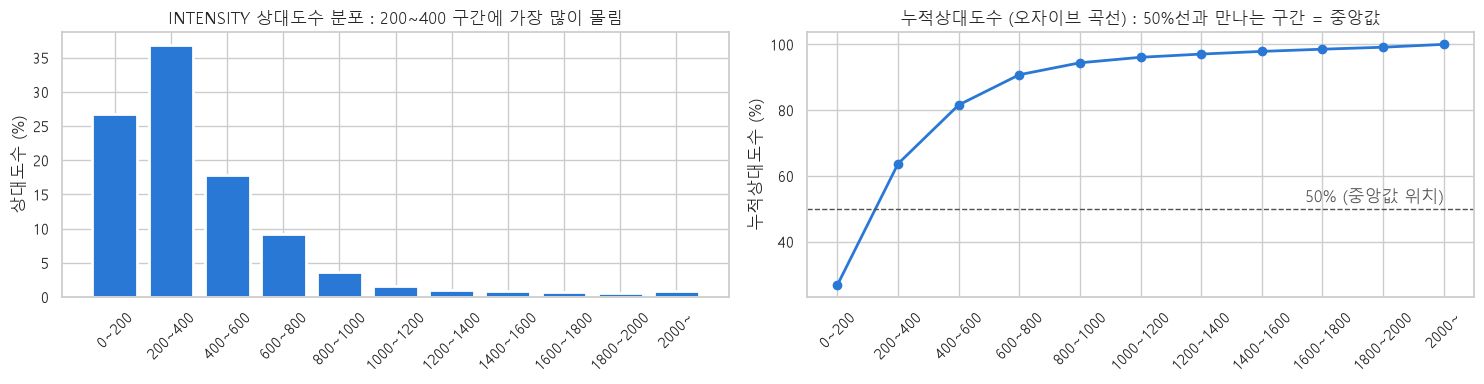

> **결과 해석**
> - 스터지스 규칙은 **출발점**일 뿐입니다. 데이터가 크고 치우쳐 있으면 해석하기 쉬운 간격(예: 200 단위)으로 조정하는 것이 실무적입니다.
> - 누적상대도수가 **50%를 넘는 구간 = 중앙값이 속한 구간**, 25%·75%를 넘는 구간 = Q1·Q3이 속한 구간입니다. 도수분포표만으로도 위치 통계량의 대략적인 값을 알 수 있습니다.

#### 심화 해설 · 누적분포 ECDF로 “이 크기 이하가 몇 %인가” 읽기

**① 분석 목적**

히스토그램 구간 선택에 의존하지 않고 실제 기록의 누적 비율을 확인합니다.

**② 개념을 먼저 이해하기**

경험적 누적분포 F(x)는 값이 x 이하인 관측 수를 전체 관측 수로 나눈 것입니다.
정렬된 값마다 1/n씩 증가하는 계단 모양이며, 같은 값이 여러 번 있으면 더 크게 뜁니다.
히스토그램은 어느 구간에 몰렸는지, ECDF는 특정 기준 이하가 몇 %인지 답합니다.

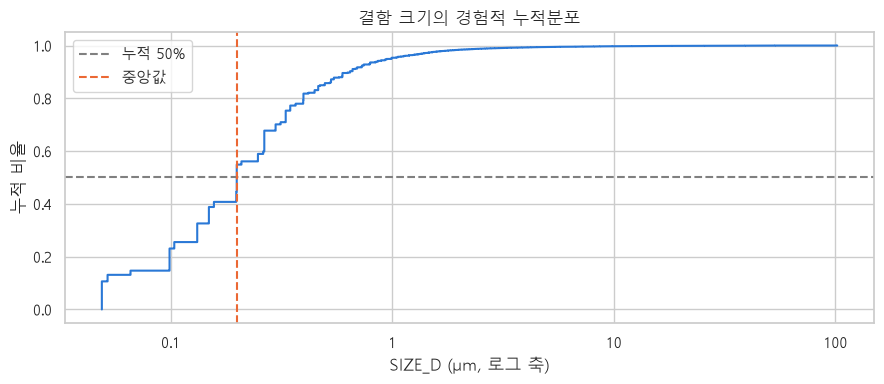

0.1 µm 이하: 14,756개, 23.09%
0.3 µm 이하: 44,818개, 70.13%
1 µm 이하: 60,950개, 95.37%


**③ 표·그래프 읽는 순서**

x축에서 0.3을 찾아 위로 올라간 뒤 y축을 읽으면 0.3µm 이하 비율입니다. y=0.5에서 만나는 x는 중앙값 부근입니다.

**④ 결과 해석과 한계**

급하게 올라가는 구간은 값이 많이 모여 있습니다. 평평한 구간은 관측값이 드뭅니다. 이 자료의 누적 비율이지 미래 생산분의 보장 비율은 아닙니다.

### 4-4. ① 중심경향 (Central Tendency)

| 통계량 | 공식 / 정의 | 장점 | 단점 |
|---|---|---|---|
| **평균** (Mean) | $\bar{x} = \dfrac{1}{n}\sum x_i$ | 모든 값을 반영 | **이상치에 민감** |
| **중앙값** (Median) | 정렬했을 때 가운데 값 | **이상치에 강함(robust)** | 값의 크기 정보 일부 손실 |
| **최빈값** (Mode) | 가장 자주 나오는 값 | **범주형에도** 사용 가능 | 여러 개이거나 의미 없을 수 있음 |
| **절사평균** (Trimmed Mean) | 양 끝 일부(예: 5%)를 잘라낸 평균 | 평균과 중앙값의 절충 | 자르는 비율을 정해야 함 |
| **가중평균** (Weighted Mean) | $\bar{x}_w = \dfrac{\sum w_i x_i}{\sum w_i}$ | 그룹 크기를 반영 | 가중치 선택이 중요 |

#### 공식 → 코드로 직접 계산하기

**실습 프롬프트 P35**

> SIZE_D의 평균, 중앙값, 최빈값, 5% 절사평균을 pandas 함수 없이 공식대로 직접 계산해줘.
> - 평균: 합 / 개수
> - 중앙값: 정렬 후 가운데 값 (개수가 짝수면 가운데 두 값의 평균)
> - 최빈값: value_counts의 최댓값 인덱스
> - 5% 절사평균: 정렬 후 양쪽 5%씩 버리고 평균
>
> 그리고 pandas 내장 함수(mean, median, mode) 결과와 나란히 비교하는 표로 보여줘.

,직접 계산,pandas
평균,0.3971,0.3971
중앙값,0.1990,0.1990
최빈값,0.0490,0.0490
5% 절사평균,0.2535,NaN


**실습 프롬프트 P36**

> SIZE_D가 2 미만인 구간의 히스토그램을 그리고, 평균·중앙값·최빈값 위치에
>
> 서로 다른 선 스타일(실선, 점선, 점점선)로 세로선을 그어줘. 선 옆에 이름과 값을 표시하고,
>
> 제목은 '최빈값 < 중앙값 < 평균 → 오른쪽 꼬리(우편향)'로 해줘. 라벨이 제목과 겹치지 않게 y축 위쪽 여백을 늘려줘.

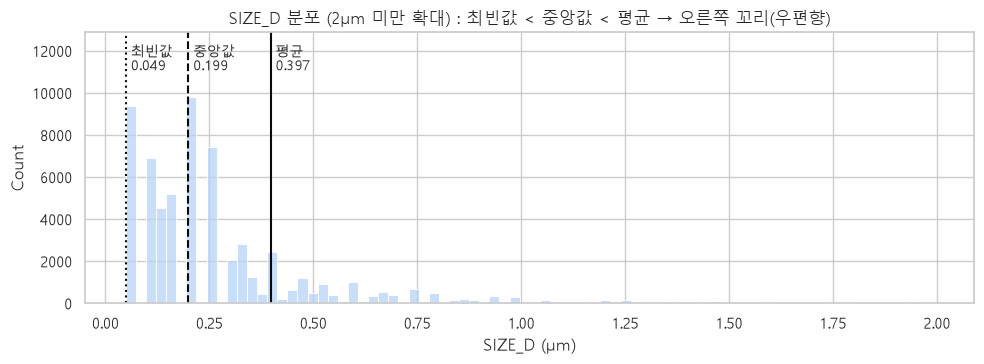

| 분포 모양 | 대소 관계 |
|---|---|
| 좌우 대칭 | 평균 ≈ 중앙값 ≈ 최빈값 |
| 오른쪽 꼬리 (우편향, 양의 왜도) | 최빈값 < 중앙값 < **평균** |
| 왼쪽 꼬리 (좌편향, 음의 왜도) | **평균** < 중앙값 < 최빈값 |

#### 실험 ① 이상치 1개가 평균과 중앙값에 미치는 영향

**실습 프롬프트 P37**

> SIZE_D 앞의 10개 값으로 실험해줘. 원래 10개의 평균·중앙값과,
>
> 여기에 100µm짜리 이상치 1개를 추가한 11개의 평균·중앙값을 비교하는 표를 만들고
>
> '변화배수' 열(추가 후 / 원래)도 넣어줘.

,원래 10개,+ 이상치 1개,변화배수
평균,0.2280,9.2980,40.7640
중앙값,0.2230,0.2480,1.1120


> **결과 해석**
> 이상치 **단 1개**로 평균은 약 40배 커졌지만 중앙값은 거의 그대로입니다. 이것이 **중앙값이 '로버스트(robust)'하다**는 뜻입니다.

#### 심화 해설 · 아주 작은 숫자로 평균·중앙값 손계산하기

**① 분석 목적**

큰 데이터에서 계산한 통계량의 원리를 다섯 개 숫자로 확인합니다.

**② 개념을 먼저 이해하기**

교육용 값 [1, 2, 2, 3, 12]의 합은 20이므로 평균은 4입니다. 정렬 후 가운데 값은 2입니다.
편차 합은 0이어서 퍼짐을 측정할 수 없습니다. 제곱하면 부호가 사라지고 큰 편차가 더 큰 영향을 줍니다.
분산의 단위는 원래 단위의 제곱, 표준편차의 단위는 원래 단위입니다.

,값,평균에서 편차,편차 제곱,중앙값에서 절대거리
0,1.0000,-3.0000,9.0000,1.0000
1,2.0000,-2.0000,4.0000,0.0000
2,2.0000,-2.0000,4.0000,0.0000
3,3.0000,-1.0000,1.0000,1.0000
4,12.0000,8.0000,64.0000,10.0000


평균: 4.0 중앙값: 2.0
제곱합: 82.0 표본분산: 20.5
표준편차: 4.527692569068709 MAD: 1.0


**③ 표·그래프 읽는 순서**

12의 편차 제곱이 다른 값보다 얼마나 큰지 봅니다. 표본분산은 78/4=19.5, 표준편차는 약 4.416입니다.

**④ 결과 해석과 한계**

중앙값은 전형적인 한 관측의 위치를, 평균은 모든 값의 크기를 반영합니다. 한 지표가 항상 우월한 것은 아니며 질문에 맞게 둘 다 보고합니다.

#### 실험 ② 가중평균 — "평균의 평균"의 함정

웨이퍼마다 결함 수가 다릅니다. **"웨이퍼별 진성결함 비율의 평균"** 과 **"전체 결함 중 진성결함 비율"** 은 같을까요?

$$\text{단순평균} = \frac{1}{m}\sum_{j=1}^{m} p_j \qquad \text{가중평균} = \frac{\sum_j n_j\, p_j}{\sum_j n_j} = \frac{\text{전체 진성결함 수}}{\text{전체 결함 수}}$$

**실습 프롬프트 P38**

> Wafer_ID별로 결함 수(n)와 진성결함 비율(p)을 구해줘.
>
> 그리고 공정(Step_desc)별로 아래 세 값을 비교하는 표를 만들어줘.
> 1. 단순평균: 웨이퍼별 진성비율 p의 단순 평균
> 2. 가중평균: 결함 수 n을 가중치로 한 p의 가중평균 (np.average 사용)
> 3. 전체비율: 해당 공정 전체 결함 중 진성결함의 비율 (is_real 평균)
>
> 가중평균과 전체비율이 같은지 확인할 수 있게 소수점 4자리로 보여줘.

,웨이퍼 수,단순평균 (Σp/m),가중평균 (Σnp/Σn),전체비율 (결함 기준)
PC,168.0000,0.3426,0.3285,0.3285
RMG,467.0000,0.5436,0.5305,0.5305
CBCMP,457.0000,0.6671,0.6634,0.6634


> **결과 해석**
> - **가중평균 = 전체비율**로 정확히 일치합니다. 반면 **단순평균은 약 0.4~1.4%p 높게** 나옵니다. 결함 수가 적은 웨이퍼도 많은 웨이퍼와 같은 무게로 계산되기 때문입니다.
> - **"웨이퍼 1장의 전형적인 진성비율"** 이 궁금하면 단순평균, **"전체 결함 중 진성 비율"** 이 궁금하면 가중평균. **질문에 따라 평균을 고르세요.** (공장별 불량률을 합칠 때 흔히 하는 실수입니다!)

#### 심화 해설 · 집계 단위가 달라지면 평균의 의미가 달라진다

**① 분석 목적**

결함 후보 하나를 무작위로 고르는 질문과 웨이퍼 그룹 하나를 고르는 질문을 구별합니다.

**② 개념을 먼저 이해하기**

기록이 10개인 그룹과 100개인 그룹의 진성 비율을 단순 평균하면 두 그룹의 가중치가 같습니다.
전체 기록 중 진성 비율을 구하려면 각 그룹의 기록 수를 가중치로 써야 합니다.
둘의 차이는 계산 오류가 아니라 추정 대상이 다르기 때문입니다.

관측 그룹별 비율의 단순평균: 56.4396%
기록 수 가중평균: 56.0931%
전체 기록 중 REAL: 56.0931%


**③ 표·그래프 읽는 순서**

두 번째와 세 번째 값은 계산식상 같습니다. 첫 번째와의 차이를 %p로 설명해 보세요.

**④ 결과 해석과 한계**

관측되지 않은 무결함 웨이퍼는 여기 포함되지 않습니다. 그룹 평균도 전체 생산 웨이퍼 평균으로 일반화할 수 없습니다.

### 4-5. ② 산포도 (Dispersion) — 얼마나 퍼져 있는가?

| 통계량 | 공식 | 의미 | 이상치 |
|---|---|---|:---:|
| **범위** (Range) | $x_{max} - x_{min}$ | 극단값 2개에만 의존 | X |
| **분산** (Variance) | $s^2 = \dfrac{1}{n-1}\sum (x_i - \bar{x})^2$ | 편차 제곱의 평균 (단위가 제곱됨) | X |
| **표준편차** (Std) | $s = \sqrt{s^2}$ | 원래 단위의 퍼짐 정도 | X |
| **변동계수** (CV) | $\dfrac{s}{\bar{x}} \times 100\%$ | **단위가 다른** 변수끼리 비교 | X |
| **사분위범위** (IQR) | $Q_3 - Q_1$ | 가운데 50%의 폭 | O |
| **평균절대편차** (Mean AD) | $\dfrac{1}{n}\sum \lvert x_i - \bar{x} \rvert$ | 평균에서 떨어진 거리의 평균 | △ |
| **중앙값절대편차** (MAD) | $\text{median}(\lvert x_i - \tilde{x} \rvert)$ | 중앙값에서 떨어진 거리의 중앙값 | O |

> **왜 n−1로 나눌까?** 표본의 편차는 '표본평균'을 기준으로 계산하므로 실제(모집단)보다 약간 작게 나옵니다. n−1로 나눠 이를 보정합니다(**자유도**). pandas `var()`, `std()`의 기본값이 n−1(`ddof=1`), numpy `np.var()`의 기본값은 n(`ddof=0`)이니 주의!

**실습 프롬프트 P39**

> INTENSITY로 분산과 표준편차를 공식대로 직접 계산해줘.
> 1. 편차(값 - 평균)를 구하고, 편차의 합이 0이 되는 것을 확인
> 2. 분산 = 편차 제곱합 / (n-1), 표준편차 = 분산의 제곱근
> 3. pandas var(), std()와 비교 출력
> 4. n으로 나눈 분산(ddof=0)과 n-1로 나눈 분산(ddof=1)의 차이도 출력

편차의 합       : 0.000000  ← 항상 0 (그래서 '제곱'해서 더함)
분산 (직접)     : 133,054.85   |  pandas var() : 133,054.85
표준편차 (직접) : 364.77     |  pandas std() : 364.77

[자유도 비교] n으로 나눔(ddof=0) : 133,052.77  vs  n-1로 나눔(ddof=1) : 133,054.85
→ 데이터가 6만 개 이상이면 차이는 거의 없지만, 표본이 작을수록 차이가 커집니다.


**실습 프롬프트 P40**

> 산포도 통계량을 한 번에 계산하는 dispersion(s) 함수를 만들어줘.
>
> 평균, 범위, 분산, 표준편차, IQR, 평균절대편차, MAD(중앙값절대편차), 변동계수 CV(%)를 Series로 반환해.
>
> SIZE_D, INTENSITY, MDAT_NOISE, MDAT_GL, SPOTLIKENESS, RADIUS에 적용해서
>
> CV가 큰 순서로 정렬된 표를 소수점 2자리로 보여줘.

,평균,범위,분산,표준편차,IQR,평균절대편차,MAD(중앙값절대편차),변동계수CV(%)
SIZE_D,0.4000,101.9500,2.7100,1.6500,0.2300,0.3500,0.1000,414.8600
INTENSITY,412.4500,"3,595.0000","133,054.8500",364.7700,315.0000,240.3100,138.0000,88.4400
MDAT_NOISE,236.1800,"3,839.0000","34,521.9600",185.8000,158.0000,108.2600,71.0000,78.6700
MDAT_GL,"1,858.1800","3,908.0000","844,916.4000",919.1900,"1,651.0000",835.4300,840.0000,49.4700
SPOTLIKENESS,7.0500,31.7300,10.4000,3.2300,4.0300,2.4200,2.0100,45.7800
RADIUS,"101,625.0600","146,669.0000","1,485,686,245.9400","38,544.6000","59,309.5000","32,421.8100","25,465.0000",37.9300


> **결과 해석**
> - 표준편차만 보면 `RADIUS`(약 38,500)가 가장 커 보이지만, 이는 **단위(µm)가 커서**일 뿐입니다.
> - **변동계수(CV)** 로 비교하면 `SIZE_D`가 평균 대비 **400% 이상** 흩어져 가장 들쭉날쭉하고, `RADIUS`는 약 38%로 비교적 고르게 분포합니다. **의미 있는 절대 영점과 양의 평균을 갖는 변수에서만 CV를 비교!**
> - `SIZE_D`의 표준편차(1.65)는 IQR(0.23)·MAD(0.10)보다 훨씬 큽니다. **극단값 몇 개가 표준편차를 부풀린 것**입니다.

#### 로버스트 산포와 수정 Z-점수

표준편차는 이상치에 약하기 때문에, 이상치를 찾는 데 표준편차를 쓰면 **이상치가 스스로를 숨기는** 문제(masking)가 생깁니다. 중앙값과 MAD를 쓰면 이 문제가 줄어듭니다.

$$M_i = \frac{0.6745 \times (x_i - \tilde{x})}{MAD}, \qquad |M_i| > 3.5 \text{ 이면 이상치}$$

> 0.6745를 곱하는 이유 : 정규분포에서 **MAD ≈ 0.6745 × σ** 이므로, 이렇게 하면 일반 Z-점수와 같은 눈금이 됩니다.

**실습 프롬프트 P41**

> SIZE_D, INTENSITY, MDAT_NOISE, SPOTLIKENESS, PATCHNOISE 각각에 대해
>
> 세 가지 방법으로 이상치 개수와 비율(%)을 비교하는 표를 만들어줘.
> 1. Z-점수 |z| > 3
> 2. 수정 Z-점수 |0.6745*(x-중앙값)/MAD| > 3.5
> 3. IQR 규칙 (Q1-1.5IQR, Q3+1.5IQR)
>
> 이상치 개수 열 3개와, 전체 대비 비율(%) 열 3개를 만들어줘.

,Z>3 개수,수정Z>3.5 개수,IQR규칙 개수,Z>3 (%),수정Z>3.5 (%),IQR규칙 (%)
SIZE_D,341.0000,"5,273.0000","5,690.0000",0.5300,8.2500,8.9000
INTENSITY,"1,593.0000","3,355.0000","3,711.0000",2.4900,5.2500,5.8100
MDAT_NOISE,"1,054.0000","2,252.0000","2,622.0000",1.6500,3.5200,4.1000
SPOTLIKENESS,"1,029.0000",910.0000,"1,547.0000",1.6100,1.4200,2.4200
PATCHNOISE,"1,144.0000","6,578.0000","6,649.0000",1.7900,10.2900,10.4000


> **결과 해석**
> - 심하게 치우친 변수(`SIZE_D`, `PATCHNOISE`)에서 **Z-점수는 이상치를 0.5~1.8%** 만 잡지만, 로버스트 방법(수정 Z, IQR)은 **8~10%** 를 잡습니다. 극단값이 표준편차를 키워 스스로를 숨기기 때문입니다(masking).
> - 반대로 대칭에 가까운 `SPOTLIKENESS`는 세 방법의 결과가 비슷합니다.
> - **방법마다 "이상치" 개수가 다릅니다.** 이상치는 정답이 있는 개념이 아니라 **"어떤 기준을 썼는가"** 를 함께 보고해야 하는 값입니다.

#### 심화 해설 · 산포 지표를 고르는 기준과 0으로 나누는 문제

**① 분석 목적**

표준편차·IQR·MAD·CV의 해석 조건을 확인합니다.

**② 개념을 먼저 이해하기**

IQR은 가운데 50%의 폭, MAD는 중앙값에서 떨어진 거리의 중앙값입니다. 둘의 수치가 같아야 할 이유는 없습니다.
CV는 표준편차/평균이며 절대 영점이 의미 있고 평균이 양수인 비율척도에서 유용합니다. 평균이 0에 가까우면 불안정합니다.
MAD=0이면 수정 Z점수를 계산할 수 없습니다. 이런 경우 임의의 아주 작은 수로 나누기보다 계산 불가를 알립니다.

,변수,평균,SD,Q1,중앙값,Q3,IQR,MAD,CV(%)
0,SIZE_D,0.3971,1.6473,0.1040,0.1990,0.3310,0.2270,0.1000,414.8607
1,INTENSITY,412.4460,364.7668,194.0000,316.0000,509.0000,315.0000,138.0000,88.4399
2,MDAT_GL,"1,858.1809",919.1933,961.0000,"1,962.0000","2,612.0000","1,651.0000",840.0000,49.4674


교육용 예제의 MAD: 0.0


**③ 표·그래프 읽는 순서**

SIZE_D의 표준편차가 IQR보다 큰 정도를 비교합니다. 마지막 예제는 8이라는 큰 값이 있어도 MAD가 0입니다.

**④ 결과 해석과 한계**

CV가 크다고 장비가 불안정하다고 바로 결론 내리지 않습니다. 서로 다른 크기의 결함을 섞은 구성 차이일 수 있습니다.

#### 경험적 규칙(68-95-99.7) vs 체비쇼프 부등식

| 규칙 | 적용 조건 | 평균 ± 1σ | ± 2σ | ± 3σ |
|---|---|:---:|:---:|:---:|
| **경험적 규칙** | **정규분포**일 때만 | 약 68% | 약 95% | 약 99.7% |
| **체비쇼프 부등식** $1 - \dfrac{1}{k^2}$ | **어떤 분포든** 항상 성립 | 0% 이상 | **75% 이상** | **88.9% 이상** |

**실습 프롬프트 P42**

> 평균 ± kσ (k=1,2,3) 안에 들어가는 데이터 비율(%)을 계산하는 함수를 만들어줘.
>
> SPOTLIKENESS, log_SIZE_D, SIZE_D(원본) 세 변수에 적용하고,
>
> 정규분포 이론값(68.27, 95.45, 99.73)과 체비쇼프 하한(0, 75, 88.9)도 같은 표에 넣어 비교해줘.

,정규분포 이론값,체비쇼프 하한,SPOTLIKENESS,log10(SIZE_D),SIZE_D (원본)
평균±1σ (%),68.3000,0.0000,75.4000,71.1000,98.4000
평균±2σ (%),95.4000,75.0000,96.8000,96.7000,99.2000
평균±3σ (%),99.7000,88.9000,98.4000,99.1000,99.5000


> **결과 해석**
> - 대칭에 가까운 `SPOTLIKENESS`와 로그 변환한 `SIZE_D`는 정규분포 이론값에 가깝지만, 원본 `SIZE_D`는 **±1σ 안에 약 98%** 가 몰려 있습니다. 표준편차가 극단값 때문에 부풀려졌기 때문입니다.
> - 세 변수 모두 **체비쇼프 하한은 항상 만족**합니다 — 분포 모양과 관계없이 성립하는 '최소 보장'이기 때문입니다.
> - 제조 SPC의 **"평균 ± 3σ 관리 한계"** 는 데이터가 정규분포에 가까울 때 제대로 작동합니다. 치우친 데이터는 **변환 후 적용**하거나 해석에 주의하세요. (7장 Q7에서 관리도 실습)

### 4-6. ③ 위치 (Position) — 이 값은 전체에서 어디쯤인가?

| 통계량 | 의미 |
|---|---|
| **백분위수** (Percentile) | p번째 백분위수 = 데이터의 p%가 그 값보다 작음 |
| **사분위수** (Quartile) | Q1(25%), Q2(50% = 중앙값), Q3(75%) |
| **Z-점수** | 평균에서 표준편차 몇 개만큼 떨어져 있는가 |
| **백분위 순위** (Percentile Rank) | 이 값보다 작은 값이 전체의 몇 %인가 |
| **5가지 요약** | 최솟값, Q1, 중앙값, Q3, 최댓값 → **박스플롯의 재료** |

**실습 프롬프트 P43**

> SIZE_D, INTENSITY, MDAT_NOISE의 1, 5, 10, 25, 50, 75, 90, 95, 99 백분위수를 표로 보여줘.
>
> 행 이름은 '1%', '5%'처럼 퍼센트로 표시해줘.

,SIZE_D,INTENSITY,MDAT_NOISE
1%,0.0490,48.0000,62.0000
5%,0.0490,76.0000,85.0000
10%,0.0490,122.0000,106.0000
25%,0.1040,194.0000,133.0000
50%,0.1990,316.0000,196.0000
75%,0.3310,509.0000,291.0000
90%,0.6460,777.0000,371.0000
95%,0.9940,"1,053.0000",486.0000
99%,2.9820,"1,943.9300",951.9300


**실습 프롬프트 P44**

> SIZE_D의 5가지 요약(최솟값, Q1, 중앙값, Q3, 최댓값)을 한 열짜리 표로 보여줘.

,SIZE_D 5가지 요약
최솟값,0.0490
Q1 (25%),0.1040
중앙값 (50%),0.1990
Q3 (75%),0.3310
최댓값,101.9980


**실습 프롬프트 P45**

> INTENSITY의 Z-점수 열(INTENSITY_z)과 백분위 순위 열(INTENSITY_pct, 0~100)을 df에 추가하고,
>
> 인덱스 0, 1, 5, 100번 행의 INTENSITY, Z-점수, 백분위 순위를 소수점 2자리로 보여줘.

,INTENSITY,INTENSITY_z,INTENSITY_pct
0,254,-0.4300,40.4000
1,657,0.6700,84.9100
5,749,0.9200,89.0000
100,108,-0.8300,8.4500


> **읽는 법** — `INTENSITY_z = 0.92`, `INTENSITY_pct = 89` → "평균보다 표준편차 약 0.9개만큼 크고, 전체 결함 중 **상위 11%** 신호 세기"

> **사분위수 계산법은 하나가 아닙니다!** 데이터 사이의 값을 어떻게 채우느냐(보간법)에 따라 소프트웨어마다 결과가 조금씩 다릅니다. pandas 기본값은 `linear`이고, Excel의 `QUARTILE.INC`와 같습니다.

**실습 프롬프트 P46**

> 작은 예제 데이터 [1, 3, 5, 7, 9, 11, 13, 20]로 사분위수 계산 방법(interpolation)을
>
> linear, lower, higher, midpoint, nearest 다섯 가지로 비교하는 표를 만들어줘. Q1, Q2, Q3를 보여줘.

,Q1,Q2(중앙값),Q3
linear,4.5000,8.0000,11.5000
lower,3.0000,7.0000,11.0000
higher,5.0000,9.0000,13.0000
midpoint,4.0000,8.0000,12.0000
nearest,5.0000,9.0000,11.0000


### 4-7. ④ 분포의 형태 — 왜도, 첨도, Q-Q plot

| 통계량 | 해석 기준 | 의미 |
|---|---|---|
| **왜도** (Skewness) | 0은 대칭 분포에서 가능하나 대칭을 보장하지 않음 / **> 0 오른쪽 꼬리** / < 0 왼쪽 꼬리 | 분포가 한쪽으로 기울어진 정도 |
| **첨도** (Kurtosis, pandas는 **초과첨도**) | 정규분포이면 0 (역은 성립하지 않음) / **> 0 큰 극단편차의 기여** / < 0 평평 | 표준화된 4차 모멘트 |

$$\text{왜도} = \frac{1}{n}\sum\left(\frac{x_i-\bar{x}}{s}\right)^3, \qquad \text{초과첨도} = \frac{1}{n}\sum\left(\frac{x_i-\bar{x}}{s}\right)^4 - 3$$

> **왜 3제곱, 4제곱?** Z-점수를 **3제곱**하면 부호가 살아 있어 어느 쪽 꼬리가 긴지 알 수 있고, **4제곱**하면 큰 값(꼬리)이 매우 강조되어 꼬리의 두께를 알 수 있습니다.
> 경험적 기준 : |왜도| < 0.5 대칭에 가까움, 0.5~1 약간 치우침, **> 1 심하게 치우침**

위 공식은 모멘트 원리를 설명합니다. 직접 계산은 ddof=0인 표준편차를 사용하며, pandas의 표본 보정 결과와 약간 다를 수 있습니다.

**실습 프롬프트 P47**

> SPOTLIKENESS의 왜도와 초과첨도를 Z-점수의 3제곱, 4제곱 평균(-3) 공식으로 직접 계산하고,
>
> pandas skew(), kurt() 결과와 비교 출력해줘. (pandas는 표본 보정 공식을 써서 약간 다를 수 있다고 주석 달아줘)

왜도   직접 : 1.3771   | pandas skew() : 1.3771
첨도   직접 : 5.1970   | pandas kurt() : 5.1975


**실습 프롬프트 P48**

> SIZE_D, DEFECT_AREA, INTENSITY, MDAT_GL, MDAT_NOISE, SPOTLIKENESS, PATCHNOISE, ALIGNRATIO,
>
> ACTIVERATIO, RADIUS, ANGLE, log_SIZE_D의 왜도와 첨도를 계산해서 표로 만들고,
>
> 왜도 값에 따라 '대칭에 가까움 / 오른쪽 꼬리(약간/심함) / 왼쪽 꼬리(약간/심함)'을 판정하는 '모양 판정' 열을 추가해줘.
>
> 기준: |왜도|<0.5 대칭, 0.5~1 약간, 1 이상 심함. 왜도 내림차순 정렬.

,왜도,첨도,모양 판정
DEFECT_AREA,31.3300,"1,291.8500",오른쪽 꼬리 (심함)
SIZE_D,26.1500,942.3200,오른쪽 꼬리 (심함)
MDAT_NOISE,5.7700,62.0100,오른쪽 꼬리 (심함)
PATCHNOISE,4.8700,40.6200,오른쪽 꼬리 (심함)
INTENSITY,2.9400,12.9400,오른쪽 꼬리 (심함)
SPOTLIKENESS,1.3800,5.2000,오른쪽 꼬리 (심함)
log_SIZE_D,0.7100,1.9500,오른쪽 꼬리 (약간)
MDAT_GL,0.2200,-1.1700,대칭에 가까움
ANGLE,-0.0800,-1.2000,대칭에 가까움
RADIUS,-0.7900,-0.4300,왼쪽 꼬리 (약간)


**실습 프롬프트 P49**

> 분포 모양 4가지를 실제 데이터로 비교하는 히스토그램을 1행 4열로 그려줘.
> - SIZE_D(2 이상은 2로 잘라서): 오른쪽 꼬리
> - ALIGNRATIO: 왼쪽 꼬리
> - SPOTLIKENESS: 대칭에 가까움
> - ANGLE: 균등(평평)
>
> 각 제목에 변수명, 모양 설명, 왜도와 첨도 값을 넣어줘.

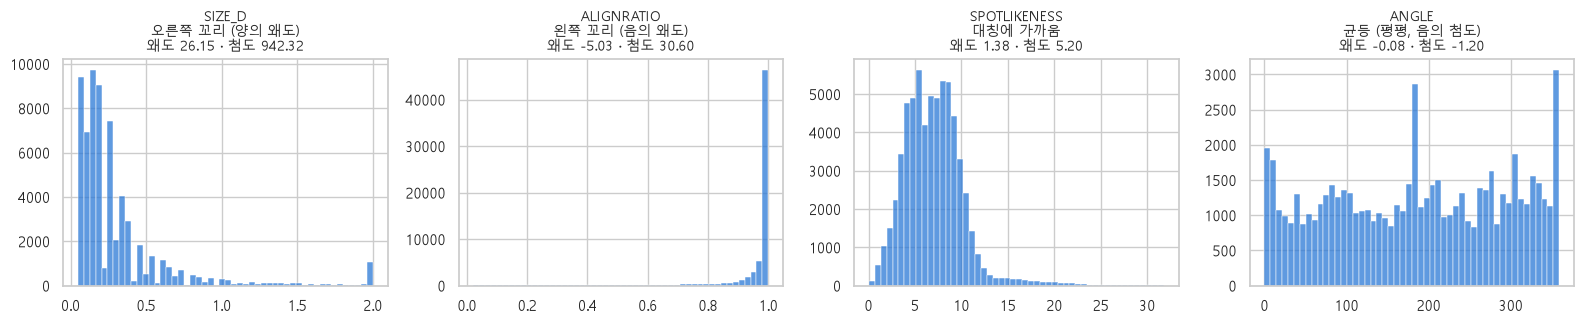

#### Q-Q plot — 정규분포와 얼마나 닮았나? (눈으로 하는 정규성 확인)

데이터를 정렬한 값(표본 분위수)과, 정규분포였다면 나와야 할 값(이론 분위수)을 점으로 찍은 그림입니다.

| 점의 모양 | 의미 |
|---|---|
| 대각선 위에 일직선 | 정규분포에 가까움 |
| 오른쪽 끝이 위로 휨 | 오른쪽 꼬리가 김 (우편향) |
| 양 끝이 S자로 벌어짐 | 꼬리가 두꺼움 (첨도 > 0) |

**실습 프롬프트 P50**

> scipy.stats.probplot을 사용해서 SIZE_D 원본, log10(SIZE_D), SPOTLIKENESS 세 변수의 정규 Q-Q plot을 1행 3열로 그려줘.
>
> 데이터가 많으니 5000개만 random_state=0으로 표본 추출해서 그리고, 점은 작고 반투명하게 해줘.
>
> 기준 대각선은 회색 선으로, 각 제목에 해석(우편향/정규에 가까움 등)을 넣어줘.

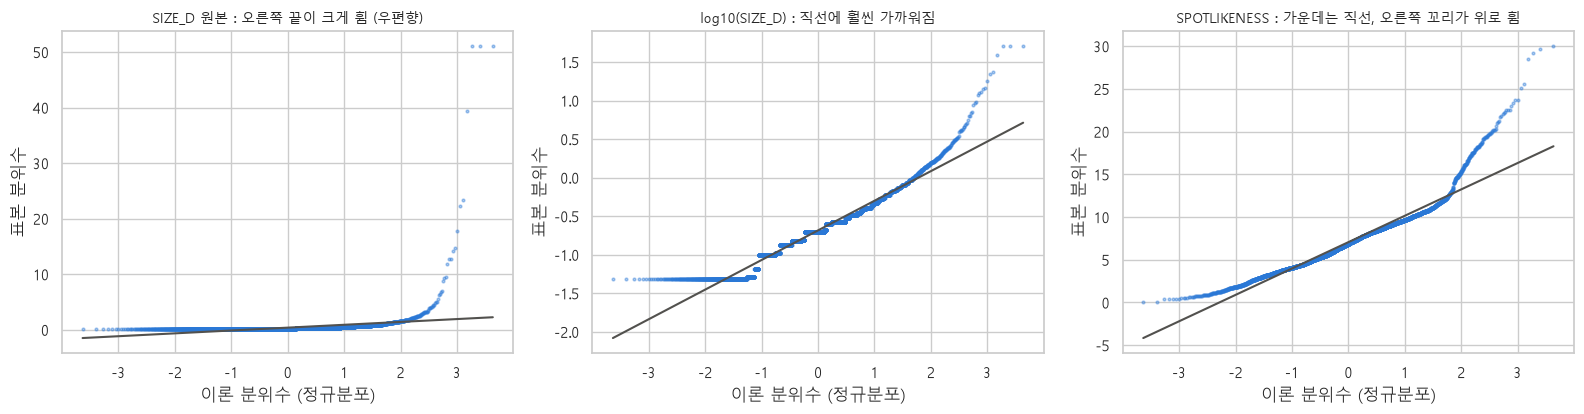

#### 심화 해설 · 왜도·첨도·Q-Q 그림을 함께 읽기

**① 분석 목적**

숫자 하나만으로 정규분포라고 결론 내리지 않도록 합니다.

**② 개념을 먼저 이해하기**

왜도는 비대칭의 방향을 요약합니다. 왜도 0이어도 균등분포나 대칭적인 두 봉우리일 수 있습니다.
pandas의 첨도는 정규분포에서 0인 초과첨도입니다. “봉우리가 뾰족하다”보다 극단적인 꼬리 관측의 영향을 생각하면 정확합니다.
Q-Q 그림의 x축은 정규분포 분위수, y축은 자료의 분위수입니다. 중심만 직선이고 양끝이 휘면 꼬리에서 차이가 있습니다.

,mean,median,std,skew,kurt
원본 SIZE_D,0.3971,0.1990,1.6473,26.1508,942.3238
log10 SIZE_D,-0.6823,-0.7011,0.4014,0.7140,1.9539


SIZE_D 99백분위수: 2.982 최댓값: 101.998
2 µm 이상 기록 수: 1023


**③ 표·그래프 읽는 순서**

99백분위수와 최댓값을 비교하면 극단 꼬리의 규모를 알 수 있습니다. 앞의 2µm로 자른 그림은 꼬리를 2에 모아 표시했으므로 끝 막대가 왜곡됩니다.

**④ 결과 해석과 한계**

로그 변환 후 직선에 가까워 보이는 것은 해당 그림의 관찰입니다. 정규성의 증명이나 이상치 제거의 근거가 되지 않습니다. 평균·중앙값·최빈값의 순서도 모든 비대칭 분포에 성립하는 법칙은 아닙니다.

### 4-8. 범주형 변수의 기술통계 — 빈도표와 파레토

범주형 변수에는 평균·표준편차 대신 **빈도, 상대빈도(비율), 누적빈도, 최빈값**을 사용합니다.

**실습 프롬프트 P51**

> Class 변수의 빈도표를 만들어줘. 빈도, 상대빈도(%), 누적상대빈도(%) 세 열이 있고, 빈도가 많은 순서로 정렬해줘.

,빈도,상대빈도(%),누적상대빈도(%)
Class,,,
9,28060,43.9100,43.9100
21,14215,22.2400,66.1500
10,6143,9.6100,75.7600
99,5295,8.2900,84.0500
39,3469,5.4300,89.4800
20,2269,3.5500,93.0300
56,1549,2.4200,95.4500
28,1022,1.6000,97.0500
17,931,1.4600,98.5100


> **결과 해석**
> 상위 2개 Class(9, 21)가 전체의 **약 66%**, 상위 4개가 **약 84%** 를 차지합니다. 소수 항목이 대부분을 차지하는 **파레토(Pareto) 법칙**의 전형입니다. → 개선 활동은 상위 Class부터!

### 4-9. 그룹별 기술통계 (`groupby`)

**실습 프롬프트 P52**

> 공정(Step_desc)별로 결함수, 진성결함수, 진성결함비율, 웨이퍼 수(Wafer_ID 고유 개수), SIZE_D 중앙값을 구하고,
>
> '웨이퍼당_결함수' 열(결함수/웨이퍼수)도 추가해서 step_summary라는 표로 만들어줘. 소수점 3자리.

,결함수,진성결함수,진성결함비율,웨이퍼수,크기_중앙값,웨이퍼당_결함수
Step_desc,,,,,,
PC,8852,2908,0.3290,168,0.2620,52.6900
RMG,26984,14316,0.5310,467,0.2650,57.7820
CBCMP,28072,18624,0.6630,457,0.1490,61.4270


**실습 프롬프트 P53**

> REAL과 FALSE 그룹의 변수별 중앙값을 비교하는 표를 만들어줘.
>
> 변수: SIZE_D, DEFECT_AREA, INTENSITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE, SPOTLIKENESS,
>
> PATCHNOISE, RELATIVEMAGNITUDE, ACTIVERATIO, PATCHDEFECTSIGNAL, RADIUS
>
> 변수가 행, REAL/FALSE가 열이 되게 하고, '비율 (REAL/FALSE)' 열을 추가해서 내림차순 정렬해줘.
>
> 치우친 변수가 많아서 평균 대신 중앙값을 쓴다는 주석도 달아줘.

IS_DEFECT,FALSE,REAL,비율 (REAL/FALSE)
PATCHDEFECTSIGNAL,62.0000,209.0000,3.3710
MDAT_OFFSET,94.0000,210.0000,2.2340
DEFECT_AREA,0.0020,0.0050,2.1900
RELATIVEMAGNITUDE,190.0000,357.0000,1.8790
INTENSITY,220.0000,379.0000,1.7230
ENERGY_PARAM,825.0000,"1,387.0000",1.6810
PATCHNOISE,32.0300,47.7970,1.4920
SPOTLIKENESS,5.4350,7.7810,1.4320
SIZE_D,0.1980,0.2480,1.2530
ACTIVERATIO,0.8750,1.0000,1.1430


> **결과 해석**
> 진성결함(REAL)은 가성결함(FALSE)보다
> - 신호 세기(`INTENSITY`, `RELATIVEMAGNITUDE`)와 결함 신호(`PATCHDEFECTSIGNAL`), `MDAT_OFFSET`이 **뚜렷하게 크고**
> - `RADIUS` 중앙값이 **더 작고**(웨이퍼 안쪽), 배경 밝기 `MDAT_GL`은 **더 낮습니다**.
> 
> → 가성결함은 "**신호가 약하고, 밝은 배경·웨이퍼 바깥쪽에서**" 많이 잡히는 노이즈일 가능성이 있습니다.

### 4-10. ⑤ 두 변수의 관계 — 교차표, 공분산, 상관계수, 결정계수

#### (1) 범주형 × 범주형 → 교차표 (Crosstab)

**실습 프롬프트 P54**

> Step_desc와 IS_DEFECT의 빈도 교차표를 합계 행/열을 포함해서 만들어줘. 합계 이름은 '합계'로.

IS_DEFECT,FALSE,REAL,합계
Step_desc,,,
PC,5944,2908,8852
RMG,12668,14316,26984
CBCMP,9448,18624,28072
합계,28060,35848,63908


**실습 프롬프트 P55**

> Step_desc와 IS_DEFECT 교차표를 세 가지 방향으로 정규화해서 비교해줘. (%)로 소수점 1자리
> 1. 행 기준(index): 각 공정 안에서 REAL/FALSE 구성비
> 2. 열 기준(columns): REAL(또는 FALSE) 결함은 어느 공정에서 왔나
> 3. 전체 기준(all): 전체 대비 각 칸의 비율
>
> 세 표를 각각 제목을 붙여 출력해줘.

① 행 기준 : 각 공정 안에서의 구성비 (행 합 = 100)
IS_DEFECT   FALSE    REAL
Step_desc                
PC        67.1000 32.9000
RMG       46.9000 53.1000
CBCMP     33.7000 66.3000 

② 열 기준 : REAL/FALSE 결함이 각각 어느 공정에서 왔나 (열 합 = 100)
IS_DEFECT   FALSE    REAL
Step_desc                
PC        21.2000  8.1000
RMG       45.1000 39.9000
CBCMP     33.7000 52.0000 

③ 전체 기준 : 전체 결함 대비 각 칸의 비율 (전체 합 = 100)
IS_DEFECT   FALSE    REAL
Step_desc                
PC         9.3000  4.6000
RMG       19.8000 22.4000
CBCMP     14.8000 29.1000 



**실습 프롬프트 P56**

> 공정별 가성결함 비율을 기준 공정(CBCMP)과 비교해줘.
>
> 각 공정의 가성결함 비율, CBCMP와의 비율 차이(%p), 비율의 배수(몇 배인지)를 표로 보여줘.

,가성결함 비율(%),CBCMP 대비 차이(%p),CBCMP 대비 배수(배)
Step_desc,,,
PC,67.1500,33.4900,2.0000
RMG,46.9500,13.2900,1.3900
CBCMP,33.6600,0.0000,1.0000


> **결과 해석**
> - PC 공정은 검출의 약 **67%가 가성결함**, CBCMP는 약 34%입니다. → 차이 **약 33%p**, 비율로는 **약 2배**
> - **%와 %p를 구분하세요.** 34% → 67%는 "33% 증가"가 아니라 **"33%p 증가 (약 2배)"** 입니다.
> - 교차표는 **`normalize` 방향**에 따라 답하는 질문이 달라집니다.

#### 심화 해설 · 조건부 비율과 %p를 실제 숫자로 검산하기

**① 분석 목적**

교차표를 확률 언어와 일상 언어로 연결합니다.

**② 개념을 먼저 이해하기**

P(REAL | PC)는 PC 공정 안에서 REAL인 비율입니다. P(PC | REAL)는 REAL 기록 안에서 PC인 비율입니다.
세로 막대가 조건을 뜻합니다. 분자가 같아도 조건이 바뀌면 분모가 달라집니다.
비율 0.34에서 0.67로 변하면 33%p 차이이며 상대 증가는 (0.67−0.34)/0.34×100≈97%입니다.

IS_DEFECT,FALSE,REAL
Step_desc,,
CBCMP,9448,18624
PC,5944,2908
RMG,12668,14316


P(REAL | PC) = 2908/8852 = 32.85%
P(PC | REAL) = 2908/35848 = 8.11%
PC와 CBCMP 차이: 33.49%p
CBCMP 대비 PC 상대 차이: 99.51%


**③ 표·그래프 읽는 순서**

공정 안의 비율은 행 합, 결함 종류 안의 공정 구성은 열 합으로 나눕니다.

**④ 결과 해석과 한계**

가성 비율이 높은 공정이 전체 가성 기록 수도 가장 많다고 보장할 수 없습니다. 기록 규모와 비율을 함께 확인해야 합니다.

#### (2) 수치형 × 수치형 → 공분산, 상관계수, 결정계수

| 통계량 | 공식 | 범위 | 특징 |
|---|---|---|---|
| **공분산** | $\text{Cov}(X,Y) = \dfrac{1}{n-1}\sum (x_i-\bar{x})(y_i-\bar{y})$ | −∞ ~ +∞ | 방향은 알 수 있으나 **단위에 따라 크기가 변함** |
| **피어슨 상관계수** | $r = \dfrac{\text{Cov}(X,Y)}{s_X \, s_Y}$ | −1 ~ +1 | **직선** 관계의 강도, 이상치에 민감 |
| **스피어만 상관계수** | 값을 **순위**로 바꾼 뒤 피어슨 계산 | −1 ~ +1 | **단조(한 방향)** 관계, 이상치에 강함 |
| **결정계수** | $r^2$ | 0 ~ 1 | Y의 변동 중 X와 **직선으로 함께 설명되는 비율** |

| \|r\| | 해석 (관례) |
|---|---|
| 0.0 ~ 0.2 | 거의 없음 |
| 0.2 ~ 0.4 | 약함 |
| 0.4 ~ 0.7 | 중간 |
| 0.7 ~ 1.0 | 강함 |

```
  공분산의 부호 원리 : (x-평균)×(y-평균)
        y ▲          ②  (−)×(+) = −   │   ①  (+)×(+) = +
          │                           │
     평균 ┼───────────────────────────┼──────────
          │          ③  (−)×(−) = +   │   ④  (+)×(−) = −
          └───────────────────────────┴──────────▶ x
                                    평균
  ①③ 사분면에 점이 많으면 공분산 > 0 (양의 관계), ②④에 많으면 < 0 (음의 관계)
```

**실습 프롬프트 P57**

> INTENSITY와 RELATIVEMAGNITUDE로 공분산과 피어슨 상관계수를 공식대로 직접 계산하고 pandas 결과와 비교해줘.
>
> 스피어만 상관계수와 결정계수(r²)도 출력해줘.
>
> 마지막으로 INTENSITY를 1000으로 나누면 공분산은 바뀌지만 상관계수는 그대로라는 것을 보여줘.

공분산 (직접)   : 112,311.9  | pandas : 112,311.9
피어슨 r (직접) : 0.9430  | pandas : 0.9430
스피어만 ρ      : 0.9296
결정계수 r²     : 0.8893  → RELATIVEMAGNITUDE 변동의 약 89%가 INTENSITY와 함께 움직임

[x를 1000으로 나누면] 공분산 : 112.312   상관계수 : 0.9430


**실습 프롬프트 P58**

> 여러 변수 쌍에 대해 피어슨 r, 스피어만 ρ, 결정계수 r²(피어슨 기준), 두 상관계수의 차이를 비교하는 표를 만들어줘.
>
> 쌍: (SIZE_X, SIZE_Y), (SIZE_D, DEFECT_AREA), (INTENSITY, ENERGY_PARAM), (MDAT_NOISE, PATCHNOISE),
>
> (SIZE_D, INTENSITY), (RADIUS, ANGLE)
>
> 그리고 피어슨 r 절댓값으로 '강함/중간/약함/거의 없음' 강도 판정 열도 추가해줘.

,피어슨 r,스피어만 ρ,결정계수 r²,차이(ρ−r),강도(피어슨)
변수 쌍,,,,,
SIZE_X × SIZE_Y,0.3480,0.7480,0.1210,0.4000,약함
SIZE_D × DEFECT_AREA,0.4280,0.8410,0.1830,0.4130,중간
INTENSITY × ENERGY_PARAM,0.8190,0.7840,0.6700,-0.0340,강함
MDAT_NOISE × PATCHNOISE,0.5090,0.6110,0.2590,0.1010,중간
SIZE_D × INTENSITY,0.2390,0.6020,0.0570,0.3630,약함
RADIUS × ANGLE,0.0220,0.0350,0.0000,0.0120,거의 없음


> **결과 해석**
> - `SIZE_D × DEFECT_AREA`처럼 극단값이 많은 쌍은 **피어슨(0.43)과 스피어만(0.84)이 크게 다릅니다.** 극단값 몇 개가 피어슨 r을 좌우하기 때문입니다.
> - 결정계수로 보면 `SIZE_X × SIZE_Y`는 피어슨 기준 r² ≈ 0.12 — "같이 움직이는 부분이 12%뿐"으로 보이지만, 순위로 보면(ρ = 0.75) 강한 관계입니다.
> - **치우친 분포 → 스피어만도 함께 확인!** **상관관계 ≠ 인과관계**

#### 심화 해설 · 상관은 계산식과 집단 구성에도 영향을 받는다

**① 분석 목적**

전체 상관계수와 공정별 상관계수를 나란히 비교합니다.

**② 개념을 먼저 이해하기**

피어슨은 직선 관계, 스피어만은 순위의 단조 관계를 요약합니다. 둘 다 U자형 관계를 잘 요약하지 못할 수 있습니다.
정규분포는 피어슨 계수 자체를 계산하기 위한 필수 조건이 아닙니다. 다만 통계적 추론에는 추가 가정이 필요합니다.
피어슨 r²가 결정계수와 일치하는 것은 같은 표본에 절편을 둔 단순 최소제곱회귀 같은 특정 조건입니다.
스피어만 ρ²를 원자료 변동의 설명 비율로 해석하면 안 됩니다.

,그룹,n,Pearson: 크기-신호,Spearman: 크기-신호,Pearson: 크기-면적,Spearman: 크기-면적
0,전체,63908,0.2394,0.6022,0.4277,0.8409
1,CBCMP,28072,0.3308,0.5409,0.5752,0.8558
2,PC,8852,0.2540,0.6257,0.5144,0.8736
3,RMG,26984,0.4413,0.5988,0.7180,0.7518


**③ 표·그래프 읽는 순서**

전체 행을 먼저 읽고 공정별 방향과 크기를 비교합니다. 피어슨과 스피어만의 차이는 산점도로 확인할 질문을 제공합니다.

**④ 결과 해석과 한계**

크기와 면적은 측정·계산 정의상 연결되어 있을 수 있습니다. 상관이 높다는 이유만으로 독립적인 원인을 발견했다고 해석하지 않습니다. 층화 후에도 숨은 조건이 남을 수 있습니다.

#### 실험 ③ 상관계수는 "관계의 모양"을 알려주지 않는다

**실습 프롬프트 P59**

> numpy로 가상의 데이터 4개(각 300개, random seed 0)를 만들어 산점도를 1행 4열로 그려줘.
> 1. 강한 양의 직선 관계 2. 약한 양의 관계 3. 관계 없음 4. U자형 곡선 관계(y = x² + 잡음)
>
> 각 제목에 피어슨 r 값을 넣어서, U자형은 관계가 분명한데도 r이 0에 가깝다는 것을 보여줘.

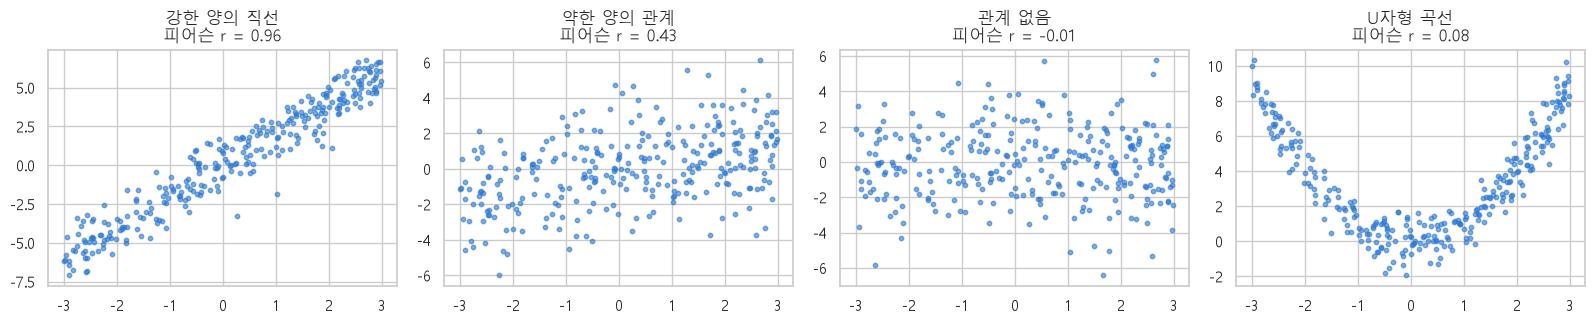

#### 심화 해설 · ANGLE은 원을 도는 값이다

**① 분석 목적**

각도를 일반 수치처럼 평균 내는 오류를 이해합니다.

**② 개념을 먼저 이해하기**

359°와 1°는 서로 2° 떨어져 있지만 산술평균은 180°입니다. 실제 중심 방향은 0° 부근입니다.
원형평균은 각도를 단위원 위의 cos·sin 좌표로 바꾸고 평균 방향을 구합니다.
평균합성벡터 길이 R은 0~1이며, 0에 가까우면 방향이 상쇄되어 평균 방향이 대표값으로 부적절할 수 있습니다.

교육용 [359, 1]의 산술평균: 180.0
교육용 원형평균과 R: (np.float64(360.0), np.float64(0.9998476951563913))
실제 ANGLE 원형평균=316.55°, R=0.0497


**③ 표·그래프 읽는 순서**

실제 R이 작으면 각도 전체가 한 방향에 몰려 있지 않습니다. R만으로 균등분포라고 단정할 수도 없습니다.

**④ 결과 해석과 한계**

앞의 RADIUS×ANGLE 일반 상관은 교육용 숫자 비교로만 읽습니다. 시작 각도에 따라 값이 달라질 수 있어 방향성 분석에는 각도별 빈도나 공간 지도가 더 적절합니다.

> **결과 해석**
> **U자형**은 관계가 뚜렷한데도 r ≈ 0입니다. 상관계수는 **직선 관계만** 측정합니다. → 상관계수를 보고할 때는 **반드시 산점도를 함께** 그리세요.

### 4-11. ⑥ 표본과 모집단 — 표준오차 (추론통계로 가는 다리 )

실무에서는 전수 검사가 어려워 **일부(표본)만 측정**하는 경우가 많습니다. 표본에서 구한 평균은 **표본을 뽑을 때마다 조금씩 달라집니다.**

| 용어 | 의미 | 기호 |
|---|---|---|
| **모집단** | 알고 싶은 전체 대상 (여기서는 전체 63,908개 결함으로 가정) | $\mu$, $\sigma$ |
| **표본** | 모집단에서 뽑은 일부 | $\bar{x}$, $s$ |
| **표본평균의 분포** | 표본을 여러 번 뽑았을 때 표본평균들이 이루는 분포 | |
| **표준오차** (SE) | 표본평균들의 표준편차 = **표본평균이 얼마나 흔들리는가** | $SE = \dfrac{\sigma}{\sqrt{n}}$ |

> **핵심** : 표본 크기 n을 **4배** 늘리면 표준오차는 **절반**으로 줄어듭니다 ($\sqrt{4} = 2$).

**실습 프롬프트 P60**

> log_SIZE_D 열을 모집단으로 보고 표본평균 실험을 해줘.
>
> 표본 크기 n = 10, 40, 160, 640 각각에 대해 표본을 1000번씩 뽑아(random seed 42) 표본평균을 구하고,
>
> 표본평균들의 평균, 표본평균들의 표준편차(실험 SE), 이론 SE(모집단 표준편차/√n)를 비교하는 표를 만들어줘.

모집단 평균 μ = -0.6823,  모집단 표준편차 σ = 0.4014


,표본평균들의 평균,실험 SE (표본평균들의 표준편차),이론 SE (유한모집단 보정)
표본 크기 n,,,
10,-0.6862,0.1277,0.1269
40,-0.6826,0.0619,0.0635
160,-0.6815,0.0326,0.0317
640,-0.6815,0.0161,0.0158


**실습 프롬프트 P61**

> 앞 실험의 표본평균 분포를 표본 크기 n별로 히스토그램 1행 4열로 그려줘.
>
> x축 범위는 모두 같게 하고, 모집단 평균 위치에 세로 점선을 그어줘.
>
> 제목에 n과 SE 값을 넣고, 전체 제목은 'n이 커질수록 표본평균은 모집단 평균 근처로 모인다'로 해줘.

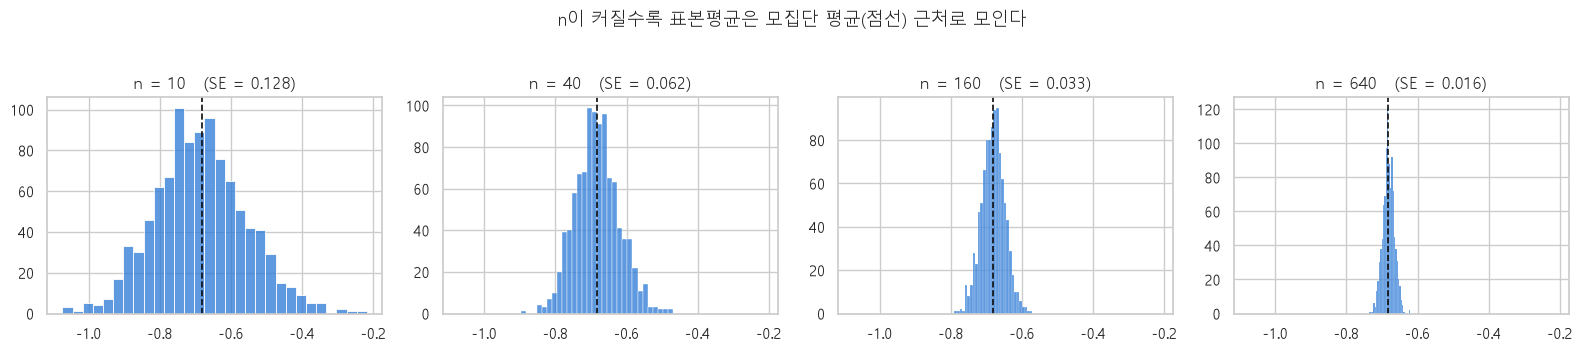

> **결과 해석**
> - 실험 SE와 이론 SE(σ/√n)가 거의 일치합니다. n이 4배(10 → 40 → 160 → 640)가 될 때마다 SE가 **약 절반**으로 줄어듭니다.
> - 표본평균들의 분포는 n이 커질수록 **종 모양(정규분포)** 에 가까워집니다 → 이것이 추론통계의 출발점인 **중심극한정리**입니다.
> - **실무 의미** : "평균 결함 크기"를 표본 10개로 추정하면 꽤 흔들리지만, 640개면 매우 안정적입니다. **평균을 보고할 때는 표본 크기 n도 함께** 보고하세요.

#### 심화 해설 · 표준편차 SD와 표준오차 SE를 구분하기

**① 분석 목적**

관측값 자체의 퍼짐과 평균 추정의 흔들림을 구별합니다.

**② 개념을 먼저 이해하기**

SD는 개별 값이 얼마나 다른지, SE는 같은 방식으로 표본을 다시 뽑았을 때 평균이 얼마나 달라질지를 뜻합니다.
독립·동일분포 표본이라는 조건에서 평균의 SE를 s/√n으로 추정합니다. 동일 웨이퍼·로트 안의 상관을 무시하면 정밀도를 과장할 수 있습니다.
앞의 실험은 CSV를 유한 모집단으로 간주한 비복원 추출이므로 √((N−n)/(N−1)) 보정을 포함합니다.
중심극한정리는 개별 결함 값이 정규분포로 바뀐다는 뜻이 아닙니다. 표본평균의 분포에 관한 설명입니다.

,n,개별 값 SD (원자료),반복 평균의 SD (실험 SE),독립 복원추출 이론 SE
0,10,1.6472,0.4287,0.5209
1,40,1.6472,0.2556,0.2605
2,160,1.6472,0.1334,0.1302
3,640,1.6472,0.0637,0.0651


**③ 표·그래프 읽는 순서**

n이 늘어도 개별 값 SD는 같고 평균의 SE는 줄어듭니다. 극단 꼬리와 500회라는 반복 횟수 때문에 실험값이 이론값과 정확히 같지는 않습니다.

**④ 결과 해석과 한계**

이것은 무작위 추출 시뮬레이션입니다. 실제 파일이 전체 생산을 대표하는 무작위 표본이라는 보장은 제공하지 않습니다. 앞 실험의 log_SIZE_D 평균은 원단위 산술평균과 다릅니다.

---

## 5장. EDA(탐색적 데이터 분석)의 정의

> **이 장의 목표**
> - EDA의 정의와 목적을 설명하고, CDA와 구분할 수 있다.
> - 질문 → 단변량 → 이변량 → 다변량 → 해석의 흐름을 안다.

### 5-1. EDA란?

> **EDA (Exploratory Data Analysis, 탐색적 데이터 분석)**
> 통계학자 **존 튜키(John Tukey, 1977)** 가 제안한 개념으로, **가설을 세우기 전에 데이터를 다양한 각도에서 들여다보며 구조·패턴·이상치·관계를 발견하는 과정**입니다.
>
> *"Exploratory data analysis is detective work."* — John Tukey
> (EDA는 **탐정의 수사**와 같다. 증거를 모으고, 단서를 따라가며, 놓친 것이 없는지 살핀다.)

### 5-2. EDA vs CDA

| 구분 | **EDA** (탐색적 분석) | CDA (확증적 분석) |
|---|---|---|
| 순서 | **먼저** | 나중 |
| 출발점 | 데이터 | 가설 |
| 질문 | "데이터에 무엇이 있지?" | "내 가설이 맞는가?" |
| 도구 | **기술통계 + 시각화** | 가설검정, 모델링 |
| 비유 | 탐정 (단서 찾기) | 판사 (판결 내리기) |

### 5-3. EDA의 목적
1. **데이터 품질 확인** — 결측, 오류, 이상치 (3장)
2. **변수 하나하나의 분포 이해** — 단변량 분석
3. **변수 간 관계 파악** — 이변량 / 다변량 분석
4. **가설과 인사이트 도출** — 다음 분석(모델링)의 방향 설정

### 5-4. EDA 분석 체계

```
            ┌────────────────────────────────────────────────────────┐
            │                  ① 질문 정의 (Question)                  │
            │     "진성결함과 가성결함은 무엇이 다를까?"                    │
            └───────────────────────────┬────────────────────────────┘
                                        ▼
   ┌──────────────────┐   ┌──────────────────────┐   ┌──────────────────────┐
   │ ② 단변량 분석     │   │ ③ 이변량 분석          │   │ ④ 다변량 분석          │
   │ 변수 1개          │ ▶ │ 변수 2개의 관계         │ ▶ │ 변수 3개 이상          │
   │ 분포·중심·퍼짐     │   │ 그룹 비교·상관          │   │ 조건별 비교·히트맵      │
   └──────────────────┘   └──────────────────────┘   └──────────────────────┘
                                        ▼
            ┌────────────────────────────────────────────────────────┐
            │      ⑤ 해석 & 인사이트 → 새로운 질문 (반복!)                │
            └────────────────────────────────────────────────────────┘
```

| 분석 단계 | 변수 조합 | 통계량 | 시각화 |
|---|---|---|---|
| **단변량** | 수치형 1개 | 평균, 중앙값, 표준편차, 사분위수, 왜도 | 히스토그램, 박스플롯, KDE |
| | 범주형 1개 | 빈도, 비율, 최빈값 | 막대그래프 |
| **이변량** | 수치형 × 수치형 | 공분산, 상관계수, 결정계수 | 산점도, 히트맵 |
| | 범주형 × 수치형 | 그룹별 요약통계, 표준화 평균차 | 그룹 박스플롯, 바이올린 |
| | 범주형 × 범주형 | 교차표, 비율, %p | 누적 막대, 히트맵 |
| **다변량** | 3개 이상 | 다중 그룹 집계, 상관행렬 | 색상(hue)·패널(facet) 분할, 히트맵 |

### 5-5. EDA를 위한 바이브코딩 팁

| 단계 | 프롬프트 패턴 |
|---|---|
| 질문 만들기 | "이 데이터 컬럼 목록을 보고, 제조 품질 관점에서 EDA 질문 5개를 제안해줘." |
| 통계 계산 | "`df`에서 [그룹]별 [변수]의 [통계량]을 구해서 [정렬 기준]으로 정렬한 표로 보여줘." |
| 시각화 | "[무엇을 비교]하는 [차트 종류]를 그려줘. 색은 [규칙], 제목에는 결론을 써줘." |
| 해석 요청 | "이 결과표를 보고 제조 현장 관점에서 해석 3가지를 bullet로 써줘. 단, 표에 있는 숫자만 근거로 써." |

---

## 6장. 데이터 시각화

> **이 장의 목표**
> - 목적에 맞는 차트를 고를 수 있다.
> - 기술통계와 시각화를 함께 써야 하는 이유를 설명할 수 있다.

### 6-1. 왜 시각화인가? — 통계량만 보면 속는다

> **앤스컴의 4중주(Anscombe's Quartet)** : 평균·분산·상관계수가 **거의 같은** 4개의 데이터가 그래프로 그리면 **완전히 다른 모양**입니다. → **기술통계와 시각화는 반드시 함께!**

**실습 프롬프트 P62**

> 앤스컴의 4중주(Anscombe's Quartet) 데이터를 인터넷 없이 직접 입력해서 DataFrame으로 만들어줘.
>
> 데이터셋(I~IV)별 x평균, y평균, x분산, y분산, 상관계수를 표로 출력하고,
>
> 4개 데이터의 산점도를 1행 4열(축 공유)로 그려줘.

           x평균    y평균     x분산    y분산   상관계수
dataset                                    
I       9.0000 7.5000 11.0000 4.1300 0.8200
II      9.0000 7.5000 11.0000 4.1300 0.8200
III     9.0000 7.5000 11.0000 4.1200 0.8200
IV      9.0000 7.5000 11.0000 4.1200 0.8200


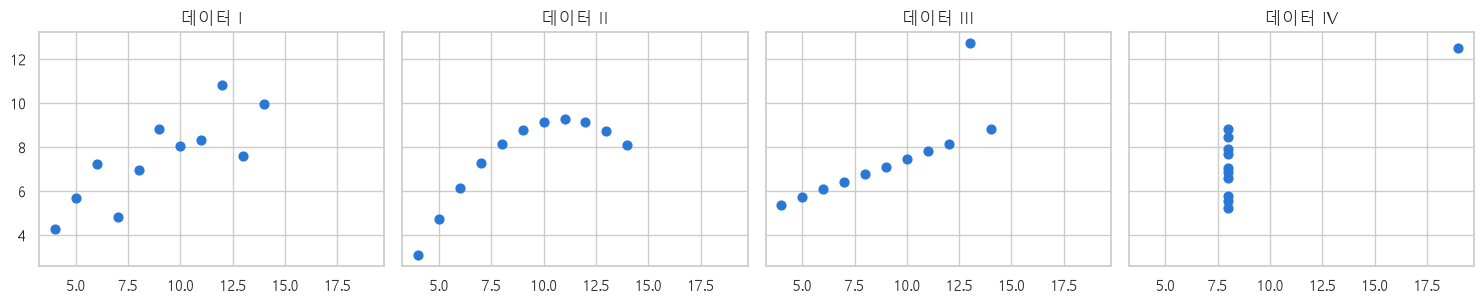

### 6-2. 목적별 차트 선택 가이드

| 무엇을 보고 싶은가? | 데이터 | 추천 차트 | 함수 (seaborn) |
|---|---|---|---|
| **분포** (모양, 퍼짐) | 수치형 1개 | 히스토그램, KDE | `histplot`, `kdeplot` |
| **요약 + 이상치** | 수치형 1개 / 그룹별 | 박스플롯, 바이올린 | `boxplot`, `violinplot` |
| **빈도 · 비교** | 범주형 | 막대그래프 | `countplot`, `barplot` |
| **구성비** | 범주형 × 범주형 | 100% 누적 막대 | `DataFrame.plot.barh(stacked=True)` |
| **관계** | 수치형 × 수치형 | 산점도 | `scatterplot` |
| **많은 변수의 관계** | 수치형 여러 개 | 상관 히트맵 | `heatmap` |
| **공간 분포** | 좌표 | 웨이퍼 맵 | `scatter`, `hexbin` |

> **좋은 그래프의 원칙**
> 1. **제목에 결론을** 쓴다 ("A가 B보다 크다")
> 2. 축 이름과 **단위**를 표시한다
> 3. **같은 항목은 항상 같은 색**으로 (이 노트북: REAL = 주황, FALSE = 파랑)
> 4. 3D, 불필요한 장식, 이중 Y축, 파이차트 남용을 피한다

### 6-3. ① 히스토그램 — 수치형 변수의 분포
연속형 데이터를 **구간(bin)** 으로 나누어 빈도를 막대로 표시합니다(= 도수분포표의 그림). **bins 수**에 따라 모양이 달라지니 여러 번 바꿔보세요.

#### 심화 해설 · 그래프를 그리기 전에 질문과 축을 정하기

**① 분석 목적**

같은 데이터도 구간 수와 축 범위에 따라 인상이 달라지는 것을 확인합니다.

**② 개념을 먼저 이해하기**

히스토그램의 x축은 연속값 구간, y축은 빈도나 밀도입니다. 막대그래프의 x축은 독립된 범주입니다.
밀도 히스토그램은 높이의 합이 아니라 면적의 합이 1입니다. 구간 폭이 다르면 높이만으로 비율을 비교할 수 없습니다.
전체와 일부 범위 확대 그림을 함께 보아야 꼬리를 숨기지 않으면서 중심을 읽을 수 있습니다.

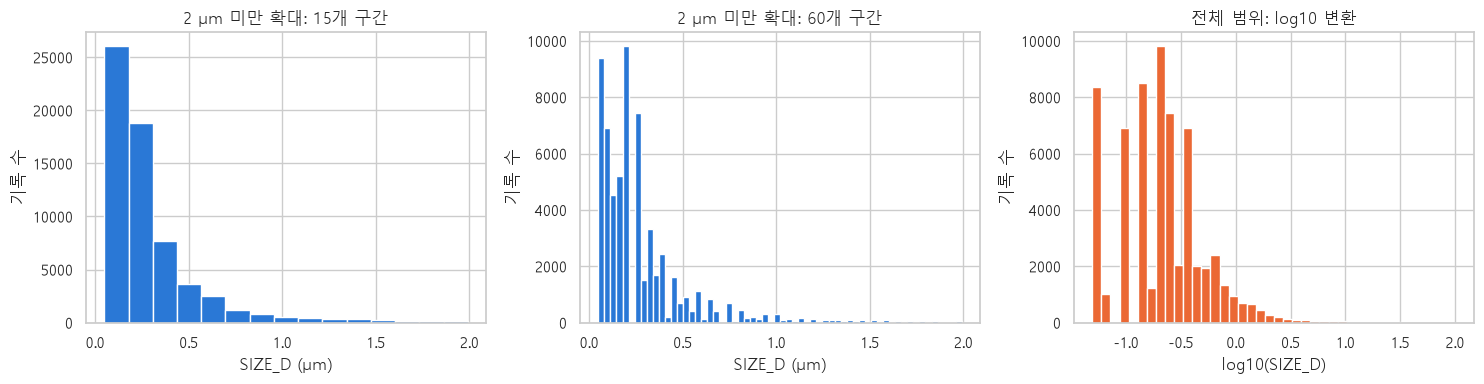

왼쪽 두 그림에서 제외된 2 µm 이상 기록: 1,023개


**③ 표·그래프 읽는 순서**

첫 두 그림에서 봉우리의 세부 모양이 달라지는지 봅니다. 세 번째는 모든 기록을 포함하지만 x축 단위가 다릅니다.

**④ 결과 해석과 한계**

구간 수 하나만 보고 다봉형이나 군집을 확정하지 않습니다. 확대 범위에서 제외된 행 수를 제목이나 주석에 함께 적습니다.

**실습 프롬프트 P63**

> MDAT_GL 히스토그램을 bins = 10, 40, 150으로 바꿔가며 1행 3열로 그려줘. 각 제목에 bins 값을 표시해줘.

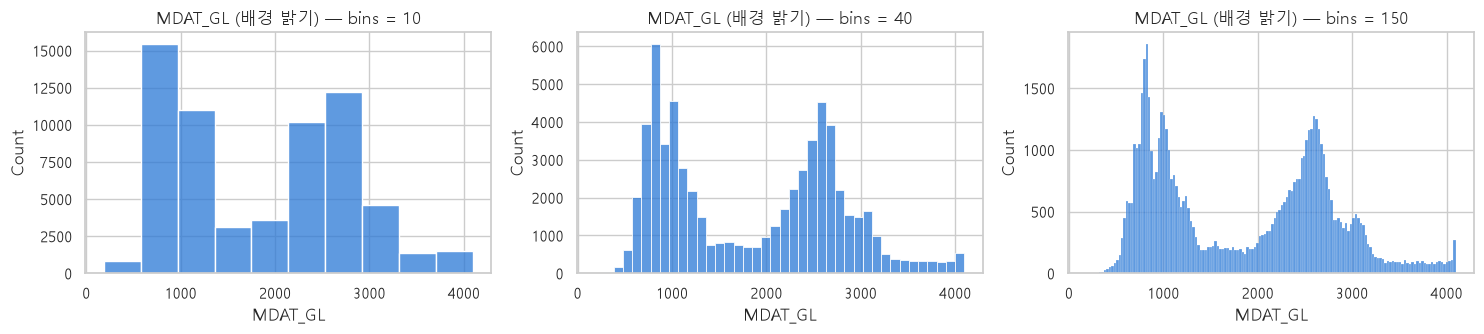

> bins를 늘리자 봉우리가 **여러 개(다봉 분포)** 인 것이 드러납니다. 배경 밝기가 다른 **여러 집단(공정)** 이 섞여 있다는 신호입니다! 공정별로 나눠 확인해 봅시다.

**실습 프롬프트 P64**

> MDAT_GL 히스토그램을 공정(Step_desc)별로 색을 나눠 겹쳐 그려줘.
>
> PAL_STEP 팔레트와 STEP_ORDER 순서를 쓰고, 계단형(step) 막대에 공정별로 각각 정규화한 밀도(density)로 그려줘.
>
> 제목에는 '공정별 분포를 나누어 다봉성의 가능한 설명 확인'이라는 결론을 써줘.

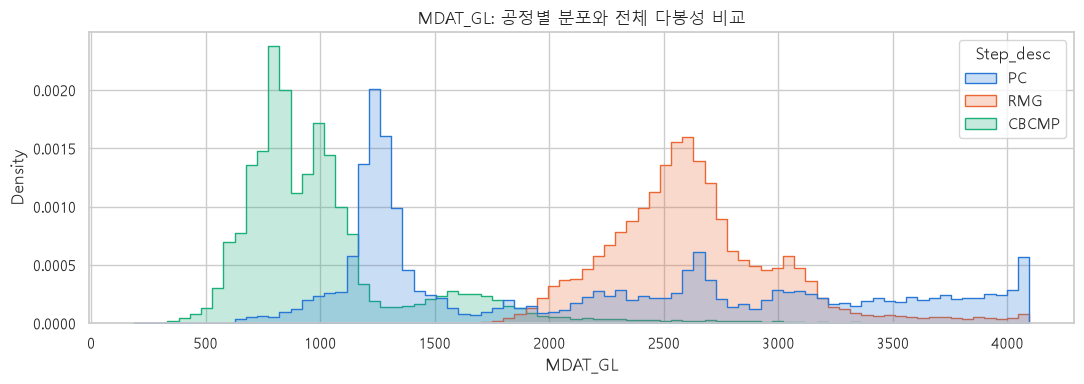

### 6-4. ② 박스플롯 — 5가지 요약을 한 그림에

```
         이상치 ●  ●              ← Q3 + 1.5×IQR 밖의 점
                 ┬               ← 수염 끝 (상한 안의 최댓값)
              ┌──┴──┐  ← Q3 (75%)
              ├─────┤  ← 중앙값 (Q2, 50%)       IQR = Q3 − Q1 (상자의 길이)
              └──┬──┘  ← Q1 (25%)
                 ┴               ← 수염 끝 (하한 안의 최솟값)
```

**실습 프롬프트 P65**

> INTENSITY, PATCHDEFECTSIGNAL, RADIUS 세 변수를 IS_DEFECT(FALSE, REAL 순서)별 박스플롯으로 1행 3열에 그려줘.
>
> 색은 PAL_DEFECT, 이상치 점은 작게. 각 제목에 FALSE와 REAL의 중앙값을 표시하고,
>
> 전체 제목은 '진성결함은 신호가 더 강하고, 가성결함은 웨이퍼 바깥쪽에 몰린다'로 해줘.

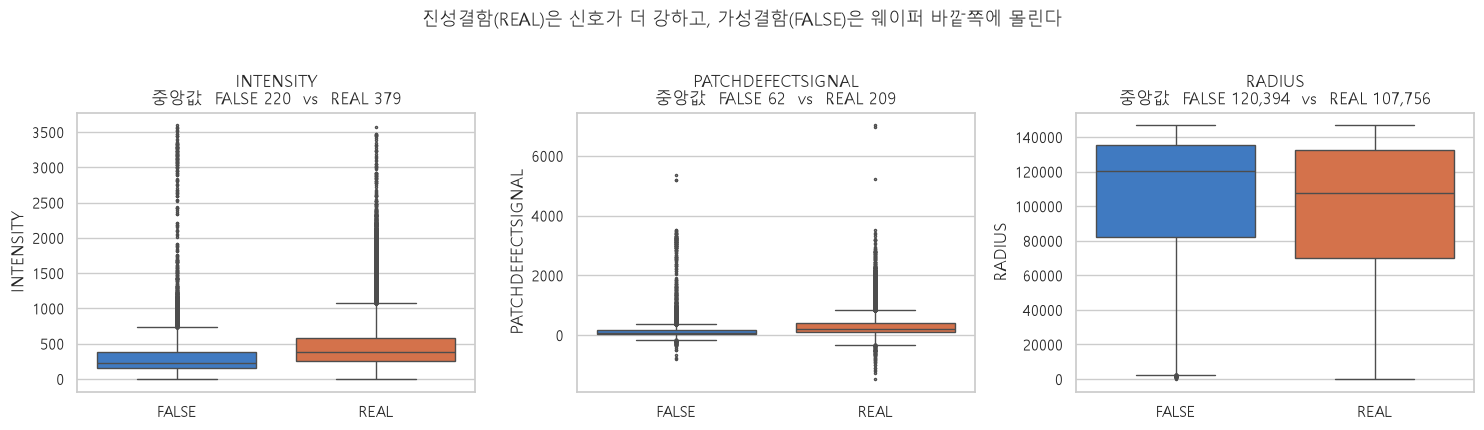

### 6-5. ③ 바이올린 플롯 & KDE — 분포의 '모양'까지 비교
박스플롯은 봉우리가 몇 개인지 보여주지 못합니다. **KDE**(커널밀도추정)는 히스토그램을 부드러운 곡선으로 그린 것이고, **바이올린 플롯**은 박스플롯 + KDE입니다.

**실습 프롬프트 P66**

> 1행 2열 그래프를 그려줘.
>
> 왼쪽: 공정별 log_SIZE_D 분포를 IS_DEFECT로 좌우를 나눈(split) 바이올린 플롯, 안쪽에 사분위선 표시
>
> 오른쪽: SPOTLIKENESS의 REAL/FALSE별 KDE 곡선(채우기, 반투명, 그룹별 각각 정규화)
>
> 색은 PAL_DEFECT를 사용해줘.

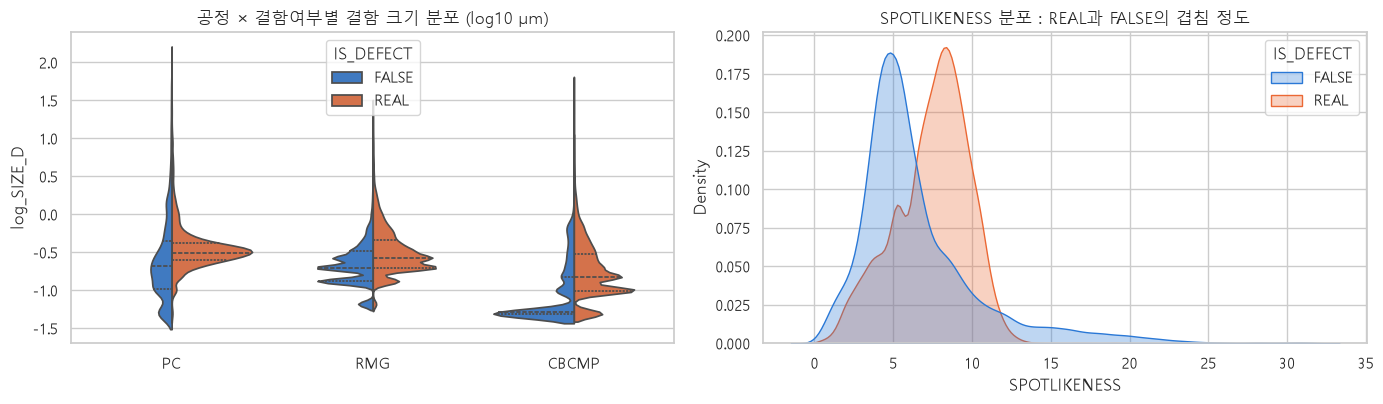

### 6-6. ④ 막대그래프 — 범주형 변수의 빈도와 비교

**실습 프롬프트 P67**

> 1행 2열 그래프를 그려줘.
>
> 왼쪽: Class별 결함 수 막대그래프(빈도순 정렬), 막대 위에 전체 대비 비율(%) 표시
>
> 오른쪽: 공정별 REAL/FALSE 구성비 100% 누적 가로막대(REAL=주황, FALSE=파랑, 막대 사이 흰 테두리),
>
> 막대 안에 'REAL 33%' 같은 흰색 굵은 라벨을 넣고, 라벨이 있으니 범례는 지워줘.
>
> 두 그래프 제목에 결론을 써줘.

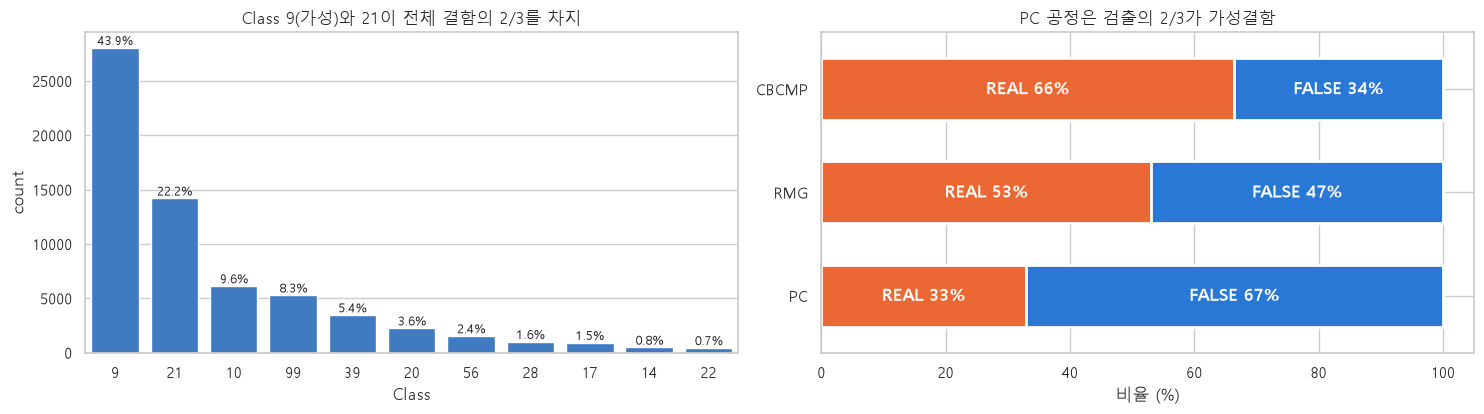

### 6-7. ⑤ 산점도 — 두 수치형 변수의 관계
데이터가 6만 개가 넘으면 점이 겹쳐 보이지 않습니다(**과밀, overplotting**). → **표본 추출 + 투명도(alpha) + 로그 축**으로 해결합니다.

**실습 프롬프트 P68**

> df에서 5000개를 random_state=42로 표본 추출해서 1행 2열 산점도를 그려줘. 색은 IS_DEFECT별 PAL_DEFECT.
>
> 왼쪽: SIZE_X vs SIZE_Y (양쪽 로그축, plain_log로 눈금 표시)
>
> 오른쪽: INTENSITY vs PATCHDEFECTSIGNAL
>
> 점은 작고 반투명하게, 각 제목에 전체 데이터 기준 피어슨 상관계수 r을 표시해줘.

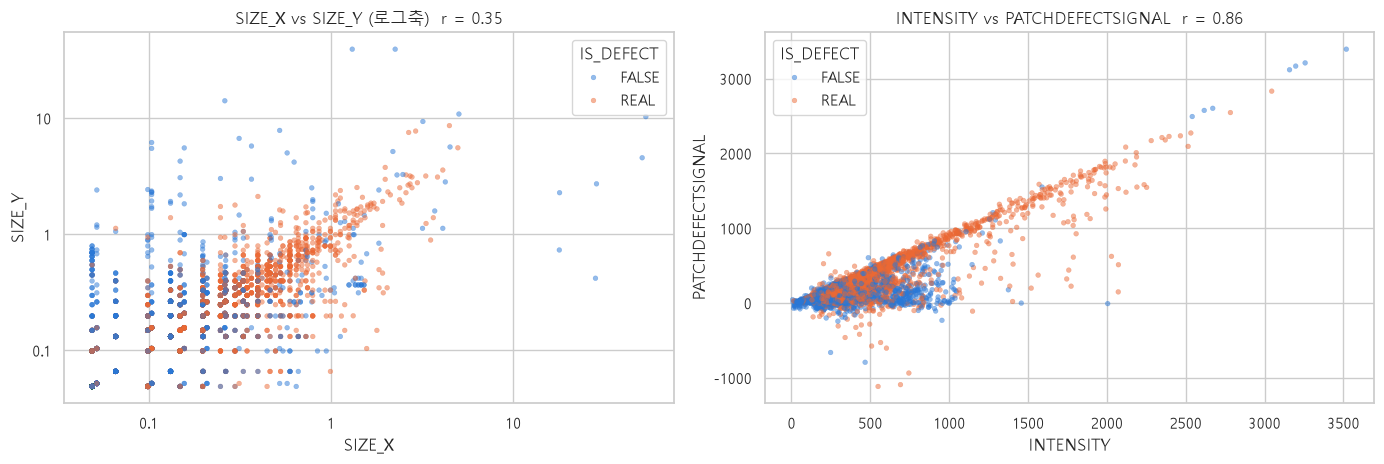

### 6-8. ⑥ 상관 히트맵 — 여러 변수의 관계를 한눈에
> 상관계수 색은 **0을 중심으로 양쪽이 다른 색(발산형)** 이어야 합니다. 0은 흰색, +는 빨강, −는 파랑.

**실습 프롬프트 P69**

> 수치형 변수 16개와 is_real의 스피어만 상관행렬을 히트맵으로 그려줘. 변수 리스트는 heat_cols로 저장해.
>
> (SIZE_X, SIZE_Y, SIZE_D, DEFECT_AREA, INTENSITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE, RADIUS,
>
>  ALIGNRATIO, SPOTLIKENESS, PATCHNOISE, RELATIVEMAGNITUDE, ACTIVERATIO, PATCHDEFECTSIGNAL, is_real)
>
> 위쪽 삼각형은 중복이니 가리고, 칸에 소수 2자리 숫자 표시, 색은 RdBu_r에 -1~1, 0이 가운데 오게 해줘.

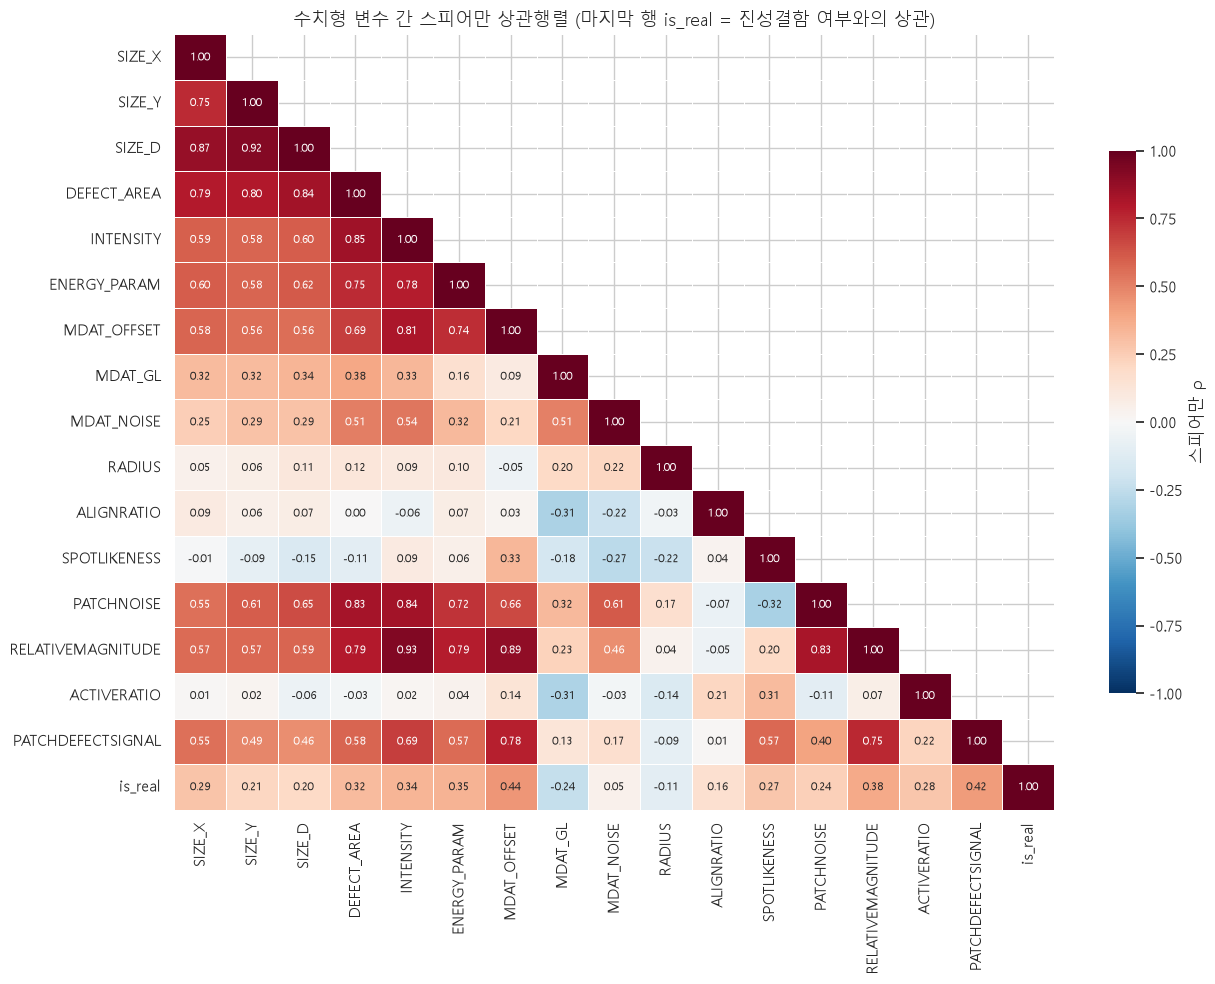

**실습 프롬프트 P70**

> 방금 구한 상관행렬 corr에서 중복과 대각선을 빼고, 절댓값 기준으로 상관이 가장 강한 변수 쌍 10개를 표로 뽑아줘.

스피어만 ρ
RELATIVEMAGNITUDE INTENSITY    0.9300
SIZE_D            SIZE_Y       0.9170
RELATIVEMAGNITUDE MDAT_OFFSET  0.8870
SIZE_D            SIZE_X       0.8710
INTENSITY         DEFECT_AREA  0.8460
DEFECT_AREA       SIZE_D       0.8410
PATCHNOISE        INTENSITY    0.8380
                  DEFECT_AREA  0.8300
RELATIVEMAGNITUDE PATCHNOISE   0.8280
MDAT_OFFSET       INTENSITY    0.8140

> **결과 해석**
> - 크기 변수끼리(`SIZE_X`, `SIZE_Y`, `SIZE_D`, `DEFECT_AREA`), 신호 변수끼리(`INTENSITY`, `RELATIVEMAGNITUDE`, `MDAT_OFFSET`) **강한 양의 상관** → 비슷한 정보를 중복으로 담고 있음(**다중공선성**). 변수 정의와 관계를 더 확인할 단서입니다. 변수 선택의 예측 영향은 4일차에서 별도로 검증합니다.
> - `is_real`과 상관이 큰 변수 = **진성/가성 결함 구분에 유용한 후보 변수**입니다.

### 6-9. ⑦ 웨이퍼 맵 — 제조 데이터만의 공간 시각화
3장에서 만든 `X_mm`, `Y_mm` 좌표로 결함 위치를 웨이퍼 위에 그립니다.

**실습 프롬프트 P71**

> 웨이퍼 맵을 1행 3열로 그려줘.
>
> 1, 2번째: FALSE 결함과 REAL 결함의 위치(X_mm, Y_mm) 산점도 (점 아주 작게, 반투명, 각 PAL_DEFECT 색), 제목에 개수 표시
>
> 3번째: 전체 결함 밀도를 육각형 2D 히스토그램(hexbin, gridsize 40, Blues)으로, 컬러바 포함
>
> 세 그래프 모두 반지름 150mm 웨이퍼 원 테두리를 그리고, 가로세로 비율을 같게, 축 범위는 -160~160, 격자는 끄고 축 이름은 X (mm), Y (mm).

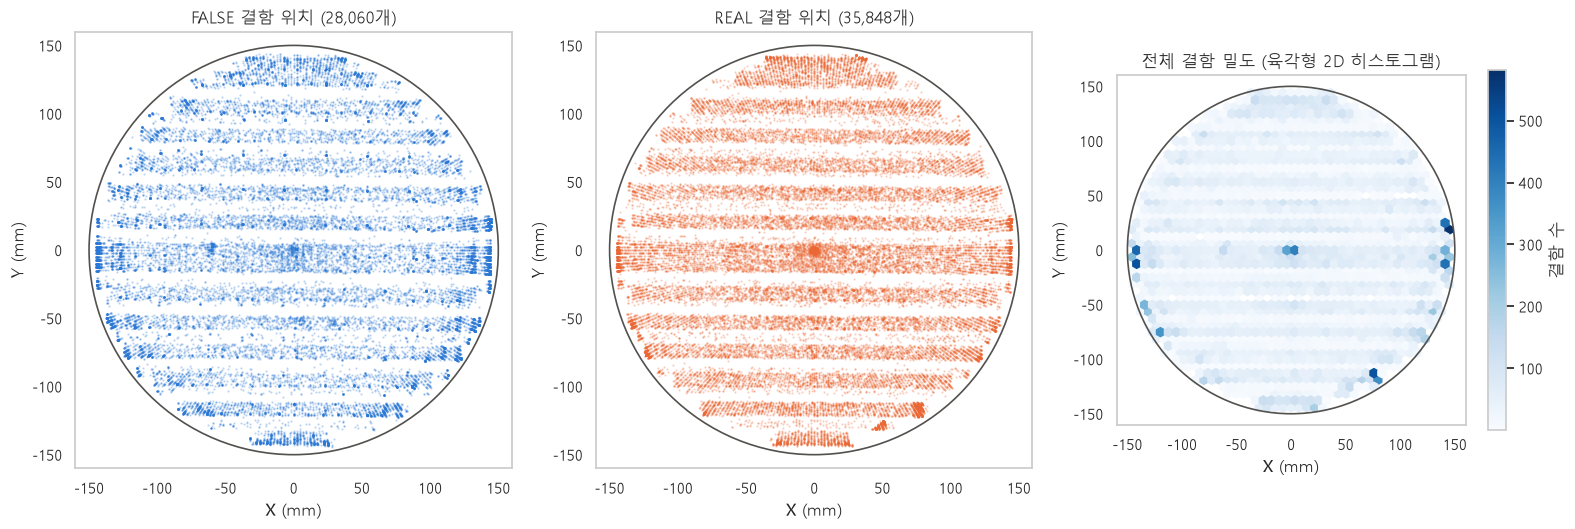

#### 심화 해설 · 여러 웨이퍼를 겹친 지도와 단일 그룹 지도

**① 분석 목적**

전체 공간 패턴이 한 장에서도 나타나는지 구별합니다.

**② 개념을 먼저 이해하기**

전체 지도는 여러 공정·웨이퍼·검사 기록의 중첩입니다. 점이 진한 부분은 관측이 많이 쌓인 위치이지 한 웨이퍼의 결함 집중을 바로 뜻하지 않습니다.
단일 그룹 비교는 같은 좌표 범위와 가로세로 비율을 사용해야 모양을 공정하게 비교할 수 있습니다.

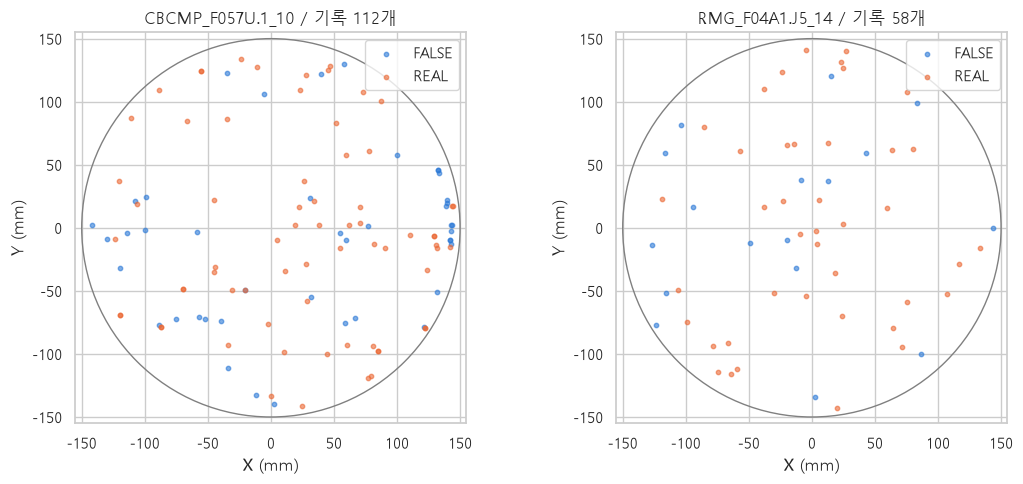

**③ 표·그래프 읽는 순서**

두 지도는 기록 수 순서의 첫 그룹과 중간 그룹이라는 의도적 선택입니다. 무작위 대표 표본은 아닙니다.

**④ 결과 해석과 한계**

기록이 많은 그룹의 패턴이 전체를 대표한다고 볼 수 없습니다. 재검사 중첩 가능성과 동일 위치 반복을 검사 ID로 확인해야 합니다.

> **결과 해석** — 여러 관측 그룹을 겹친 지도에서 FALSE 기록은 가장자리 링에서 진하게 보입니다. 검사 감도·배경 신호·공정 구성 등의 가능한 설명을 검토할 수 있지만, 막 두께나 장비의 오인 원인은 이 CSV만으로 확정할 수 없습니다. 다음 장에서는 기하 면적 차이를 보정하고 그 한계를 확인합니다.

---

## 7장. EDA 종합 실습 — 질문으로 시작해서 인사이트로 끝내기

> **이 장의 목표**
> - 질문 → 통계 → 시각화 → 해석의 흐름으로 분석을 완성할 수 있다.
> - 분석 단위, 정규화 기준, 그룹별 비교, 관리 한계를 의식하며 해석할 수 있다.

> **진행 방식** : 각 질문마다 **질문 → 통계 → 시각화 → 해석** 4단계로 분석합니다.

| # | 질문 | 분석 유형 | 사용 통계 |
|:---:|---|---|---|
| Q1 | 웨이퍼 1장당 결함은 몇 개이고, 이상한 웨이퍼가 있는가? | 단변량 | 사분위수, IQR 이상치 |
| Q2 | 결함 크기 등급별로 진성결함 비율이 다른가? | 범주 × 범주 | 교차표, 비율 |
| Q3 | 웨이퍼의 어느 영역에 결함이 많은가? (면적 보정) | 수치 → 범주 | 구간화, 밀도 |
| Q4 | REAL과 FALSE를 가장 잘 구분하는 변수는? | 범주 × 수치 | 표준화 평균차 |
| Q5 | Class별로 특성이 어떻게 다른가? | 다변량 | 그룹 중앙값, 표준화 |
| Q6 | 로트 내 슬롯 위치에 따라 결함 수가 다른가? | 순서 × 수치 | 그룹 평균·표준편차·CV |
| Q7 | 가성결함 비율이 비정상적으로 높은 로트가 있는가? | 관리도 | 비율, 표준오차, 3σ 관리한계 |

---

### Q1. 웨이퍼 1장당 결함은 몇 개이고, 이상한 웨이퍼가 있는가?

**실습 프롬프트 P72**

> 결함 1개 = 1행인 df를 웨이퍼 1장 = 1행인 wafer 표로 집계해줘.
>
> Wafer_ID별 Step_desc(첫 값), 결함수, 진성결함수, 진성비율을 구하고 Step_desc는 STEP_ORDER 순서형 범주로 만들어줘.
>
> 웨이퍼 수를 출력하고, 공정별 결함수의 기술통계(describe)를 소수 1자리로 보여줘.

웨이퍼 수 : 1,092장


,count,mean,std,min,25%,50%,75%,max
Step_desc,,,,,,,,
PC,168.0000,52.7000,15.7000,18.0000,38.8000,56.0000,65.2000,78.0000
RMG,467.0000,57.8000,14.0000,19.0000,47.5000,58.0000,68.5000,93.0000
CBCMP,457.0000,61.4000,17.6000,27.0000,48.0000,59.0000,73.0000,112.0000


**실습 프롬프트 P73**

> wafer 표에서 공정별로 IQR 규칙(Q3 + 1.5×IQR 초과)을 적용해 결함 과다 웨이퍼를 찾아 '이상웨이퍼' 열(True/False)로 표시해줘.
>
> groupby + transform을 써서 공정마다 따로 기준을 계산해야 해. 이상 웨이퍼 수와 결함수 상위 목록을 보여줘.

결함 과다 웨이퍼 : 1 장


,Step_desc,결함수,진성결함수,진성비율,이상웨이퍼
Wafer_ID,,,,,
CBCMP_F057U.1_10,CBCMP,112,69,0.6161,True


**실습 프롬프트 P74**

> 1행 2열 그래프를 그려줘.
>
> 왼쪽: 웨이퍼당 결함수 히스토그램을 공정별 색(PAL_STEP)으로 계단형으로 겹쳐서
>
> 오른쪽: 공정별 결함수 박스플롯(이상치 점은 숨김) 위에, 결함 과다 웨이퍼를 빨간 다이아몬드(#e34948)로 표시

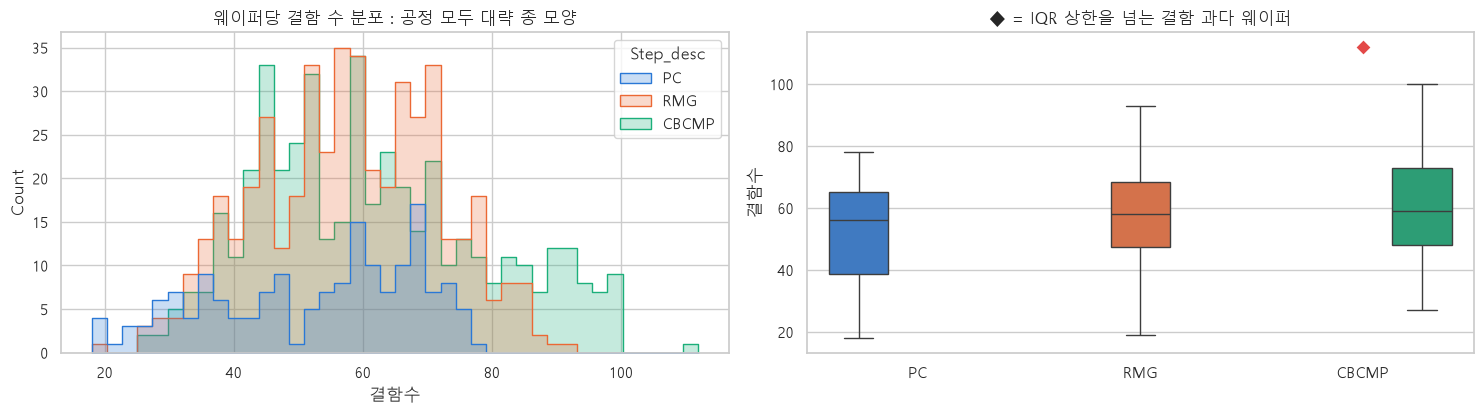

> **Q1 해석**
> - 웨이퍼당 결함 수는 공정별로 중앙값 **약 56~59개**로 비슷하며, 분포는 대략 대칭(종 모양)입니다.
> - IQR 기준 '결함 과다 웨이퍼'는 **CBCMP 공정의 `F057U.1` 10번 슬롯 단 1장**입니다.
> - 그런데 이 웨이퍼는 **3-3에서 '키 중복'이 발견된 바로 그 웨이퍼**입니다! 동일 키의 반복과 기록 수 증가가 함께 관찰되지만 재검사 여부는 검사 이력으로 확인해야 합니다. → 전처리의 단서가 EDA에서 다시 연결되는 순간입니다.
> - 결함 단위 데이터를 **웨이퍼 단위로 집계**하면 전혀 다른 질문에 답할 수 있습니다. **"분석 단위(unit of analysis)"** 를 의식하세요!

---

### Q2. 결함 크기 등급별로 진성결함 비율이 다른가?

**실습 프롬프트 P75**

> SIZE_GRADE와 IS_DEFECT의 교차표를 합계 포함해서 만들고, 등급별 '진성비율(%)' 열(REAL/합계×100, 소수 1자리)을 추가해줘.

IS_DEFECT,FALSE,REAL,합계,진성비율(%)
SIZE_GRADE,,,,
극소(≤0.1),8526,6230,14756,42.2000
소(0.1-0.3),13035,17027,30062,56.6000
중(0.3-1),5422,10710,16132,66.4000
대(>1),1077,1881,2958,63.6000
합계,28060,35848,63908,56.1000


**실습 프롬프트 P76**

> 공정 × 크기 등급별 진성결함 비율(%)을 구해서 묶은 막대그래프로 그려줘.
>
> x축은 크기 등급, 색은 공정(PAL_STEP), 막대 위에 값 라벨, 전체 평균 진성비율은 회색 점선과 텍스트로 표시.
>
> y축은 0~105, 범례는 위쪽 왼쪽에 가로로 3열. 제목에는 '공정마다 패턴이 다르다'는 결론을 써줘.

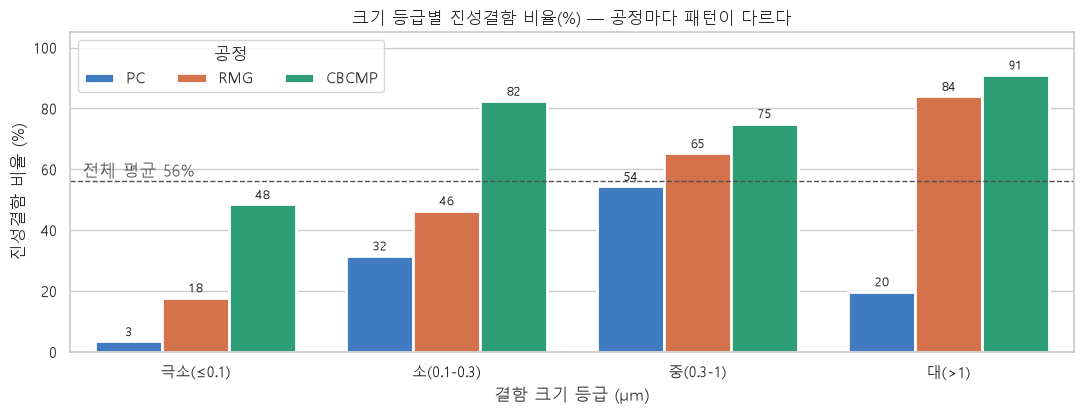

> **Q2 해석**
> - 전체로 보면 **결함이 클수록 진성결함 비율이 높아지는** 경향(극소 42% → 중 66%)이 있습니다. 아주 작은 신호일수록 노이즈일 가능성이 크다는 뜻입니다.
> - 그러나 **공정별로 나누면 패턴이 다릅니다.** CBCMP·RMG는 '대' 등급의 진성비율이 80~90%대지만, **PC 공정은 '대' 등급에서 20%로 크게 떨어집니다.** PC 공정에는 '크지만 가짜인' 결함이 많다는 단서입니다.
> - **"전체 vs 그룹별"을 항상 함께 보세요.** (그룹을 합치면 경향이 뒤바뀌는 현상을 **심슨의 역설(Simpson's Paradox)** 이라고 합니다.)

---

### Q3. 웨이퍼의 어느 영역에 결함이 많은가? (면적 보정)

> **함정!** 반경 구간마다 **면적이 다릅니다.** 단순 개수 비교는 불공평 → **단위 면적당 결함 수(밀도)** 로 비교해야 합니다.
> 링 면적 = $\pi (r_{바깥}^2 - r_{안}^2)$

**실습 프롬프트 P77**

> ZONE별로 결함수와 진성비율을 구하고, 각 링의 면적(cm²)을 π(바깥반지름² - 안반지름²)/100으로 계산해줘.
>
> (반지름 경계: 0, 50, 100, 130, 150 mm)
>
> 누적기록/기하면적(개/cm²) = 결함수/면적, 개수 비중(%), 면적 비중(%) 열도 추가해서 zone 표로 보여줘.

,결함수,진성비율,링면적(cm²),누적기록/기하면적(개/cm²),개수 비중(%),면적 비중(%)
ZONE,,,,,,
중심(0-50),8519,0.6200,78.5400,108.4700,13.3300,11.1100
중간(50-100),17071,0.6100,235.6200,72.4500,26.7100,33.3300
외곽(100-130),17934,0.5600,216.7700,82.7300,28.0600,30.6700
가장자리(130-150),20384,0.4900,175.9300,115.8600,31.9000,24.8900


**실습 프롬프트 P78**

> zone 표로 1행 3열 막대그래프를 그려줘.
>
> ① 단순 결함 개수 ② 면적 보정 밀도 ③ 진성결함 비율(%, 주황색)
>
> x축 라벨은 '중심, 중간, 외곽, 가장자리'로 짧게, 막대 위에 값 표시, 각 제목에 결론을 써줘.

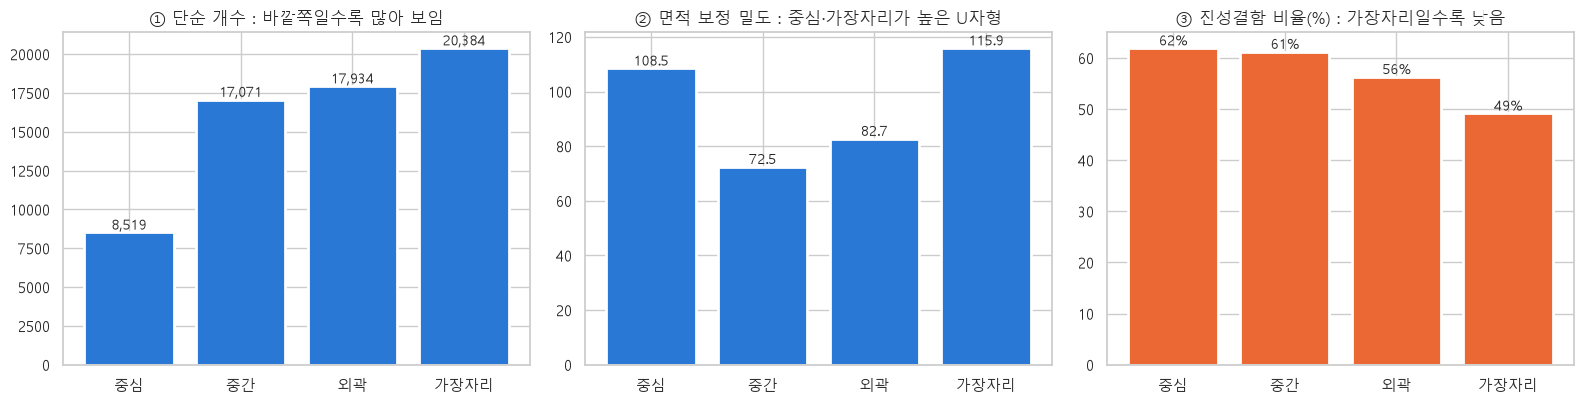

#### 심화 해설 · 기하 면적 보정과 실제 검사 노출량은 다르다

**① 분석 목적**

바깥 고리의 면적이 더 크다는 효과와 검사 횟수 효과를 구별합니다.

**② 개념을 먼저 이해하기**

고리 면적은 π(바깥반경²−안쪽반경²)입니다. mm²를 cm²로 바꿀 때 100으로 나눕니다.
앞 표의 “누적기록/기하면적”은 모든 기록을 웨이퍼 한 장의 고리 면적으로 나눈 값입니다.
아래는 모든 관측 그룹이 전체 면적을 한 번씩 검사했다는 가정 아래 그룹 수까지 나눈 예시입니다.
실제 밀도에는 검사 면적·검사 회차·가장자리 제외 영역·무검출 웨이퍼 목록이 필요합니다.

,기록 수,한 장 고리 면적_cm2,기록 구성비,기하 면적 구성비,상대 집중도,가정상 그룹·cm2당 기록
RADIUS,,,,,,
"(-0.001, 50.0]",8519,78.5398,0.1333,0.1111,1.1997,0.0993
"(50.0, 100.0]",17071,235.6194,0.2671,0.3333,0.8014,0.0663
"(100.0, 130.0]",17934,216.7699,0.2806,0.3067,0.9151,0.0758
"(130.0, 150.0]",20384,175.9292,0.3190,0.2489,1.2815,0.1061


가정한 관측 그룹 수: 1092


**③ 표·그래프 읽는 순서**

상대 집중도 1은 기하 면적 비중과 기록 비중이 같다는 뜻입니다. 1보다 크면 면적 비중보다 기록 비중이 큽니다.

**④ 결과 해석과 한계**

균일한 검사 노출을 가정하지 않으면 공간 위험도 차이로 확정할 수 없습니다. 검사 민감도나 레시피 변경 전에 노출 면적과 이력을 먼저 확인합니다.

> **Q3 해석**
> - **단순 개수**만 보면 가장자리 결함이 중심의 **약 2.4배**로 보이지만, 여기에는 가장자리 링의 더 넓은 면적이 영향을 줍니다. 면적만으로 모든 차이가 설명되는지는 따로 확인합니다.
> - **한 장의 기하 면적으로 나눈 누적 기록 수**로 보면 중심(약 108개/cm²)과 가장자리(약 116개/cm²)가 비슷하게 높고, 중간 영역이 가장 낮은 **U자형** 분포입니다. → **정규화 기준에 따라 결론이 완전히 달라집니다!**
> - 진성결함 비율은 중심 62% → 가장자리 49%로 **바깥으로 갈수록 낮아집니다.** 가장자리 결함은 **절반 이상이 가성결함**입니다.
> - → 제안 : **검사 노출 면적·회차·공정 구성을 확인한 뒤 레시피 점검 필요성을 검토**
> - 비교할 때는 **공정한 기준(면적, 시간, 생산량 등)으로 나누어 정규화**하세요. (불량 수 → 불량률, 고장 수 → 가동 시간당 고장률)

---

### Q4. REAL과 FALSE를 가장 잘 구분하는 변수는?

단위가 다른 변수들을 공정하게 비교하기 위해 **표준화된 평균 차이**를 사용합니다. (평균 차이를 표준편차로 나눈 값 — 기술통계만으로 계산 가능)

$$d = \dfrac{\bar{x}_{REAL} - \bar{x}_{FALSE}}{s_{av}}, \quad s_{av} = \sqrt{\dfrac{s_{REAL}^2 + s_{FALSE}^2}{2}}$$

> |d| ≈ 0.2 작음, 0.5 중간, **0.8 이상 큼** (관례적 기준). 치우친 변수는 로그 변환 후 계산하면 극단값 영향을 줄일 수 있습니다.

**실습 프롬프트 P79**

> REAL과 FALSE 그룹 간 표준화 평균차 d = (REAL 평균 - FALSE 평균) / 합동표준편차 를 변수별로 계산해줘.
>
> 합동표준편차 = sqrt((REAL 분산 + FALSE 분산)/2)
>
> 후보 변수: SIZE_D, DEFECT_AREA, INTENSITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE, SPOTLIKENESS,
>
> PATCHNOISE, RELATIVEMAGNITUDE, ACTIVERATIO, ALIGNRATIO, RADIUS, ASPECT
>
> 이 중 치우친 양수 변수(log_cols: SIZE_D, DEFECT_AREA, INTENSITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_NOISE,
>
> PATCHNOISE, RELATIVEMAGNITUDE)는 log10(x + 0.0001) 변환 후 계산하고 변수명 뒤에 ' (log)'를 붙여줘.
>
> REAL/FALSE 중앙값(원본 기준)도 함께 보여주고, |d| 내림차순으로 정렬한 sep 표를 만들어줘.

,REAL 중앙값,FALSE 중앙값,표준화 평균차 d,|d|
변수,,,,
RELATIVEMAGNITUDE (log),357.0000,190.0000,0.8120,0.8120
INTENSITY (log),379.0000,220.0000,0.7030,0.7030
MDAT_OFFSET (log),210.0000,94.0000,0.6970,0.6970
ENERGY_PARAM (log),"1,387.0000",825.0000,0.6440,0.6440
DEFECT_AREA (log),0.0050,0.0020,0.6090,0.6090
ACTIVERATIO,1.0000,0.8750,0.4980,0.4980
MDAT_GL,"1,542.0000","2,472.0000",-0.4690,0.4690
PATCHNOISE (log),47.7970,32.0300,0.4590,0.4590
ALIGNRATIO,1.0000,0.9980,0.4280,0.4280


**실습 프롬프트 P80**

> sep 표의 표준화 평균차 d를 가로 막대그래프로 그려줘. 큰 값이 위로 오게 하고,
>
> 양수는 주황(REAL이 큼), 음수는 파랑(FALSE가 큼), ±0.5와 ±0.8 위치에 연한 점선, 0에 진한 선, 막대 끝에 값 라벨.

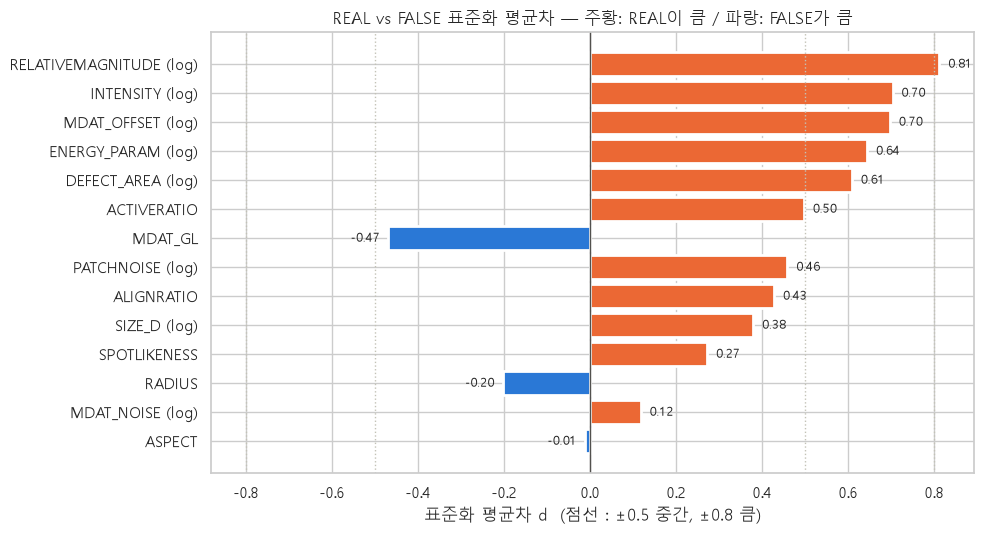

**실습 프롬프트 P81**

> sep 표에서 구분력이 큰 상위 4개 변수의 REAL/FALSE 분포를 KDE 곡선으로 1행 4열에 그려줘.
>
> log_cols에 해당하면 log10 변환한 값으로 그리고 제목에 (log10) 표시. 그룹별로 각각 정규화, 채우기, 반투명.

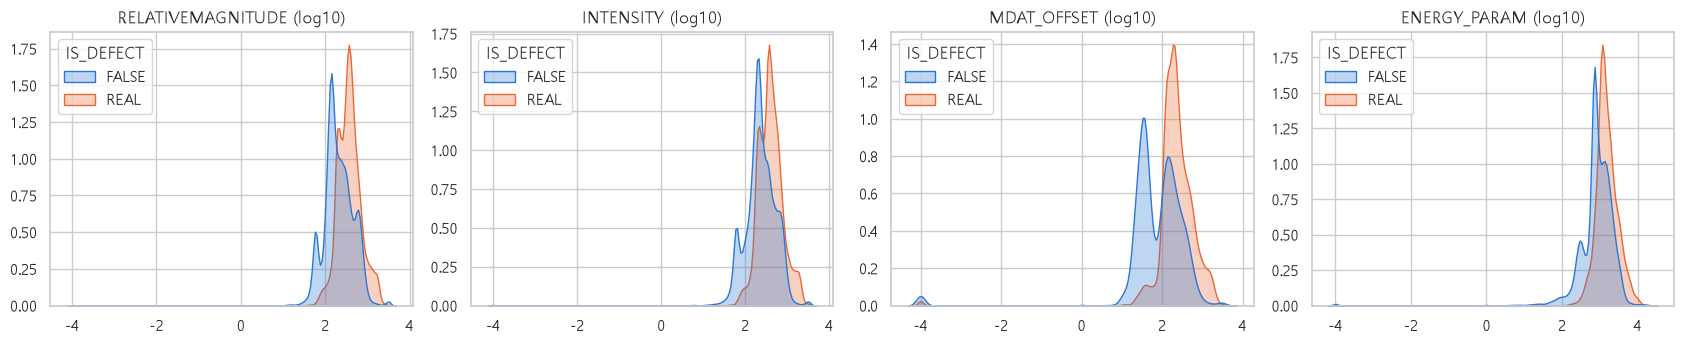

#### 심화 해설 · 집단 차이와 겹침을 동시에 설명하기

**① 분석 목적**

REAL/FALSE의 평균·중앙값 차이가 모든 개별 결함을 구분하는 것은 아님을 확인합니다.

**② 개념을 먼저 이해하기**

효과크기는 두 집단 차이를 표준편차 단위로 요약합니다. 앞 실습은 두 분산의 단순평균 제곱근을 분모로 썼습니다.
통상적인 표본 수 가중 pooled SD는 √(((n1−1)s1²+(n0−1)s0²)/(n1+n0−2))입니다.
어느 정의인지 명시해야 하며, 0.2·0.5·0.8 같은 관례는 공정 의사결정의 비용 기준이 아닙니다.

,변수 (원단위),REAL n,FALSE n,REAL 중앙값,FALSE 중앙값,중앙값 차이,표본 수 가중 Cohen d
0,MDAT_GL,35848,28060,"1,542.0000","2,472.0000",-930.0000,-0.4763
1,SPOTLIKENESS,35848,28060,7.7812,5.4347,2.3465,0.2806
2,INTENSITY,35848,28060,379.0000,220.0000,159.0000,0.5080


**③ 표·그래프 읽는 순서**

앞 표가 로그값에서 계산한 차이인지 원단위 차이인지 확인한 후 비교합니다. 밀도 곡선의 겹치는 구간도 봅니다.

**④ 결과 해석과 한계**

집단 중심이 달라도 개별 값은 겹칩니다. 이것은 학습 모델의 정확도나 실무 판정 임계값을 제공하지 않습니다. 그 검증은 4일차 범위입니다.

> **Q4 해석**
> - 신호 관련 변수(`RELATIVEMAGNITUDE`, `INTENSITY`, `MDAT_OFFSET`, `ENERGY_PARAM`)가 **REAL에서 확실히 큰 값**을 보여 구분력이 가장 높습니다 (d ≈ 0.6~0.8).
> - 음수 쪽에서는 `MDAT_GL`(배경 밝기)이 중간 크기 → FALSE는 **밝은 배경**에서 많이 발생. `RADIUS`도 음수 → FALSE가 더 바깥쪽 (Q3과 일치 ).
> - 그러나 KDE를 보면 **두 분포가 상당히 겹칩니다.** 변수 1개만으로는 완벽히 구분할 수 없으므로, 여러 변수를 조합하는 **머신러닝 분류 모델**이 다음 단계가 됩니다.

---

### Q5. Class별로 특성이 어떻게 다른가? (다변량 프로파일)
변수마다 단위가 다르므로 **Class별 중앙값을 표준화(Z-점수)** 하여 하나의 히트맵으로 비교합니다.

**실습 프롬프트 P82**

> Class별로 SIZE_D, ASPECT, INTENSITY, MDAT_OFFSET, MDAT_GL, MDAT_NOISE, SPOTLIKENESS, PATCHNOISE,
>
> ACTIVERATIO, PATCHDEFECTSIGNAL, RADIUS의 중앙값을 구하고, 열(변수)마다 Z-점수로 표준화해줘.
>
> 히트맵 색은 표준화 점수(RdBu_r, 0 중심, -2.5~2.5), 칸 안 숫자는 실제 중앙값(100 이상이면 정수, 미만이면 소수 2자리)으로 표시해줘.
>
> 행 이름은 'Class 9  (n=28,060, 가성)'처럼 개수와 진성/가성 여부를 붙여줘.

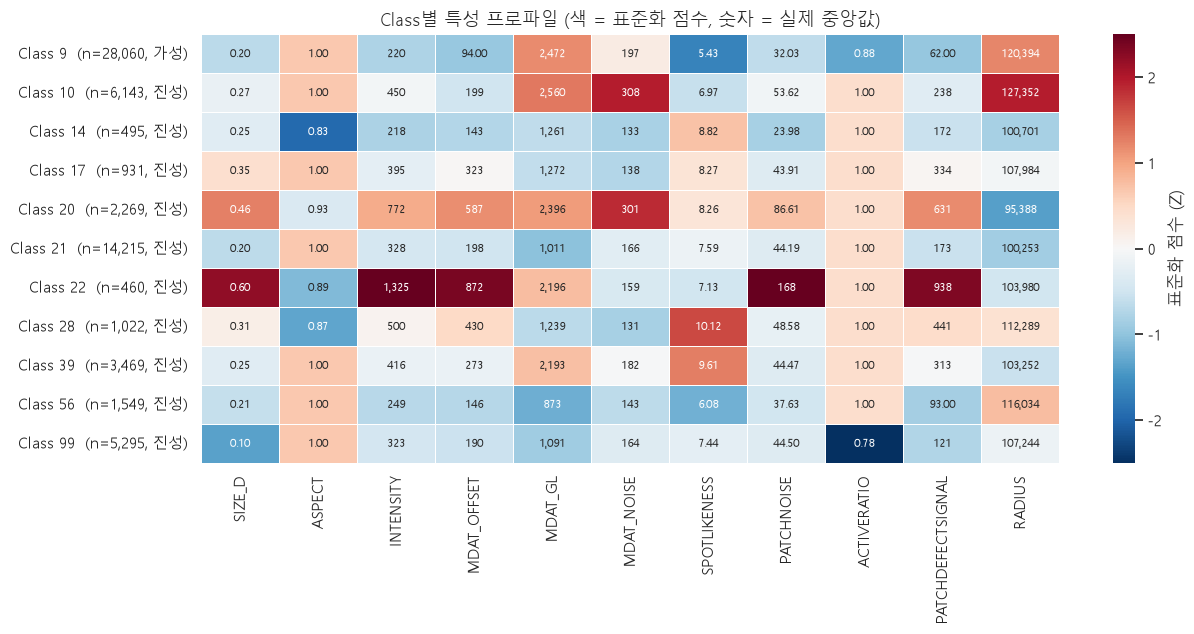

> **Q5 해석 (읽는 법)** — 행을 따라 **빨간 칸 = 다른 Class보다 큰 특성**, **파란 칸 = 작은 특성**입니다.
> - **Class 9 (가성결함)** : 신호 세기·오프셋·`SPOTLIKENESS`가 낮고, 배경이 밝으며(`MDAT_GL`↑) `RADIUS`가 커서 **가장자리 노이즈**의 특징을 보입니다.
> - **Class 22** : `SIZE_D`, `INTENSITY`, `PATCHNOISE`가 모두 두드러지게 큼 → **대형·강신호 결함**(구체적인 결함 종류는 별도 확인) 유형
> - **Class 10** : `RADIUS`와 `MDAT_NOISE`가 큼 → **가장자리에 분포하는 진성결함** 유형
> - **Class 14** : `ASPECT`(가로/세로)가 매우 작음 → **세로로 긴 모양**의 결함
> - **Class 99** : `ACTIVERATIO`가 매우 낮음 → 낮은 활성비 측정값이 관찰됨 (Class 99의 의미는 공식 코드표 확인 필요)

---

### Q6. 로트 내 슬롯 위치에 따라 결함 수가 다른가?

**실습 프롬프트 P83**

> wafer 표의 인덱스(Wafer_ID)에서 마지막 '_' 뒤의 슬롯 번호를 정수로 꺼내 Slot_No 열을 만들어줘.
>
> 슬롯별 결함수의 개수, 평균, 중앙값, 표준편차, CV(%)를 구해서 슬롯이 열이 되도록 전치해 보여줘.

Slot_No,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
count,20.0000,26.0000,20.0000,32.0000,47.0000,55.0000,61.0000,68.0000,66.0000,72.0000,67.0000,75.0000,99.0000,149.0000,46.0000,33.0000,38.0000,29.0000,30.0000,23.0000,11.0000,4.0000,11.0000,5.0000,5.0000
mean,57.9000,52.2000,61.2000,55.0000,54.6000,59.8000,58.3000,57.1000,57.4000,55.4000,59.6000,61.9000,58.9000,57.3000,54.2000,58.5000,61.9000,63.7000,65.2000,67.0000,63.7000,59.8000,66.6000,57.0000,49.6000
median,61.0000,51.5000,59.5000,55.0000,55.0000,60.0000,56.0000,55.0000,56.5000,53.5000,59.0000,61.0000,60.0000,58.0000,53.5000,56.0000,61.0000,62.0000,66.5000,69.0000,64.0000,57.5000,69.0000,66.0000,57.0000
std,13.0000,15.9000,22.7000,14.2000,13.8000,15.1000,19.0000,17.3000,15.4000,14.7000,16.5000,15.8000,16.0000,16.8000,14.9000,13.7000,13.6000,16.4000,13.3000,18.5000,13.8000,7.8000,14.7000,24.8000,15.5000
CV(%),22.4000,30.5000,37.1000,25.9000,25.2000,25.2000,32.5000,30.4000,26.8000,26.5000,27.6000,25.5000,27.2000,29.3000,27.5000,23.3000,21.9000,25.8000,20.4000,27.6000,21.7000,13.1000,22.1000,43.5000,31.2000


**실습 프롬프트 P84**

> 슬롯별 통계를 위아래 2개 그래프(x축 공유)로 그려줘. 단위가 다르니 이중 Y축은 쓰지 말아줘.
>
> 위: 슬롯별 웨이퍼 수 막대그래프
>
> 아래: 슬롯별 평균 결함수를 점+선으로, ±1 표준편차 오차막대, 전체 평균은 회색 점선. x축 눈금은 1~25.

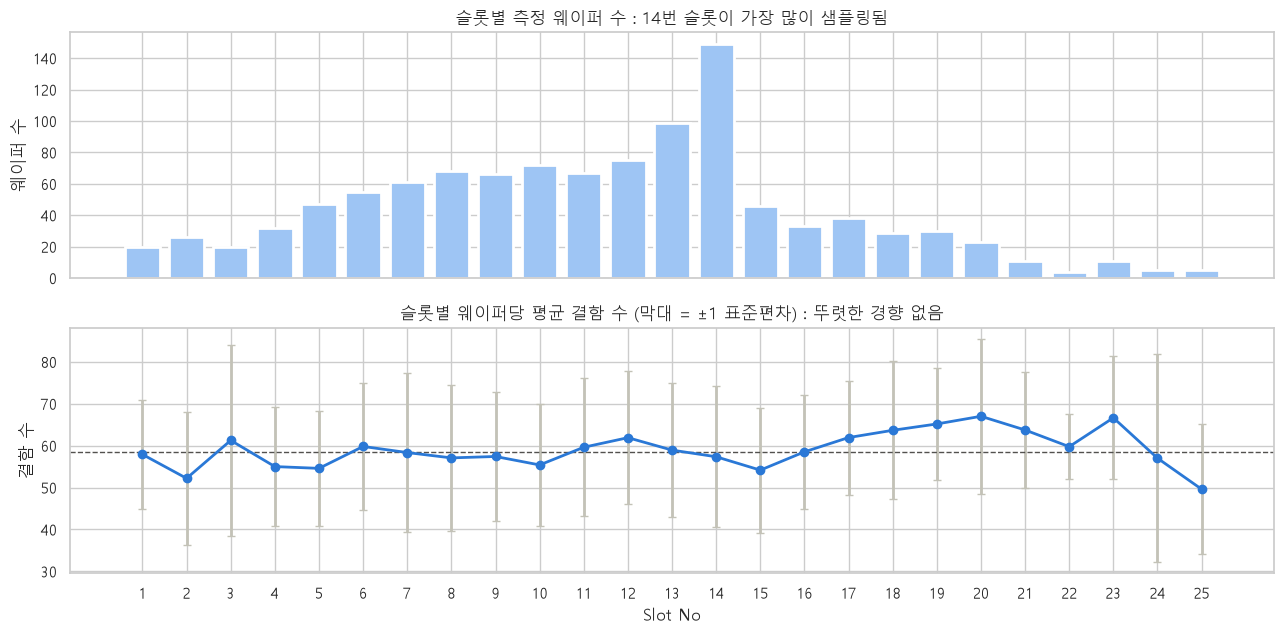

> **Q6 해석**
> - 슬롯별 평균 결함 수는 전체 평균선 근처에서 오르내리며 **뚜렷한 증가/감소 경향은 보이지 않습니다.**
> - 18~23번 슬롯은 평균이 다소 높아 보이지만 웨이퍼 수가 **4~30장으로 적어** 평균이 크게 흔들립니다 (14번 슬롯은 149장). → 4-11의 **표준오차** 개념: n이 작으면 평균을 믿기 어렵습니다.
> - 평균을 보고할 때는 **개수(n)·표준편차를 항상 같이** 보고하세요.

---

### Q7. 가성결함 비율이 비정상적으로 높은 로트가 있는가? — p 관리도 (SPC)

**관리도(Control Chart)** 는 공정이 '평소대로' 움직이는지 감시하는 제조 현장의 대표 통계 도구입니다. **비율 데이터**에는 **p 관리도**를 씁니다.

| 항목 | 공식 | 의미 |
|---|---|---|
| 중심선 (CL) | $\bar{p} = \dfrac{\text{전체 가성결함 수}}{\text{전체 결함 수}}$ | 평소 가성결함 비율 (가중평균!) |
| 표준오차 | $SE_i = \sqrt{\dfrac{\bar{p}(1-\bar{p})}{n_i}}$ | 로트 i의 비율이 우연히 흔들리는 정도 |
| 관리 상한 (UCL) | $\bar{p} + 3\,SE_i$ | 이보다 높으면 '평소와 다름' 신호 |
| 관리 하한 (LCL) | $\max(0,\ \bar{p} - 3\,SE_i)$ | 이보다 낮으면 '평소와 다름' 신호 |

> 4-11의 표준오차와 같은 원리입니다. **결함 수 $n_i$가 적은 로트일수록 SE가 커서 관리 한계가 넓어집니다.**
> 공정마다 가성결함 비율이 크게 다르므로(4-10), **공정 하나(CBCMP)를 골라서** 관리도를 그립니다.

**실습 프롬프트 P85**

> CBCMP 공정 데이터만 골라 로트(Lot_Name)별 결함 수 n과 가성결함 비율 p(= 1 - is_real 평균)를 구해줘.
>
> 결함이 30개 이상인 로트만 사용해. 로트 이름 순으로 정렬해서 lot 표로 만들어줘.
>
> p 관리도의 중심선 p_bar(가중평균 = 전체 가성 수 / 전체 결함 수), 로트별 SE = sqrt(p_bar(1-p_bar)/n),
>
> UCL = p_bar + 3SE, LCL = max(0, p_bar - 3SE)를 계산하고, UCL 초과/LCL 미만 로트를 '관리이탈' 열로 표시해줘.
>
> 사용 로트 수, p_bar, 관리이탈 로트 수를 출력하고 관리이탈 로트 목록을 p 내림차순으로 보여줘.

사용 로트 수 : 234개   |   중심선 p̄ = 0.336
관리이탈 로트 : 상한 초과 36개, 하한 미만 38개


,n,가성수,p,SE,UCL,LCL,관리이탈
Lot_Name,,,,,,,
FZ06D.F7,176,146,0.8300,0.0360,0.4430,0.2300,상한 초과
F0499.J9,162,110,0.6790,0.0370,0.4480,0.2250,상한 초과
F04DP.1,75,50,0.6670,0.0550,0.5000,0.1730,상한 초과
F04V7.JI,161,105,0.6520,0.0370,0.4480,0.2250,상한 초과
F02H1.JA,152,99,0.6510,0.0380,0.4510,0.2220,상한 초과
F02U6A.F2,141,90,0.6380,0.0400,0.4560,0.2170,상한 초과
F04F4.1,151,94,0.6230,0.0380,0.4520,0.2210,상한 초과
F02XT.1,66,41,0.6210,0.0580,0.5110,0.1620,상한 초과
F0587.JA,134,83,0.6190,0.0410,0.4590,0.2140,상한 초과


**실습 프롬프트 P86**

> lot 표로 p 관리도를 그려줘. x축은 로트 순번(0, 1, 2, ...), y축은 가성결함 비율.
>
> 로트별 비율 p는 회색 선+점, 중심선 p_bar는 진한 실선, UCL과 LCL은 계단형(step) 빨간 점선으로 그리고,
>
> 상한 초과 로트는 빨간 다이아몬드, 하한 미만 로트는 파란 다이아몬드로 강조해줘.
>
> 제목에 중심선 값과 이탈 로트 수를 넣어줘. y축은 퍼센트 형식으로.

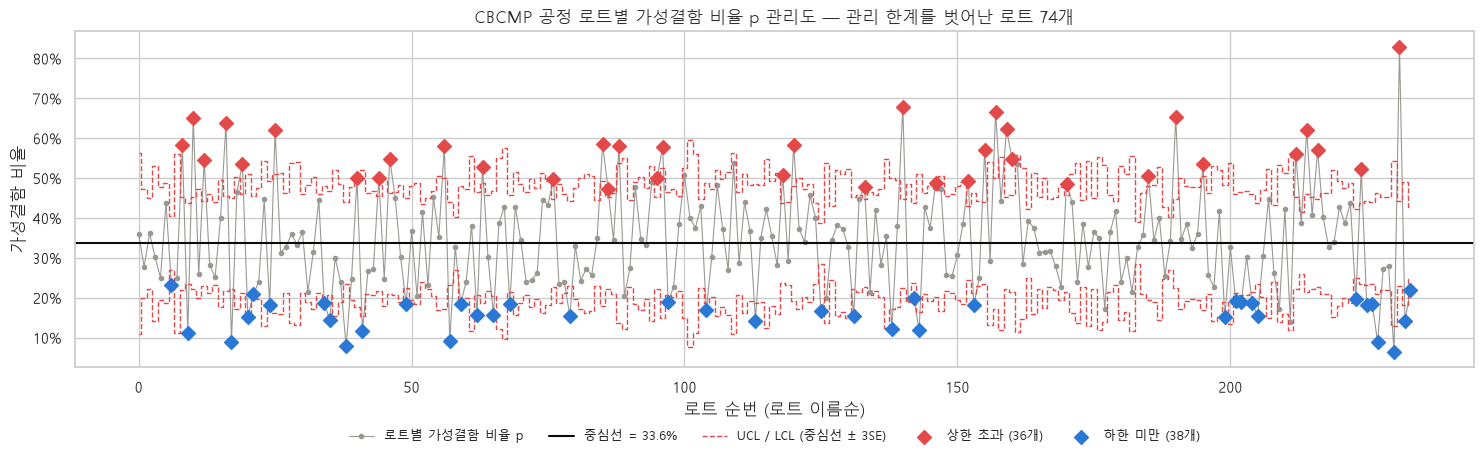

#### 심화 해설 · p 관리도에서 말할 수 있는 것과 없는 것

**① 분석 목적**

탐색용 한계선과 실제 공정 관리의 전제조건을 구별합니다.

**② 개념을 먼저 이해하기**

p 관리도는 부분집단 안의 이항 비율을 비교합니다. 중심선은 비율의 단순평균이 아니라 전체 해당 건수/전체 관측 수입니다.
분모 n이 작을수록 한계 폭 3√(p̄(1−p̄)/n)이 넓어집니다. 한계는 0~1로 제한합니다.
이 파일의 로트 이름 정렬은 시간 순서가 아닙니다. 따라서 추세·런 규칙·공정 악화 시점을 해석할 수 없습니다.
동일 웨이퍼 내 상관, 공정 구성 차이, 과산포가 있으면 이항 한계가 너무 좁을 수 있습니다.
규격 한계는 제품 요구조건, 관리 한계는 안정된 공정 변동 기준으로 서로 다릅니다.

,n,가성수,p,LCL,UCL,관리이탈
Lot_Name,,,,,,
F03W9.1,30,12,0.4000,0.0777,0.5953,
F03F8.1,35,15,0.4286,0.0969,0.5761,
A1VWN.1,39,14,0.3590,0.1095,0.5635,
F040W.1,39,21,0.5385,0.1095,0.5635,
F03X5.1,40,15,0.3750,0.1124,0.5606,


분모 최소/최대: 30 781
탐색 한계 밖 로트 수: 74
n*p_bar < 5 로트 수: 0
n*(1-p_bar) < 5 로트 수: 0


**③ 표·그래프 읽는 순서**

작은 n의 로트에서 LCL과 UCL 간격이 넓은지 봅니다. 한계 밖 점은 조사 후보이며 원인 확정이 아닙니다.

**④ 결과 해석과 한계**

기준기간을 별도로 정하지 않고 같은 데이터로 중심과 한계를 계산한 탐색 예제입니다. 운영 관리도에는 시간, 합리적인 부분집단, 안정 기준기간, 검사 조건 확인이 필요합니다.

> **Q7 해석**
> - 분모가 작은 로트의 한계는 넓고 큰 로트의 한계는 좁습니다.
> - 실제 한계 밖 로트 수는 위 출력에서 확인합니다. 이는 독립 이항·공통 비율 가정 아래의 탐색 후보입니다.
> - 로트 간 차이뿐 아니라 웨이퍼 내 상관, 과산포, 검사 구성 차이도 이탈을 늘릴 수 있습니다. 3σ 바깥 약 0.27%라는 정규 근사 수치를 이 자료에 곧바로 적용하면 안 됩니다.
> - 검사 시간과 안정 기준기간이 없으므로 공정이 악화되었다거나 원인이 설비라고 단정할 수 없습니다. 검사 이력 확인이 다음 단계입니다.

---

## 8장. 정리 & 연습문제

> **이 장의 목표**
> - 분석 결과를 요약 리포트로 정리할 수 있다.
> - 직접 프롬프트를 작성해서 새로운 분석을 수행할 수 있다.

### 8-1. EDA 인사이트 요약 리포트

**실습 프롬프트 P87**

> 지금까지 계산한 변수(df, key, step_summary, zone, wafer, sep, lot, p_bar)를 활용해서
>
> EDA 요약 리포트를 텍스트로 출력해줘. 구분선(=, -)으로 섹션을 나누고 다음 내용을 포함해줘.
> - 데이터 규모(결함 수, 웨이퍼 수, 로트 수, 공정 수)와 품질(결측치, 완전중복, 키중복)
> - 전체 진성/가성 비율, PC 공정의 가성결함 비율
> - SIZE_D의 왜도와 중앙값
> - 영역별 면적 보정 밀도(중심, 가장자리)와 진성비율 변화
> - 결함 과다 웨이퍼 수, REAL/FALSE 구분력 상위 3개 변수, 관리도 이탈 로트 수
> - 마지막에 개선 제안 2~3줄
>
> 숫자는 하드코딩하지 말고 변수에서 계산해서 넣어줘.

반도체 웨이퍼 결함 데이터 EDA 요약
 데이터 : 결함 63,908개 · 웨이퍼 1,092장 · 로트 457개 · 공정 3개
 품질   : 결측치 0, 완전중복 0, 키중복 21건(원인 미확인·유지)
----------------------------------------------------------------------------
 ① 전체 검출 결함 중 진성결함 56.1%, 가성결함 43.9%
 ② 공정별 차이 큼 : PC 공정은 가성결함 비율 67%
 ③ 결함 크기는 심한 우편향(왜도 26) → 중앙값 0.199µm로 요약
 ④ 기하 면적당 누적 기록 수는 중심 108·가장자리 116개/cm²의 U자형,
    진성비율은 중심 62% → 가장자리 49%로 바깥일수록 낮음
 ⑤ 결함 기록 과다 그룹 1개 — 검사 이력 확인 필요
 ⑥ REAL/FALSE 구분력 최상위 변수 : RELATIVEMAGNITUDE (log), INTENSITY (log), MDAT_OFFSET (log)
 ⑦ CBCMP p 관리도 : 로트 234개 중 74개가 관리 한계 이탈 (p̄ = 33.6%)
----------------------------------------------------------------------------
제안 : 가장자리 영역 검사 민감도 재조정, PC 공정 검사 레시피 점검,
          관리 이탈 로트 이력 조사, 신호 계열 변수 중심으로 가성결함 자동 분류 모델 개발


#### 심화 해설 · 관찰 → 가능한 설명 → 확인할 자료로 보고하기

**① 분석 목적**

분석 결과를 원인 단정이나 성급한 현장 조치로 바꾸지 않고 전달합니다.

**② 개념을 먼저 이해하기**

좋은 보고서는 대상, 기간, 분모, 단위, 수치, 한계를 포함합니다. 이 파일에는 검사 시간이 없어 기간별 변화는 말할 수 없습니다.
“관찰”은 직접 계산한 사실, “해석 가설”은 가능한 이유, “다음 확인”은 가설을 검증할 데이터입니다.
기존 요약의 레시피 점검·민감도 재조정 제안은 즉시 변경 지시가 아니라 추가 조사 후보로 읽습니다.

,기록수,진성수,진성비율,크기평균,크기중앙값,크기Q1,크기Q3
Step_desc,,,,,,,
CBCMP,28072,18624,0.6634,0.2376,0.1490,0.0520,0.2480
PC,8852,2908,0.3285,0.9429,0.2620,0.1490,0.4190
RMG,26984,14316,0.5305,0.3839,0.2650,0.1990,0.3980


**CBCMP**: 검출 후보 28,072건 중 REAL은 66.34%. 크기 중앙값은 0.149 µm, 가운데 50%는 0.052~0.248 µm입니다.

**PC**: 검출 후보 8,852건 중 REAL은 32.85%. 크기 중앙값은 0.262 µm, 가운데 50%는 0.149~0.419 µm입니다.

**RMG**: 검출 후보 26,984건 중 REAL은 53.05%. 크기 중앙값은 0.265 µm, 가운데 50%는 0.199~0.398 µm입니다.

**③ 표·그래프 읽는 순서**

PC 평균 약 0.943µm, RMG 약 0.384µm, CBCMP 약 0.238µm를 중앙값 0.262·0.265·0.149µm와 비교합니다. 평균과 중앙값의 공정 순위가 다릅니다.

**④ 결과 해석과 한계**

PC의 평균이 크다고 전형적인 결함도 항상 가장 크다고 말할 수 없습니다. 꼬리, 검출 기준, 공정별 구성을 함께 조사합니다. 이 자료만으로 인과관계나 공정 개선 효과를 입증하지 않습니다.

### 8-2. 핵심 개념 정리표

| 장 | 꼭 기억할 것 |
|---|---|
| **데이터 구조** | 행 = 관측치, 열 = 변수. **변수 유형·측정 척도가 통계·그래프를 결정** |
| **판다스** | `head·info·describe` → `loc/iloc` → 조건 필터링 → `value_counts` → `groupby` |
| **전처리** | 결측·중복·자료형·타당성·이상치 점검. **이상치는 지우기 전에 이해하기** |
| **도수분포** | 구간·도수·상대도수·누적도수. 히스토그램 = 도수분포표의 그림 |
| **중심경향** | 치우친 데이터의 대표값은 **중앙값**. 그룹 비율을 합칠 땐 **가중평균** |
| **산포도** | 단위가 다르면 **CV**, 이상치가 많으면 **IQR·MAD** |
| **분포 형태** | 왜도 > 1이면 심한 치우침 → 로그 변환. **Q-Q plot**으로 정규성 눈으로 확인 |
| **경험적 규칙 vs 체비쇼프** | 68-95-99.7은 정규분포에만, 체비쇼프(75%, 88.9%)는 모든 분포에 |
| **관계** | 상관 ≠ 인과. r은 **직선 관계만** 측정 → 산점도 필수. 치우치면 **스피어만** |
| **비율 비교** | **%와 %p 구분**, 교차표는 normalize 방향에 따라 질문이 다름 |
| **표준오차** | $SE = \sigma/\sqrt{n}$ — n이 작으면 평균이 흔들림. **n을 함께 보고** |
| **관리도** | 중심선 ± 3SE. 기초통계로 만드는 제조 품질 감시 도구 |
| **EDA** | 질문 → 단변량 → 이변량 → 다변량 → 해석 → 새 질문 (**반복**) |
| **바이브코딩** | **맥락·작업·조건·출력**으로 프롬프트 작성, AI 코드는 **반드시 검증** |

### 8-3. 연습문제 — 이번엔 프롬프트를 직접 써보세요!

> 각 문제마다 **① 프롬프트 작성 칸**에 맥락·작업·조건·출력을 갖춘 프롬프트를 쓰고, AI가 만든 코드를 **② 코드 칸**에 붙여 실행하세요.

| # | 영역 | 문제 |
|:---:|---|---|
| 1 | 판다스 | RMG 공정에서 `SIZE_D`가 상위 1%인 결함은 몇 개이고, 그중 진성결함 비율은? |
| 2 | 기술통계 | `MDAT_NOISE`의 평균, 중앙값, 표준편차, IQR, MAD, 변동계수, 왜도를 구하고 분포 모양을 한 문장으로 설명 |
| 3 | 도수분포 | `SPOTLIKENESS`의 도수분포표(2 간격)를 만들고, 중앙값이 속한 구간을 찾기 |
| 4 | 교차표 | `POLARITY` × `IS_DEFECT` 교차표를 행 기준 비율로 만들고, 가장 가성비율이 높은 극성과의 %p 차이를 계산 |
| 5 | 시각화 | `ZONE`별 `INTENSITY` 분포를 `IS_DEFECT`로 색을 나눈 박스플롯으로 그리고, 제목에 결론 쓰기 |
| 6 | 관리도 | RMG 공정으로 로트별 가성결함 비율 p 관리도를 그리고, 이탈 로트 수를 CBCMP와 비교 |

**연습문제 1 — RMG 상위 1% 결함 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[조건]
[출력]
```

**연습문제 2 — MDAT_NOISE 기술통계 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[조건]
[출력]
```

**연습문제 3 — SPOTLIKENESS 도수분포표 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[조건]
[출력]
```

**연습문제 4 — POLARITY 교차표 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[조건]
[출력]
```

**연습문제 5 — ZONE별 INTENSITY 박스플롯 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[조건]
[출력]
```

**연습문제 6 — RMG p 관리도 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[조건]
[출력]
```

---
<details>
<summary><b>연습문제 예시 프롬프트 & 답안 (클릭하여 펼치기)</b></summary>

**1. 예시 프롬프트** : "`df`에서 Step_desc가 'RMG'인 행만 골라서, SIZE_D가 그 안에서 99번째 백분위수 이상인 결함 수와 그 결함들의 is_real 평균(진성결함 비율)을 출력해줘."
```python
rmg = df[df["Step_desc"] == "RMG"]
top1 = rmg[rmg["SIZE_D"] >= rmg["SIZE_D"].quantile(0.99)]
print(len(top1), top1["is_real"].mean())
```

**2.**
```python
dispersion(df["MDAT_NOISE"]).to_frame().T.assign(중앙값=df["MDAT_NOISE"].median(), 왜도=df["MDAT_NOISE"].skew())
```

**3.**
```python
g = pd.cut(df["SPOTLIKENESS"], bins=np.arange(0, 34, 2), right=False)
t = g.value_counts().sort_index().to_frame("도수")
t["누적상대도수(%)"] = t["도수"].cumsum() / len(df) * 100
t[t["누적상대도수(%)"] >= 50].head(1)     # 중앙값이 속한 구간
```

**4.**
```python
ct = pd.crosstab(df["POLARITY"], df["IS_DEFECT"], normalize="index") * 100
ct["최대 대비 차이(%p)"] = ct["FALSE"] - ct["FALSE"].max()
ct.round(1)
```

**5.**
```python
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x="ZONE", y="INTENSITY", hue="IS_DEFECT", hue_order=["FALSE", "REAL"],
            palette=PAL_DEFECT, showfliers=False)
plt.title("모든 영역에서 진성결함의 신호 세기가 더 크다"); plt.show()
```

**6.** Q7 코드에서 `"CBCMP"`를 `"RMG"`로 바꾸어 실행
</details>

---

#### 수고하셨습니다!
**다음 단계** : 추론통계(신뢰구간·가설검정) → 머신러닝 분류 모델로 **가성결함 자동 판별** 도전!

---

## 추가 실습 — 정답보다 해석을 연습하기

각 문제는 먼저 분모와 분석 단위를 적고 풀어보세요. 아래 실행 답안으로 수치를 확인한 뒤 자신의 문장을 비교하세요.

1. RMG 공정의 SIZE_D 상위 1% 경계는 얼마이며, **경계를 초과하는** 기록은 몇 개인가? 그 안의 REAL 비율은?
2. MDAT_NOISE의 평균·중앙값·SD·IQR·MAD를 계산하라. SD와 SE 중 개별 값의 퍼짐을 나타내는 것은?
3. POLARITY별 FALSE 비율과 분모를 함께 보고하라. 비율 최대 집단과 최소 집단 차이를 %p로 표현하라.
4. 공정별 SIZE_D 평균 순위와 중앙값 순위가 같은가? 다른 경우 어떤 그림을 추가하겠는가?
5. 키 중복이 발견되었다. “재검사다”라고 결론 내려도 되는가? 추가로 필요한 열 두 가지를 적어라.
6. 가장자리 기록 수가 많다. 실제 결함 밀도가 높다고 결론 내리려면 어떤 분모가 필요한가?
7. 로트 이름순 관리도에서 점이 연속 상승한다. 시간에 따른 악화라고 말할 수 있는가?
8. 한 변수의 REAL/FALSE 평균차가 크다. 이를 모델 정확도로 보고할 수 있는가?

1. RMG 99백분위수=2.3890 µm, 초과=262건, REAL=85.50%


평균    236.1825
중앙값   196.0000
SD    185.8009
IQR   158.0000
MAD    71.0000
Name: 2. MDAT_NOISE, dtype: float64

,n,FALSE수,FALSE비율
POLARITY,,,
-1,16689,6502,0.3896
0,73,54,0.7397
1,47146,21504,0.4561


3. 최대-최소 차이=35.01%p


,mean,median,평균순위,중앙값순위
Step_desc,,,,
CBCMP,0.2376,0.1490,3.0000,3.0000
PC,0.9429,0.2620,1.0000,2.0000
RMG,0.3839,0.2650,2.0000,1.0000


**서술형 답안 및 채점 기준**

- 2번: SD가 개별 관측의 퍼짐입니다. SE는 평균 추정의 흔들림입니다.
- 4번: PC 평균은 가장 크지만 중앙값은 RMG보다 작습니다. 동일 축의 공정별 ECDF·로그 히스토그램·상자그림으로 꼬리와 중심을 함께 봅니다.
- 5번: 단정할 수 없습니다. 검사 ID·검사 시간·장비·재검사 여부 등의 이력이 필요합니다. 키 중복 수와 관련 전체 행 수도 구별합니다.
- 6번: 실제 검사 면적×검사 노출 횟수에 해당하는 분모가 필요합니다. 무검출 웨이퍼와 가장자리 제외 영역도 확인해야 합니다.
- 7번: 이름순은 시간순이 아니므로 시간 추세라고 해석할 수 없습니다.
- 8번: 그룹 차이는 기술통계입니다. 새 데이터에서의 예측 성능 검증은 4일차에서 수행합니다.

각 답안에서 **분모·단위·수치·한계**를 하나씩 확인하세요. 수치가 맞아도 분모나 원인 해석이 틀리면 올바른 분석이 아닙니다.

### 스스로 작성하는 분석 보고서 틀

> 분석 질문: ___  
> 분석 단위와 분모: ___  
> 데이터 품질 점검과 유지·제외 기준: ___  
> 관찰한 수치(단위, n 포함): ___  
> 그래프의 축·표시 범위·제외된 행: ___  
> 가능한 설명: ___  
> 현재 자료만으로 말할 수 없는 것: ___  
> 다음에 확인할 자료: ___

### 최종 검산

아래 검산은 전체 기록 수, 그룹별 집계 합, 가중비율 일치, 원본 보존을 확인합니다.
외부 데이터에 대한 고정 정답 검사가 아니라 이 실습 내부의 계산 일관성을 확인하는 과정입니다.

검산 완료: 기록 수·분모·그룹 합계·원본 데이터 일치
